# Homes on Dangerous Streets?
## Linking NYC Affordable Housing Production to Motor Vehicle Collisions

**Data Engineering and Visualization — Winter Semester 2026 — Project Milestone 1**<br>
German International University · Faculty of Informatics and Computer Science<br>
Instructor: Dr. Nada Sharaf · TAs: Mariam Ali, May Magdy, Mohamed El Dagla<br>
Submission deadline: **9 November 2026**

## Team

| # | Name | Tutorial | Student ID | Email |
|---|------|----------|-----------|-------|
| 1 | Ahmed Saadallah | P5 | 16008325 | ahmed.saadallah@student.giu-uni.de |
| 2 | Ismail Ahmed Mohamed | P10 | 16002979 | Ismail.khalifa@student.giu-uni.de |
| 3 | Ziad Elshayeb | P6 | 16002080 | ziad.elshayeb@student.giu-uni.de |
| 4 | Renad Osama | P6 | 16001737 | rinad.atef@student.giu-uni.de |
| 5 | Yassin Amr | P5 | 16005309 | Yassin.zaki@student.giu-uni.de |
| 6 | Yassin Elazab | P10 | 16006124 | Yassin.walid@student.giu-uni.de |

Team size: **6 members → 12 research questions + 12 visualizations** (2 per member).
A detailed per-member contribution table (research questions, visualizations, cleaning tasks, integration, website components) is given in **Section 10**.

## The Question Behind the Project

Since 2014, New York City has counted more than 300,000 new and preserved affordable homes toward its housing
plans (320,946 units in this dataset), many of them reserved for households earning only a small fraction of the
Area Median Income. At the same time, traffic crashes injure
tens of thousands of New Yorkers every year — disproportionately pedestrians and cyclists, who are more likely
to be people without a car.

**Main question:** *Are New York's newest affordable homes — and especially those reserved for the lowest-income
households — being built on the city's most dangerous streets, and does street safety around them change once
residents move in?*

**Why it matters to New Yorkers:** households in deeply affordable units are more likely to walk, bike, and ride
transit rather than drive. If affordable housing is concentrated where crash risk is highest, the people with the
fewest alternatives carry the most exposure. Answering this can help **HPD** (housing), **NYC DOT / Vision Zero**
(street safety), and **housing advocates** decide where street-safety investment should accompany new housing.

> The 12 member research questions (Section 8) each examine one angle of this question; Section 9 brings the
> answers together.

## Chosen Datasets

| Domain | Catalog ID | Dataset | NYC Open Data ID | Link | Columns |
|---|---|---|---|---|---|
| Housing & Development | H2 | Affordable Housing Production by Building | `hg8x-zxpr` | https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr | 41 |
| Transportation | T4 | Motor Vehicle Collisions – Crashes | `h9gi-nx95` | https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95 | 29 |

Both datasets are taken from the project's recommended catalog, so no external feasibility check is required.
A full dataset overview (row counts, geographic/temporal attributes, known issues, selection reasoning, and the
aggregation strategy) is given in **Section 2**.

**Shared integration attributes**

| Attribute | Housing (H2) | Collisions (T4) |
|---|---|---|
| Coordinates | `latitude`, `longitude` | `latitude`, `longitude` |
| ZIP code | `postcode` | `zip_code` |
| Borough | `borough` | `borough` |
| Time | `project_start_date`, `project_completion_date`, `building_completion_date` | `crash_date`, `crash_time` |

## Notebook Roadmap

| Section | Content |
|---|---|
| 1 | Setup — libraries, configuration, helper constants |
| 2 | Dataset overview & loading — size, attributes, known issues, selection reasoning, sampling justification |
| 3 | Exploratory Data Analysis (EDA) — descriptive statistics and initial plots for each dataset |
| 4 | Pre-integration cleaning — missing values, outliers, inconsistencies, format standardization, duplicates |
| 5 | Integration — ZIP × year aggregation and spatial-proximity (buffer) join, with justification of keys and granularity |
| 6 | Post-integration cleaning — join-induced missing values, redundant columns, type mismatches |
| 7 | Integrated-data validation — sanity checks on the joined tables |
| 8 | Research questions & visualizations — 12 questions, 2 per member |
| 9 | The data story — question, discoveries, limitations, impact |
| 10 | Member contributions |
| 11 | Prompts used & dataset links |
| 12 | Decision register — every decision and the alternatives considered |

Every analytical decision is highlighted where it is made, in a box starting with **Decision —**, which also lists
the alternatives that were considered and why they were rejected.

---
# 1. Setup

All libraries used in the notebook are imported here once. The notebook is designed to run top-to-bottom in
**Google Colab** or a local Jupyter environment (Python ≥ 3.10).

Global constants (dataset IDs, the analysis period, file paths, NYC bounding box) are defined in one place so
that every later section uses the same values and the analysis is reproducible.

In [1]:
# --- Core libraries ---
import os
import warnings

import numpy as np
import pandas as pd

# --- Visualization libraries ---
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# --- Display settings ---
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 2.2.3 | numpy 2.1.3 | seaborn 0.13.2


In [2]:
# --- Dataset identifiers (from each dataset's NYC Open Data URL) ---
HOUSING_ID = "hg8x-zxpr"     # H2: Affordable Housing Production by Building
COLLISIONS_ID = "h9gi-nx95"  # T4: Motor Vehicle Collisions - Crashes

DATASET_LINKS = {
    "housing": f"https://data.cityofnewyork.us/d/{HOUSING_ID}",
    "collisions": f"https://data.cityofnewyork.us/d/{COLLISIONS_ID}",
}

# --- Analysis period ---
# The affordable-housing dataset starts with projects from 2014 (the start of the city's
# "Housing New York" plan), so collisions are restricted to the same period.
ANALYSIS_START_YEAR = 2014

# --- NYC geographic bounding box (used later to flag impossible coordinates) ---
NYC_BOUNDS = {"lat_min": 40.49, "lat_max": 40.92, "lon_min": -74.27, "lon_max": -73.68}

# --- File paths ---
RAW_DIR = "data/raw"
PROCESSED_DIR = "data/processed"
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Configuration loaded.")
for name, url in DATASET_LINKS.items():
    print(f"  {name:<11}: {url}")

Configuration loaded.
  housing    : https://data.cityofnewyork.us/d/hg8x-zxpr
  collisions : https://data.cityofnewyork.us/d/h9gi-nx95


---
# 2. Dataset Overview & Loading

## 2.1 Loading strategy

Both datasets are loaded through the **NYC Open Data SODA API** (`/resource/<id>.csv`), as suggested in the project
description (Listing 2). Using the API rather than the bulk CSV export gives us three advantages:

1. **Consistent column names** — the API returns machine-readable field names (lower-case, underscores) for both
   datasets, so the same naming style is used throughout the notebook.
2. **Server-side filtering** — the collisions dataset has millions of rows. Filtering on the server avoids
   downloading records we cannot use (see 2.2).
3. **Verifiable completeness** — we ask the API how many rows match our filter (`count(*)`) *before* downloading
   and check that exactly that many rows arrived.

**Raw snapshot rule:** every column is downloaded **as text** (`dtype=str`). This keeps the raw data exactly as
published — no silent type conversion by pandas (e.g., ZIP codes turning into floats, or malformed dates becoming
`NaN` without a trace). Type conversion is done deliberately and documented in Section 4 (*standardize formats*).

**Caching:** after the first download the raw data is saved as Parquet files. Later runs (or teammates' runs) load
the saved files instead of downloading again, which makes the notebook fast and guarantees that everyone analyzes
the **same snapshot** of the data. Delete the files to force a fresh download.

> **Decision — download through the API, page by page, and verify the row count.**
> *Alternatives considered:* the bulk CSV export (Listing 1 of the project description).
> *Why:* the bulk export cannot filter, uses different column names, and gives no completeness check.

> **Decision — keep every raw column as text.**
> *Alternatives considered:* let pandas infer the types while reading.
> *Why:* inference silently damages values (ZIP codes as floats, malformed dates as missing); conversion is done
> explicitly in Section 4, where it is visible and logged.

## 2.2 Why the collisions dataset is filtered

The Motor Vehicle Collisions – Crashes dataset starts in **July 2012** and contains millions of crashes. We download
only crashes **from 1 January 2014 onwards**, for two reasons:

* **Temporal alignment with the housing data.** The Affordable Housing Production dataset covers projects counted
  under the city's housing plans **starting in 2014**. Crashes before 2014 could never be matched to a housing year,
  so they would add size without adding any analytical value.
* **Feasibility.** Restricting the period reduces memory use in Colab while keeping **every** crash in the analysis
  window — this is a *filter*, not a random sample, so no crash inside the study period is lost and no sampling bias
  is introduced.

All 29 columns are kept at this stage; columns are only removed during cleaning, with a justification.

> **Decision — filter crashes to 2014 onwards, keeping every crash in that period.**
> *Alternatives considered:* a random sample of all years; downloading the full history.
> *Why:* a sample would lose crashes and add sampling noise to small areas; years before 2014 can never be matched
> to housing data.

### Storage location

In Google Colab, files saved in the session disappear when the runtime restarts. The next cell (optional, Colab only)
mounts Google Drive so the downloaded data is stored permanently and can be shared by all team members.
Outside Colab, the local `data/` folder is used.

> **Decision — store the raw snapshot on Google Drive.**
> *Alternatives considered:* keep files only in the Colab session.
> *Why:* session files are deleted on restart; Drive keeps one shared snapshot for all six team members.

In [3]:
# --- Choose where data files are stored ---
# In Colab we store data on Google Drive so it survives runtime restarts and can be shared by the team.
# Set USE_GOOGLE_DRIVE = False to keep files only in the current Colab session.
USE_GOOGLE_DRIVE = True

try:
    from google.colab import drive  # only available inside Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_GOOGLE_DRIVE:
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/nyc-housing-transport"
else:
    PROJECT_DIR = "."

RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

HOUSING_RAW_PATH = os.path.join(RAW_DIR, "housing_raw.parquet")
COLLISIONS_RAW_PATH = os.path.join(RAW_DIR, "collisions_raw.parquet")

print(f"Running in Colab: {IN_COLAB}")
print(f"Raw data folder : {RAW_DIR}")

Mounted at /content/drive
Running in Colab: True
Raw data folder : /content/drive/MyDrive/nyc-housing-transport/data/raw


### Download helpers

Three small functions handle all API access:

* `socrata_count` — asks the API how many rows match a filter (used to verify completeness).
* `download_socrata` — downloads a dataset **page by page** (the API returns at most the `$limit` rows per request),
  ordered by the internal row id `:id` so that pages never overlap or skip rows.
* `load_or_download` — loads the cached Parquet file if it exists, otherwise downloads and caches it.

In [4]:
import io
import time
import requests
from urllib.parse import urlencode

SODA_URL = "https://data.cityofnewyork.us/resource/{}.csv"


def _get_csv(dataset_id, params, retries=3, timeout=300):
    # Send one SODA API request and return the CSV response as a DataFrame (all columns as text).
    # Retries a few times because large public-API requests occasionally time out.
    url = SODA_URL.format(dataset_id) + "?" + urlencode(params)
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, timeout=timeout)
            response.raise_for_status()
            if not response.text.strip():  # an empty page (no header) means no more rows
                return pd.DataFrame()
            return pd.read_csv(io.StringIO(response.text), dtype=str, keep_default_na=False, na_values=[""])
        except requests.RequestException as error:
            if attempt == retries:
                raise
            print(f"    request failed ({error}); retrying in {5 * attempt}s ...")
            time.sleep(5 * attempt)


def socrata_count(dataset_id, where=None):
    # Return the number of rows in a dataset that satisfy an optional SoQL WHERE clause.
    params = {"$select": "count(*) AS n"}
    if where:
        params["$where"] = where
    return int(_get_csv(dataset_id, params)["n"].iloc[0])


def download_socrata(dataset_id, where=None, page_size=250_000):
    # Download all rows matching `where`, page by page.
    # Ordering by the internal row id (:id) gives a stable order, so consecutive pages
    # (offset 0, page_size, 2*page_size, ...) never overlap and never skip rows.
    pages, offset = [], 0
    while True:
        params = {"$limit": page_size, "$offset": offset, "$order": ":id"}
        if where:
            params["$where"] = where
        page = _get_csv(dataset_id, params)
        pages.append(page)
        offset += len(page)
        print(f"    downloaded {offset:,} rows")
        if len(page) < page_size:  # last (partial) page reached
            break
    return pd.concat(pages, ignore_index=True)


def load_or_download(dataset_id, cache_path, where=None):
    # Load the cached raw snapshot if present; otherwise download, verify completeness, and cache it.
    if os.path.exists(cache_path):
        print(f"Loading cached snapshot: {cache_path}")
        return pd.read_parquet(cache_path)

    expected_rows = socrata_count(dataset_id, where)
    print(f"Downloading {dataset_id}: {expected_rows:,} rows expected")
    df = download_socrata(dataset_id, where)

    # Completeness check: the number of downloaded rows must equal the server-side count.
    assert len(df) == expected_rows, f"Expected {expected_rows:,} rows but received {len(df):,}"
    df.to_parquet(cache_path, index=False)
    print(f"Saved snapshot to {cache_path}")
    return df

### Loading the housing dataset (H2)

The housing dataset is small (thousands of buildings), so it is downloaded in full with no filter.

In [5]:
df_housing_raw = load_or_download(HOUSING_ID, HOUSING_RAW_PATH)
print(f"\nHousing raw shape: {df_housing_raw.shape[0]:,} rows x {df_housing_raw.shape[1]} columns")
df_housing_raw.head()

Loading cached snapshot: /content/drive/MyDrive/nyc-housing-transport/data/raw/housing_raw.parquet

Housing raw shape: 9,551 rows x 41 columns


,project_id,project_name,project_start_date,project_completion_date,building_id,house_number,street_name,borough,postcode,bbl,bin,community_board,council_district,census_tract,neighborhood_tabulation_area,latitude,longitude,latitude_internal,longitude_internal,building_completion_date,reporting_construction_type,extended_affordability_status,prevailing_wage_status,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units,studio_units,_1_br_units,_2_br_units,_3_br_units,_4_br_units,_5_br_units,_6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,None,991637,177-06,WEXFORD TERRACE,Queens,11432,4098350023,4000000,QN-08,24,466,QN06,40.713096,-73.786005,40.712656,-73.786724,None,New Construction,No,Non Prevailing Wage,None,None,9,None,None,None,None,9,None,None,None,None,None,None,9,None,9,43
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,None,1021347,819,GRAND STREET,Brooklyn,11211,3029220001,3070436,BK-01,34,481,BK90,40.71205,-73.94036,40.712272,-73.940295,None,New Construction,No,Prevailing Wage,186,None,None,None,None,1,92,95,None,None,None,None,None,None,187,None,187,187
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,None,21199,127,EDGECOMBE AVENUE,Manhattan,10030,1020480037,1060911,MN-10,9,22102,MN03,40.820728,-73.945285,40.820766,-73.945581,None,Preservation,No,Non Prevailing Wage,12,13,None,None,None,None,None,5,20,None,None,None,None,None,25,None,25,25
3,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,None,28145,602,ST NICHOLAS AVENUE,Manhattan,10030,1020480047,1060920,MN-10,9,22102,MN03,40.820717,-73.946322,40.820591,-73.946058,None,Preservation,No,Non Prevailing Wage,6,9,None,None,None,1,1,10,5,None,None,None,None,None,16,None,16,16
4,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,None,40555,129,WEST 133 STREET,Manhattan,10030,1019180018,1058219,MN-10,9,226,MN03,40.813338,-73.943026,40.813568,-73.943011,None,Preservation,No,Non Prevailing Wage,5,10,None,None,None,None,1,4,6,4,None,None,None,None,15,None,15,15


### Loading the collisions dataset (T4)

Before downloading, we record the size of the **full** dataset and of the **filtered** period so the effect of the
filter is documented. The first download takes a few minutes; later runs load the cached file in seconds.

In [6]:
# SoQL filter: only crashes from the start of the analysis period onwards (see 2.2)
COLLISIONS_WHERE = f"crash_date >= '{ANALYSIS_START_YEAR}-01-01T00:00:00'"

collisions_total_rows = socrata_count(COLLISIONS_ID)
collisions_period_rows = socrata_count(COLLISIONS_ID, COLLISIONS_WHERE)
print(f"Full collisions dataset     : {collisions_total_rows:,} rows")
print(f"Crashes since {ANALYSIS_START_YEAR}-01-01   : {collisions_period_rows:,} rows "
      f"({collisions_period_rows / collisions_total_rows:.1%} of the dataset)\n")

df_collisions_raw = load_or_download(COLLISIONS_ID, COLLISIONS_RAW_PATH, where=COLLISIONS_WHERE)
print(f"\nCollisions raw shape: {df_collisions_raw.shape[0]:,} rows x {df_collisions_raw.shape[1]} columns")
df_collisions_raw.head()

Full collisions dataset     : 2,269,187 rows
Crashes since 2014-01-01   : 1,964,900 rows (86.6% of the dataset)

Loading cached snapshot: /content/drive/MyDrive/nyc-housing-transport/data/raw/collisions_raw.parquet

Collisions raw shape: 1,964,900 rows x 29 columns


,crash_date,crash_time,borough,zip_code,latitude,longitude,location,on_street_name,off_street_name,cross_street_name,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed,contributing_factor_vehicle_1,contributing_factor_vehicle_2,contributing_factor_vehicle_3,contributing_factor_vehicle_4,contributing_factor_vehicle_5,collision_id,vehicle_type_code1,vehicle_type_code2,vehicle_type_code_3,vehicle_type_code_4,vehicle_type_code_5
0,2021-04-13T00:00:00.000,0:00,BROOKLYN,11222,40.7264440,-73.9523300,"(40.726444, -73.95233)",None,None,745 MANHATTAN AVENUE,0,0,0,0,0,0,0,0,Passing Too Closely,Unspecified,None,None,None,4406876,AMBULANCE,Van,None,None,None
1,2021-04-13T00:00:00.000,0:00,BROOKLYN,11231,40.6785240,-74.0021000,"(40.678524, -74.0021)",None,None,667 HENRY STREET,0,0,0,0,0,0,0,0,Unspecified,None,None,None,None,4407150,Station Wagon/Sport Utility Vehicle,None,None,None,None
2,2021-04-13T00:00:00.000,0:00,QUEENS,11420,40.6774980,-73.8276000,"(40.677498, -73.8276)",111 STREET,ROCKAWAY BOULEVARD,None,0,0,0,0,0,0,0,0,Other Vehicular,Following Too Closely,None,None,None,4406940,Bus,Station Wagon/Sport Utility Vehicle,None,None,None
3,2021-04-13T00:00:00.000,0:00,None,None,None,None,None,ALEXANDER HAMILTON BRIDGE,None,None,0,0,0,0,0,0,0,0,Following Too Closely,Unspecified,None,None,None,4407166,Tractor Truck Gasoline,Tractor Truck Gasoline,None,None,None
4,2021-04-13T00:00:00.000,0:00,None,None,40.8772350,-73.9178100,"(40.877235, -73.91781)",JOHNSON AVENUE,None,None,0,0,0,0,0,0,0,0,Unspecified,None,None,None,None,4406935,Sedan,None,None,None,None


### Snapshot record

Open-data portals are updated continuously, so the exact numbers in this notebook depend on the download date.
The cell below records the snapshot (date, size, and columns) that every result in this notebook is based on.

In [7]:
snapshot_info = pd.DataFrame({
    "dataset": ["Affordable Housing Production by Building", "Motor Vehicle Collisions - Crashes"],
    "id": [HOUSING_ID, COLLISIONS_ID],
    "rows": [len(df_housing_raw), len(df_collisions_raw)],
    "columns": [df_housing_raw.shape[1], df_collisions_raw.shape[1]],
    "snapshot_file_date": [
        pd.Timestamp(os.path.getmtime(HOUSING_RAW_PATH), unit="s").strftime("%Y-%m-%d"),
        pd.Timestamp(os.path.getmtime(COLLISIONS_RAW_PATH), unit="s").strftime("%Y-%m-%d"),
    ],
    "file_size_MB": [
        round(os.path.getsize(HOUSING_RAW_PATH) / 1e6, 1),
        round(os.path.getsize(COLLISIONS_RAW_PATH) / 1e6, 1),
    ],
})
snapshot_info

,dataset,id,rows,columns,snapshot_file_date,file_size_MB
0,Affordable Housing Production by Building,hg8x-zxpr,9551,41,2026-10-14,0.800
1,Motor Vehicle Collisions - Crashes,h9gi-nx95,1964900,29,2026-10-14,65.900


## 2.3 Dataset overview

Before exploring the data in depth, we profile every column of both raw datasets: how many values are missing,
how many distinct values each column has, and one example value. This gives a first map of the data's structure
and its quality problems, which Sections 3 and 4 then investigate and fix.

The helper below is reused for both datasets (and again after cleaning, to show the effect of each step).

In [8]:
def column_profile(df):
    # Summarize every column of a DataFrame: missing values (count and %), number of distinct values,
    # and the first non-missing value as an example of what the column contains.
    return pd.DataFrame({
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(1),
        "unique_values": df.nunique(),
        "example": df.apply(lambda col: col.dropna().iloc[0] if col.notna().any() else None),
    })


print(f"Housing: {df_housing_raw.shape[0]:,} rows x {df_housing_raw.shape[1]} columns")
column_profile(df_housing_raw)

Housing: 9,551 rows x 41 columns


,missing,missing_%,unique_values,example
project_id,0,0.000,5928,68872
project_name,0,0.000,3979,177-06 WEXFORD TERRACE
project_start_date,0,0.000,2346,2026-06-30T00:00:00.000
project_completion_date,1819,19.000,2066,2026-06-30T00:00:00.000
building_id,1949,20.400,7478,991637
house_number,0,0.000,3154,177-06
street_name,0,0.000,1567,WEXFORD TERRACE
borough,0,0.000,5,Queens
postcode,1958,20.500,158,11432
bbl,2021,21.200,6423,4098350023


In [9]:
print(f"Collisions: {df_collisions_raw.shape[0]:,} rows x {df_collisions_raw.shape[1]} columns")
column_profile(df_collisions_raw)

Collisions: 1,964,900 rows x 29 columns


,missing,missing_%,unique_values,example
crash_date,0,0.000,4545,2021-04-13T00:00:00.000
crash_time,0,0.000,1440,0:00
borough,620645,31.600,5,BROOKLYN
zip_code,620931,31.600,236,11222
latitude,193919,9.900,185698,40.7264440
longitude,193919,9.900,137361,-73.9523300
location,193919,9.900,393877,"(40.726444, -73.95233)"
on_street_name,455744,23.200,22972,111 STREET
off_street_name,826688,42.100,24840,ROCKAWAY BOULEVARD
cross_street_name,1566266,79.700,265710,745 MANHATTAN AVENUE


### Time coverage

The temporal attributes decide which years the two datasets can be compared on. Dates are still stored as text,
so they are converted here **only to read their range**; the stored columns are not changed until Section 4.

In [10]:
def date_coverage(df, date_columns, dataset_name):
    # Return the first date, last date, and number of missing values for each date column.
    rows = []
    for column in date_columns:
        dates = pd.to_datetime(df[column], errors="coerce")
        rows.append({
            "dataset": dataset_name,
            "date_column": column,
            "first": dates.min().date(),
            "last": dates.max().date(),
            "missing": int(dates.isna().sum()),
        })
    return pd.DataFrame(rows)


time_coverage = pd.concat([
    date_coverage(df_housing_raw,
                  ["project_start_date", "project_completion_date", "building_completion_date"],
                  "Housing"),
    date_coverage(df_collisions_raw, ["crash_date"], "Collisions"),
], ignore_index=True)
time_coverage

,dataset,date_column,first,last,missing
0,Housing,project_start_date,2014-01-03,2026-06-30,0
1,Housing,project_completion_date,2014-01-03,2026-08-11,1819
2,Housing,building_completion_date,2014-01-03,2026-08-21,1666
3,Collisions,crash_date,2014-01-01,2026-06-11,0


In [11]:
# Granularity check: what does one row represent in each dataset?
print("Housing")
print(f"  rows (building records) : {len(df_housing_raw):,}")
print(f"  distinct projects       : {df_housing_raw['project_id'].nunique():,}")
print(f"  distinct building IDs   : {df_housing_raw['building_id'].nunique():,}")
print(f"  'CONFIDENTIAL' records  : {(df_housing_raw['project_name'] == 'CONFIDENTIAL').sum():,}")
print("Collisions")
print(f"  rows (crashes)          : {len(df_collisions_raw):,}")
print(f"  distinct collision IDs  : {df_collisions_raw['collision_id'].nunique():,}")

Housing
  rows (building records) : 9,551
  distinct projects       : 5,928
  distinct building IDs   : 7,478
  'CONFIDENTIAL' records  : 1,949
Collisions
  rows (crashes)          : 1,964,900
  distinct collision IDs  : 1,964,900


### Overview summary

| | **Housing — Affordable Housing Production by Building (H2)** | **Collisions — Motor Vehicle Collisions – Crashes (T4)** |
|---|---|---|
| Link | [hg8x-zxpr](https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr) | [h9gi-nx95](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95) |
| Publisher | NYC Department of Housing Preservation and Development (HPD) | NYPD (police crash reports, form MV104-AN) |
| Rows × columns | 9,551 × 41 (complete dataset) | 1,964,900 × 29 (all crashes since 2014-01-01; 86.6% of 2,269,187) |
| One row = | one **building** within an affordable-housing **project** (5,928 projects) | one police-reported **crash** (`collision_id` unique) |
| Geographic attributes | `borough`, `postcode` (ZIP), `community_board`, `council_district`, `census_tract`, `neighborhood_tabulation_area`, `latitude`/`longitude`, `bbl`, `bin`, address | `borough`, `zip_code`, `latitude`/`longitude`, `location`, street names |
| Temporal attributes | `project_start_date` (2014-01-03 → 2026-06-30), `project_completion_date`, `building_completion_date` (→ 2026-08) | `crash_date` (2014-01-01 → 2026-06-11), `crash_time` |
| Key measures | units by income band (extremely low → middle), units by bedroom size, rental vs homeownership units, total units | persons / pedestrians / cyclists / motorists **injured** and **killed**, contributing factors, vehicle types |
| Key categories | `reporting_construction_type` (New Construction / Preservation), `extended_affordability_status`, `prevailing_wage_status` | contributing factor (66 values), vehicle type (1,905 raw values) |

**Known issues found in the raw data** (each is examined in Section 3 and resolved in Section 4):

*Housing*
* **1,949 confidential records** (20.4%): the publisher withholds the address — house number and street are the
  placeholder `----`, and building ID, BIN, BBL, ZIP code and coordinates are empty. Only borough, community board
  and council district remain.
* **9 further records** lack coordinates and ZIP code, giving **1,958 records (20.5%) that cannot be mapped**.
* **Placeholder BINs**: 482 records use a "million BIN" (e.g., `4000000`), which means *no building number assigned*.
* **Missing completion dates** (19.0% of projects, 17.4% of buildings): mostly projects still under construction —
  a meaningful absence, not an error.
* **Unit-count columns are empty instead of 0**: an explicit `0` never appears in these columns, so an empty value
  means *zero units of that type*.

*Collisions*
* **Missing location**: borough and ZIP code are missing for 31.6% of crashes; coordinates for 9.9%.
* **Impossible coordinates**: 7,590 crashes are placed at (0, 0) and others fall outside New York City.
* **Hidden missing values**: ZIP codes consisting only of spaces, and `Unspecified` as a contributing factor.
* **Mislabelled columns**: the API fields `off_street_name` and `cross_street_name` hold each other's content.
* **Possible duplicates**: 1,590 rows are identical in every column except `collision_id`.
* **Inconsistent categories**: vehicle types have 1,905 raw spellings — an ambulance alone appears as `Ambulance`,
  `AMBULANCE`, `AMBUL`, `ambul`, `AMBULENCE`, `FDNY AMBUL`, and more.
* **Incomplete period at the edges**: 2026 contains only crashes up to June 11, so it is a partial year.

## 2.4 Why these two datasets

We compared all catalog datasets on four criteria: **(1)** strength of the shared geographic and temporal keys,
**(2)** overlap of time periods, **(3)** richness of attributes for twelve different research questions, and
**(4)** feasibility in size and quality.

* **Strongest possible link between domains.** Both datasets carry exact **coordinates**, **ZIP code**, **borough**
  and **dates**. This allows two complementary integrations — an administrative one (ZIP code × year) and a
  precise spatial one (crashes within a fixed distance of each building) — which few other catalog pairs support
  (e.g., Bus Breakdowns has no coordinates; taxi trips use taxi zones instead of ZIP codes; Parking Meters has no
  time dimension).
* **Overlapping time span.** Both cover **2014 – 2026**, giving more than a decade for trend and before/after analysis.
* **Rich, policy-relevant attributes.** Housing records describe *who* the homes are for (income bands, bedroom
  sizes, rental vs ownership, new vs preserved); crash records describe *who* gets hurt (pedestrians, cyclists,
  motorists), *why* (contributing factors) and *when* (date and time). This supports questions about equity and
  exposure, not just counts.
* **Manageable size with real cleaning challenges.** The housing data is small and well structured; the crash data
  is large but tractable after filtering, and its quality problems (listed above) give a genuine cleaning task.

## 2.5 Aligning different granularities: aggregation plan

The two datasets differ by a factor of about 200 in size and describe different things (≈9.5 thousand buildings vs
≈2 million crash events), so **records are not matched one-to-one**. Following the project guidelines, both are
brought to common units of analysis instead:

| Integration | Common unit | Housing side | Collisions side | Supports questions about |
|---|---|---|---|---|
| **A. Administrative** | **ZIP code × year** | buildings and units (by income band, construction type, size) started / completed per ZIP and year | crashes, injuries and deaths (by road-user type) per ZIP and year | neighbourhood-level relationships and trends over time |
| **B. Spatial proximity** | **building + fixed radius** | each mappable building and its completion date | crashes within a fixed distance of the building, before and after completion | street-level exposure of residents; before/after change around new homes |

**Why these levels:**
* **ZIP code** is the finest administrative unit recorded in *both* datasets, and **year** matches the time scale at
  which housing is produced (projects take months to years). Smaller units (e.g., day or street) would leave most
  ZIP-periods with no housing activity at all.
* The **spatial buffer** captures what residents actually experience on the streets around their home — something a
  ZIP-code average can hide, because one ZIP code can contain both quiet residential blocks and dangerous arterials.

**Consequences, decided up front:** records without a ZIP code or coordinates cannot enter the integration that
needs them. Section 4 recovers missing location fields wherever the data allow it, and every excluded record is
counted and reported. Confidential housing records still contribute to borough-level analysis.

---
# 3. Exploratory Data Analysis (EDA)

**Goal:** understand the structure, distributions, patterns and quality problems of each dataset *before* changing
anything. Every chart here either reveals a pattern relevant to our question or exposes a problem that Section 4
must fix.

**Working copies.** All raw columns are still text. For exploration only, we create typed working copies
(`housing_eda`, `collisions_eda`) where dates and numbers are parsed with `errors="coerce"` (anything unparsable
becomes missing). The raw DataFrames stay untouched; the definitive, documented conversion happens in Section 4.

> **Decision — explore on typed working copies; keep the raw data unchanged until Section 4.**
> *Alternatives considered:* convert and clean the raw tables directly during exploration.
> *Why:* EDA must show the data *as published* (including its problems); every change is then made once, documented
> and logged in Section 4.

## 3.1 Collisions

In [12]:
# --- Chart style shared by every figure in the notebook ---
# A fixed, colour-blind-checked categorical order: the same category always gets the same colour.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BOROUGH_ORDER = ["Brooklyn", "Bronx", "Manhattan", "Queens", "Staten Island"]
BOROUGH_COLORS = dict(zip(BOROUGH_ORDER, PALETTE))

sns.set_palette(PALETTE)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.grid.axis": "y",   # horizontal gridlines only; horizontal-bar charts switch to vertical ones
})


def horizontal_bar_grid(ax):
    # For horizontal bar charts: gridlines along the value (x) axis only.
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)


def thousands(ax, axis="y"):
    # Format an axis with thousands separators (e.g., 200,000 instead of 200000).
    fmt = plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


# --- Typed working copy of the collisions data (exploration only) ---
INJURY_COLUMNS = [
    "number_of_persons_injured", "number_of_persons_killed",
    "number_of_pedestrians_injured", "number_of_pedestrians_killed",
    "number_of_cyclist_injured", "number_of_cyclist_killed",
    "number_of_motorist_injured", "number_of_motorist_killed",
]

collisions_eda = df_collisions_raw.copy()
collisions_eda["crash_date"] = pd.to_datetime(collisions_eda["crash_date"], errors="coerce")
collisions_eda["year"] = collisions_eda["crash_date"].dt.year
collisions_eda["weekday"] = collisions_eda["crash_date"].dt.day_name()
# crash_time is "H:MM" text (e.g., "0:00", "16:35"); the hour is the part before the colon
collisions_eda["hour"] = pd.to_numeric(collisions_eda["crash_time"].str.split(":").str[0], errors="coerce")
for column in ["latitude", "longitude"] + INJURY_COLUMNS:
    collisions_eda[column] = pd.to_numeric(collisions_eda[column], errors="coerce")

# Values that could not be parsed would show up as new missing values - check there are none
print("Unparsable dates :", collisions_eda["crash_date"].isna().sum())
print("Unparsable hours :", collisions_eda["hour"].isna().sum())
print("Hour range       :", collisions_eda["hour"].min(), "-", collisions_eda["hour"].max())

Unparsable dates : 0
Unparsable hours : 0
Hour range       : 0 - 23


In [13]:
casualty_stats = collisions_eda[INJURY_COLUMNS].describe().T
casualty_stats["share_of_crashes_>0_%"] = (collisions_eda[INJURY_COLUMNS] > 0).mean().mul(100).round(2)
casualty_stats["total"] = collisions_eda[INJURY_COLUMNS].sum()
casualty_stats[["count", "mean", "std", "min", "50%", "max", "share_of_crashes_>0_%", "total"]]

,count,mean,std,min,50%,max,share_of_crashes_>0_%,total
number_of_persons_injured,"1,964,882.000",0.343,0.724,0.000,0.000,40.000,25.370,"673,772.000"
number_of_persons_killed,"1,955,987.000",0.002,0.043,0.000,0.000,8.000,0.160,"3,183.000"
number_of_pedestrians_injured,"1,964,900.000",0.061,0.253,0.000,0.000,27.000,5.850,"119,925.000"
number_of_pedestrians_killed,"1,964,900.000",0.001,0.029,0.000,0.000,6.000,0.080,"1,557.000"
number_of_cyclist_injured,"1,964,900.000",0.031,0.176,0.000,0.000,4.000,3.060,"61,051.000"
number_of_cyclist_killed,"1,964,900.000",0.000,0.012,0.000,0.000,2.000,0.010,277.000
number_of_motorist_injured,"1,964,900.000",0.245,0.686,0.000,0.000,40.000,16.090,"481,832.000"
number_of_motorist_killed,"1,964,900.000",0.001,0.028,0.000,0.000,5.000,0.060,"1,297.000"


**Casualty counts — observations**
* **Extremely right-skewed:** the median crash injures nobody and only **25.4%** injure anyone, while the worst injured 40.
* **Deaths are rare** (0.16% of crashes; 3,183 people), so severity analyses should combine *killed* with *injured*.
* The person totals exceed the sum of pedestrians + cyclists + motorists (673,772 vs 662,808 injured) and have a few
  gaps — checked in Section 4.

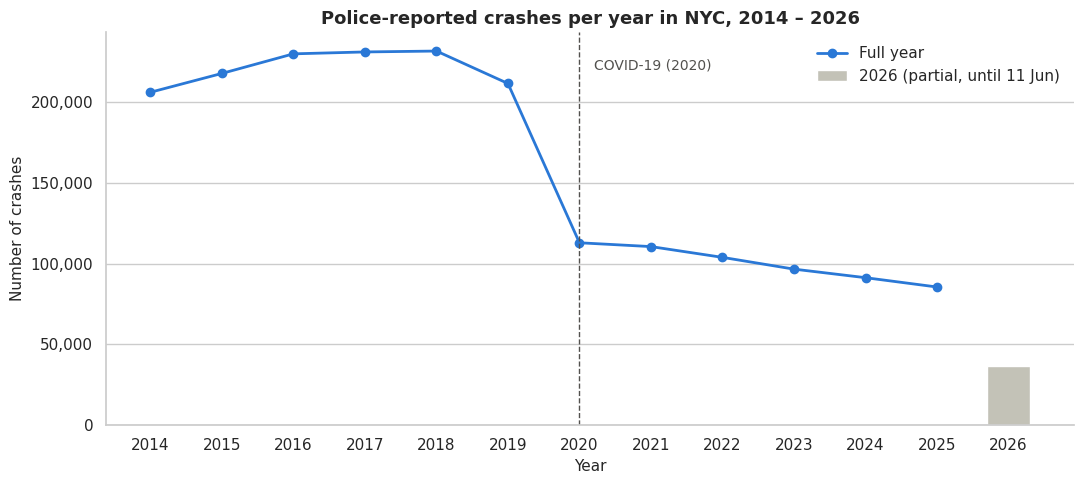

year
2014    206046
2015    217708
2016    229833
2017    231007
2018    231564
2019    211486
2020    112918
2021    110558
2022    103887
2023     96607
2024     91316
2025     85546
2026     36424


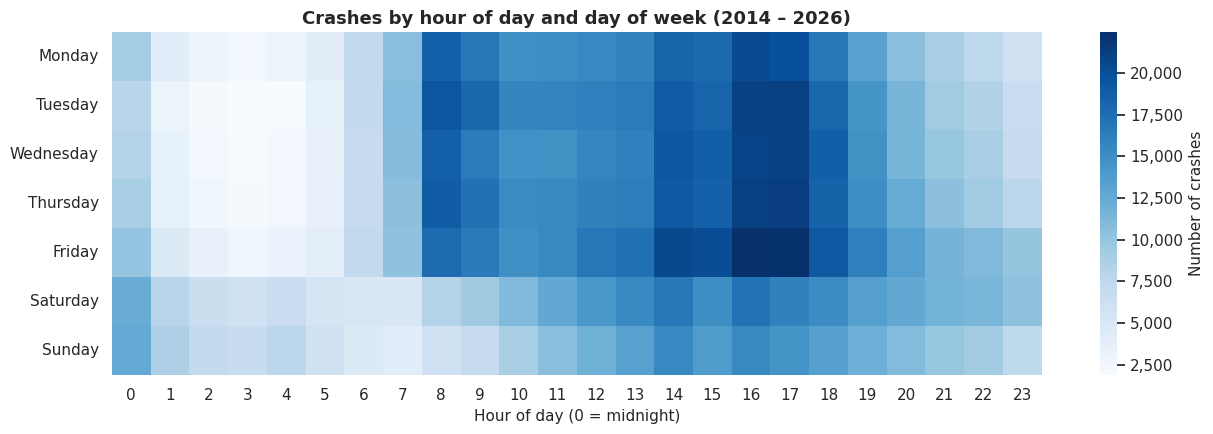

In [14]:
# --- Crashes over time: per year, then by hour x weekday ---
crashes_per_year = collisions_eda.groupby("year").size()
last_crash_date = collisions_eda["crash_date"].max()

fig, ax = plt.subplots(figsize=(11, 5))
full_years = crashes_per_year.loc[crashes_per_year.index < last_crash_date.year]
ax.plot(full_years.index, full_years.values, marker="o", linewidth=2, color=PALETTE[0], label="Full year")
ax.bar(last_crash_date.year, crashes_per_year.loc[last_crash_date.year], color="#c3c2b7",
       width=0.6, label=f"{last_crash_date.year} (partial, until {last_crash_date:%d %b})")
ax.axvline(2020, color="#52514e", linestyle="--", linewidth=1)
ax.annotate("COVID-19 (2020)", xy=(2020, full_years.loc[2020]), xytext=(2020.2, full_years.max() * 0.95),
            fontsize=10, color="#52514e")
ax.set_title("Police-reported crashes per year in NYC, 2014 – 2026")
ax.set_xlabel("Year")
ax.set_ylabel("Number of crashes")
ax.set_xticks(crashes_per_year.index)
ax.set_ylim(0)
thousands(ax)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(crashes_per_year.to_string())

# When do crashes happen? Hour of day x day of week
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hour_weekday = (collisions_eda.groupby(["weekday", "hour"]).size()
                .unstack("hour").reindex(WEEKDAY_ORDER))

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(hour_weekday, cmap="Blues", ax=ax, cbar_kws={"label": "Number of crashes", "format": "{x:,.0f}"})
ax.set_title("Crashes by hour of day and day of week (2014 – 2026)")
ax.set_xlabel("Hour of day (0 = midnight)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Time patterns — observations**
* About 206 – 232 thousand crashes per year in 2014 – 2019, **halved in 2020 (COVID-19)**, slowly declining since.
  Any trend crossing 2020 must be read with care.
* **2026 is partial** (data end 11 June) — never compare it with full years.
* Peaks: **weekday 16:00 – 17:00** and the 08:00 rush; weekends have no morning rush but nearly **twice the late-night
  crashes** (00:00 – 03:59).
* The **midnight column is brighter than both 23:00 and 01:00** — a sign that `0:00` is often entered when the time is
  unknown. Section 4 (Step C7) measures this exactly and flags those times.

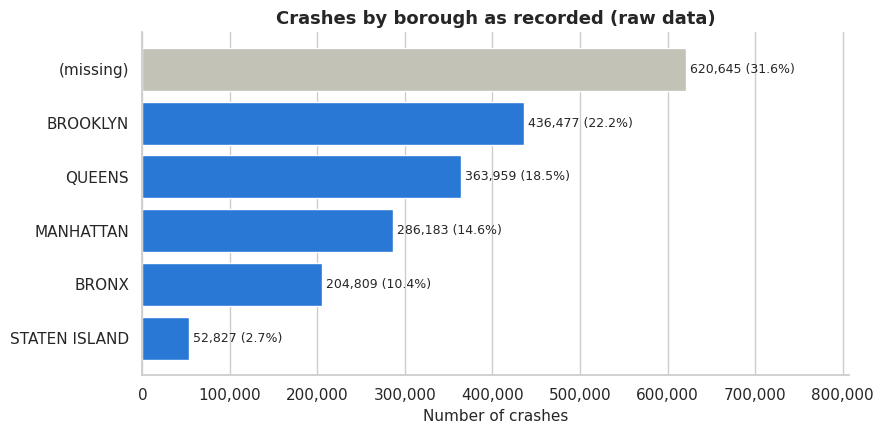

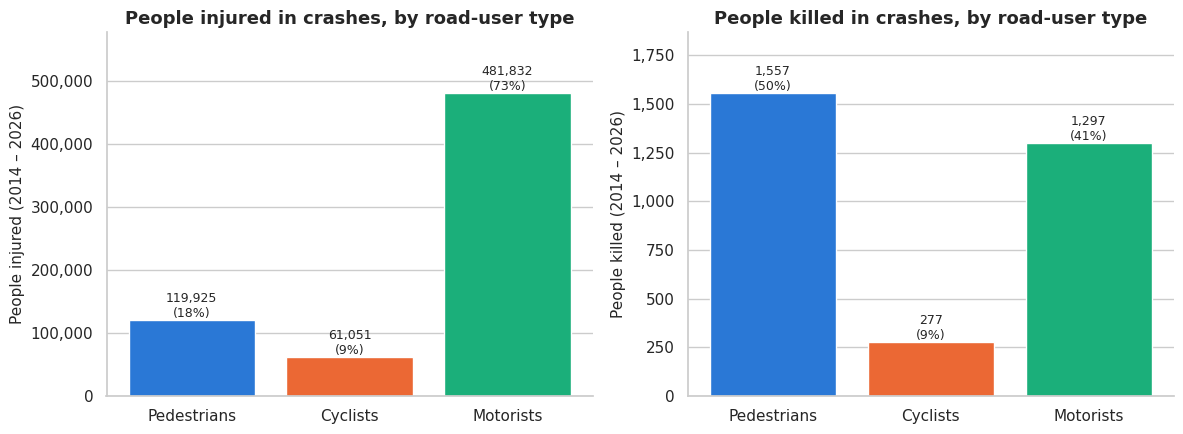

In [15]:
# --- Where and who: borough as recorded, then casualties by road-user type ---
# Where are crashes recorded? Borough, including records with no borough
borough_counts = collisions_eda["borough"].fillna("(missing)").value_counts()

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#c3c2b7" if name == "(missing)" else PALETTE[0] for name in borough_counts.index]
ax.barh(borough_counts.index[::-1], borough_counts.values[::-1], color=colors[::-1])
for y, value in enumerate(borough_counts.values[::-1]):
    ax.text(value, y, f" {value:,} ({value / len(collisions_eda):.1%})", va="center", fontsize=9)
horizontal_bar_grid(ax)
ax.set_title("Crashes by borough as recorded (raw data)")
ax.set_xlabel("Number of crashes")
ax.set_xlim(0, borough_counts.max() * 1.3)
thousands(ax, axis="x")
plt.tight_layout()
plt.show()

# Who gets hurt? Injuries and deaths by road-user type
road_users = ["pedestrians", "cyclist", "motorist"]
labels = {"pedestrians": "Pedestrians", "cyclist": "Cyclists", "motorist": "Motorists"}
injured = [collisions_eda[f"number_of_{user}_injured"].sum() for user in road_users]
killed = [collisions_eda[f"number_of_{user}_killed"].sum() for user in road_users]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, values, title in [(axes[0], injured, "Injured"), (axes[1], killed, "Killed")]:
    bars = ax.bar([labels[u] for u in road_users], values, color=PALETTE[:3])
    ax.bar_label(bars, labels=[f"{v:,.0f}\n({v / sum(values):.0%})" for v in values], fontsize=9)
    ax.set_title(f"People {title.lower()} in crashes, by road-user type")
    ax.set_ylabel(f"People {title.lower()} (2014 – 2026)")
    ax.set_ylim(0, max(values) * 1.2)
    thousands(ax)
plt.tight_layout()
plt.show()

**Location and road users — observations**
* The biggest "borough" is **no borough at all (31.6%)** — recovering location from coordinates is the key cleaning task.
* Brooklyn and Queens record the most crashes, but raw counts ignore population and road length.
* Motorists suffer most **injuries (73%)**, but **pedestrians suffer the most deaths (50%)** — the most vulnerable road
  users are people on foot, central to our question.

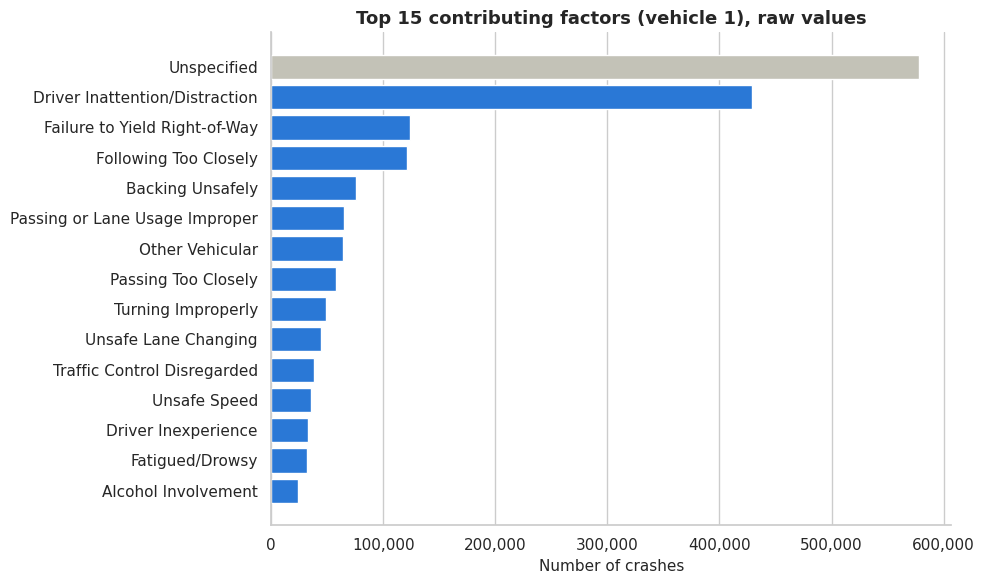

Distinct factor values: 66
Share of all crashes:
contributing_factor_vehicle_1
Unspecified                       29.4%
Driver Inattention/Distraction    21.9%
Failure to Yield Right-of-Way      6.3%
Following Too Closely              6.2%
Crashes with coordinates        : 1,770,981
  inside the NYC bounding box   : 1,763,241
  exactly at (0, 0)             : 7,590
  other points outside NYC      : 150

The points outside NYC (excluding 0,0):
     latitude  longitude
min    30.784   -201.360
max    43.344    -32.769


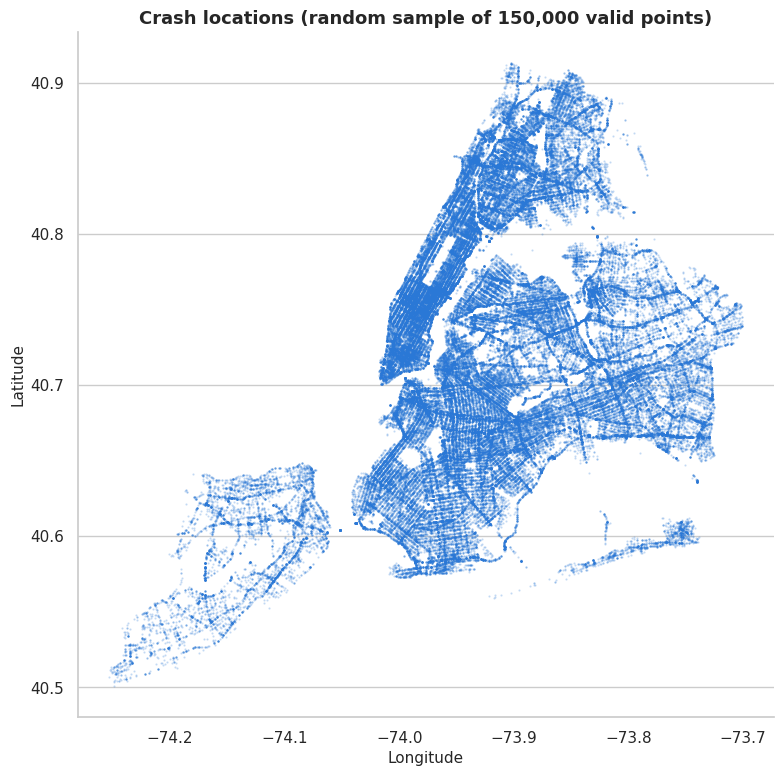

In [16]:
# --- Why and where exactly: contributing factors, then coordinates ---
# Why do crashes happen? Top contributing factors of the first vehicle
factor_counts = df_collisions_raw["contributing_factor_vehicle_1"].fillna("(missing)").value_counts()
top_factors = factor_counts.head(15)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#c3c2b7" if f in ("Unspecified", "(missing)") else PALETTE[0] for f in top_factors.index]
ax.barh(top_factors.index[::-1], top_factors.values[::-1], color=colors[::-1])
horizontal_bar_grid(ax)
ax.set_title("Top 15 contributing factors (vehicle 1), raw values")
ax.set_xlabel("Number of crashes")
thousands(ax, axis="x")
plt.tight_layout()
plt.show()

print(f"Distinct factor values: {df_collisions_raw['contributing_factor_vehicle_1'].nunique()}")
print("Share of all crashes:")
print((factor_counts.head(4) / len(df_collisions_raw)).map("{:.1%}".format).to_string())

# Where are crashes located? Coordinates vs the NYC bounding box
coords = collisions_eda[["latitude", "longitude"]].dropna()
inside_nyc = (coords["latitude"].between(NYC_BOUNDS["lat_min"], NYC_BOUNDS["lat_max"])
              & coords["longitude"].between(NYC_BOUNDS["lon_min"], NYC_BOUNDS["lon_max"]))
at_zero = (coords["latitude"] == 0) & (coords["longitude"] == 0)

print(f"Crashes with coordinates        : {len(coords):,}")
print(f"  inside the NYC bounding box   : {inside_nyc.sum():,}")
print(f"  exactly at (0, 0)             : {at_zero.sum():,}")
print(f"  other points outside NYC      : {(~inside_nyc & ~at_zero).sum():,}")
print("\nThe points outside NYC (excluding 0,0):")
print(coords[~inside_nyc & ~at_zero].describe().loc[["min", "max"]])

# Map a random sample of the valid points (plotting 1.7 million points is slow and adds nothing visually)
sample = coords[inside_nyc].sample(150_000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(sample["longitude"], sample["latitude"], s=0.3, alpha=0.25, color=PALETTE[0])
ax.set_title("Crash locations (random sample of 150,000 valid points)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(40.7)))  # correct east-west stretching at NYC's latitude
plt.tight_layout()
plt.show()

**Causes and coordinates — observations**
* **`Unspecified` (29.4% of crashes) is a hidden missing value**, not a cause. Real leading causes: driver inattention (21.9%),
  **failure to yield right-of-way (6.3%)**, following too closely (6.2%).
* Valid coordinates draw NYC's street network — reliable when present. **7,590 crashes at (0, 0)** (the Atlantic Ocean)
  and **150 other points outside NYC** (e.g., longitude −201°, impossible) are invalid placeholders.

## 3.2 Housing

Affordable units (all_counted_units): 320,946 of 445,588 total units (72.0%); buildings that also contain market-rate units: 2,752


,count,mean,std,min,25%,50%,75%,max
total_units,"9,551.000",46.654,92.482,1.000,3.000,12.000,45.000,"1,320.000"
all_counted_units,"9,522.000",33.706,65.834,1.000,2.000,8.000,30.000,917.000
counted_rental_units,"6,944.000",37.446,63.786,1.000,5.000,13.000,41.000,917.000
counted_homeownership_units,"2,730.000",22.316,68.288,1.000,1.000,1.000,2.000,489.000


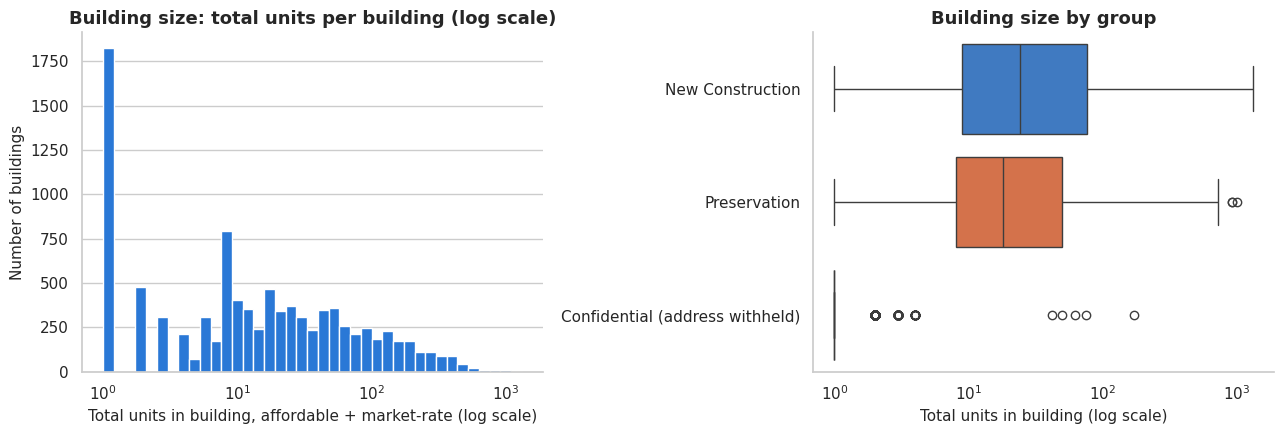

IQR rule: Q1 = 3, Q3 = 45, upper fence = 108 units -> 1,171 buildings flagged
                                    count   25%    50%    75%       max
Confidential (address withheld) 1,949.000 1.000  1.000  1.000   171.000
New Construction                3,563.000 9.000 24.000 77.000 1,320.000
Preservation                    4,039.000 8.000 18.000 50.000 1,000.000


In [17]:
# --- Typed working copy of the housing data (exploration only) ---
UNIT_INCOME_COLUMNS = [
    "extremely_low_income_units", "very_low_income_units", "low_income_units",
    "moderate_income_units", "middle_income_units", "other_income_units",
]
UNIT_BEDROOM_COLUMNS = [
    "studio_units", "_1_br_units", "_2_br_units", "_3_br_units",
    "_4_br_units", "_5_br_units", "_6_br_units", "unknown_br_units",
]
UNIT_OTHER_COLUMNS = ["counted_rental_units", "counted_homeownership_units", "all_counted_units", "total_units"]
HOUSING_DATE_COLUMNS = ["project_start_date", "project_completion_date", "building_completion_date"]

housing_eda = df_housing_raw.copy()
for column in HOUSING_DATE_COLUMNS:
    housing_eda[column] = pd.to_datetime(housing_eda[column], errors="coerce")
for column in UNIT_INCOME_COLUMNS + UNIT_BEDROOM_COLUMNS + UNIT_OTHER_COLUMNS + ["latitude", "longitude"]:
    housing_eda[column] = pd.to_numeric(housing_eda[column], errors="coerce")
housing_eda["start_year"] = housing_eda["project_start_date"].dt.year
housing_eda["is_confidential"] = housing_eda["project_name"].eq("CONFIDENTIAL")

# Data dictionary: total_units = affordable + market-rate units; all_counted_units = affordable units only
print(f"Affordable units (all_counted_units): {housing_eda['all_counted_units'].sum():,.0f} "
      f"of {housing_eda['total_units'].sum():,.0f} total units "
      f"({housing_eda['all_counted_units'].sum() / housing_eda['total_units'].sum():.1%}); "
      f"buildings that also contain market-rate units: "
      f"{(housing_eda['all_counted_units'] < housing_eda['total_units']).sum():,}")
display(housing_eda[["total_units", "all_counted_units", "counted_rental_units", "counted_homeownership_units"]].describe().T)

# --- Building size distribution ---
# Distribution of building size (log scale, because of the strong skew)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(housing_eda["total_units"], bins=np.logspace(0, np.log10(housing_eda["total_units"].max()), 40),
             color=PALETTE[0], edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_title("Building size: total units per building (log scale)")
axes[0].set_xlabel("Total units in building, affordable + market-rate (log scale)")
axes[0].set_ylabel("Number of buildings")

# Confidential records are shown as their own group (see observations below)
size_group = np.where(housing_eda["is_confidential"], "Confidential (address withheld)",
                      housing_eda["reporting_construction_type"])
sns.boxplot(x=housing_eda["total_units"], y=size_group, ax=axes[1], log_scale=True,
            order=["New Construction", "Preservation", "Confidential (address withheld)"],
            hue=size_group, palette=dict(zip(["New Construction", "Preservation",
                                              "Confidential (address withheld)"], PALETTE[:3])), legend=False)
axes[1].set_title("Building size by group")
axes[1].set_xlabel("Total units in building (log scale)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

q1, q3 = housing_eda["total_units"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print(f"IQR rule: Q1 = {q1:.0f}, Q3 = {q3:.0f}, upper fence = {upper_fence:.0f} units "
      f"-> {(housing_eda['total_units'] > upper_fence).sum():,} buildings flagged")
print(housing_eda.groupby(size_group)["total_units"].describe()[["count", "25%", "50%", "75%", "max"]])

**Building size — observations**
* By the data dictionary, `total_units` counts **affordable + market-rate** units, while `all_counted_units` counts only
  the **affordable** ones. Affordable units are **320,946 of 445,588 (72.0%)**, and **2,752 buildings are mixed-income**.
  From here on, "affordable units" always means `all_counted_units`; `total_units` is used only as building size.
* Building size is highly skewed: median **12** units, mean 47, max **1,320** — measure both *buildings* and *units*.
* The spike at 1 unit is the **confidential records: almost all single-unit homes** (median 1), i.e., individual
  homeowners — which is why their addresses are withheld.
* Without them, new construction is larger (median 24) than preservation (median 18).
* IQR flags **1,171 buildings (> 108 units)**, but these are real large developments — kept, not deleted (Section 4).

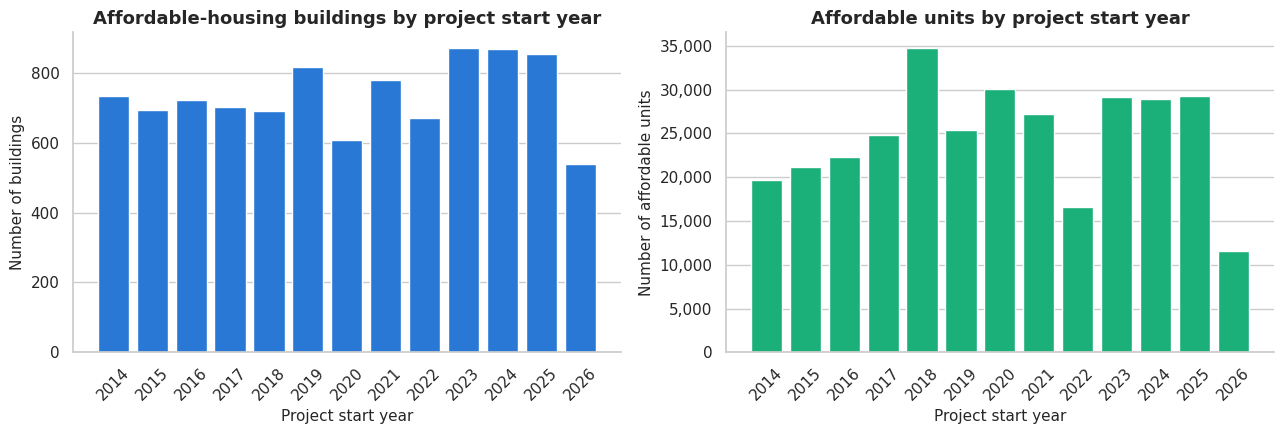

            buildings  affordable_units
start_year                             
2014              734             19629
2015              694             21153
2016              722             22344
2017              703             24789
2018              691             34794
2019              816             25430
2020              608             30076
2021              780             27234
2022              670             16557
2023              872             29113
2024              868             28965
2025              854             29277
2026              539             11585


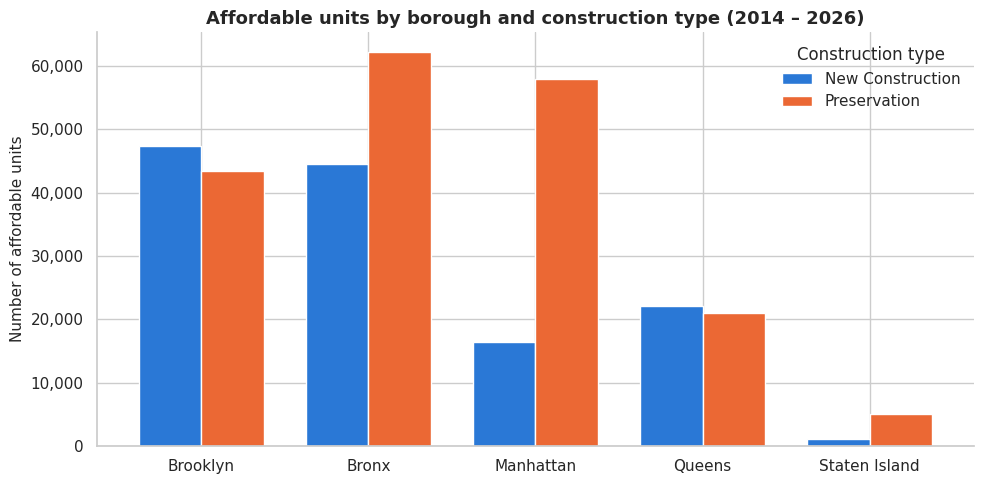

reporting_construction_type,New Construction,Preservation,total
borough,,,
Brooklyn,47425,43359,90784
Bronx,44450,62211,106661
Manhattan,16412,57926,74338
Queens,22019,20933,42952
Staten Island,1142,5069,6211


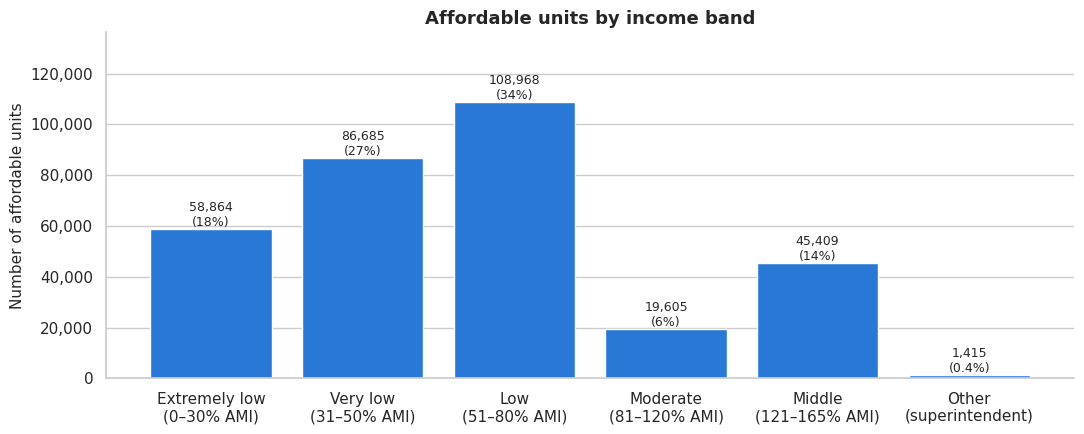

In [18]:
# --- Production over time, by borough and type, and by income band ---
# Production over time: buildings and units by project start year
# Affordable units = all_counted_units (total_units also includes market-rate units, see the data dictionary)
by_year = housing_eda.groupby("start_year").agg(buildings=("project_id", "size"),
                                                affordable_units=("all_counted_units", "sum")).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(by_year.index, by_year["buildings"], color=PALETTE[0])
axes[0].set_title("Affordable-housing buildings by project start year")
axes[0].set_ylabel("Number of buildings")
axes[1].bar(by_year.index, by_year["affordable_units"], color=PALETTE[2])
axes[1].set_title("Affordable units by project start year")
axes[1].set_ylabel("Number of affordable units")
for ax in axes:
    ax.set_xlabel("Project start year")
    ax.set_xticks(by_year.index)
    ax.tick_params(axis="x", rotation=45)
    thousands(ax)
plt.tight_layout()
plt.show()

print(by_year.to_string())

# Where is it built, and what kind? Borough x construction type
borough_type = (housing_eda.groupby(["borough", "reporting_construction_type"])["all_counted_units"].sum()
                .unstack().reindex(BOROUGH_ORDER).astype(int))

ax = borough_type.plot(kind="bar", figsize=(10, 5), color=PALETTE[:2], width=0.75, rot=0)
ax.set_title("Affordable units by borough and construction type (2014 – 2026)")
ax.set_xlabel("")
ax.set_ylabel("Number of affordable units")
ax.legend(title="Construction type", frameon=False)
thousands(ax)
plt.tight_layout()
plt.show()

display(borough_type.assign(total=borough_type.sum(axis=1)))

# Who is it for? Units by income band (the band is defined relative to the Area Median Income, AMI)
income_labels = {
    "extremely_low_income_units": "Extremely low\n(0–30% AMI)",
    "very_low_income_units": "Very low\n(31–50% AMI)",
    "low_income_units": "Low\n(51–80% AMI)",
    "moderate_income_units": "Moderate\n(81–120% AMI)",
    "middle_income_units": "Middle\n(121–165% AMI)",
    "other_income_units": "Other\n(superintendent)",
}
income_totals = housing_eda[UNIT_INCOME_COLUMNS].sum().rename(index=income_labels)

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(income_totals.index, income_totals.values, color=PALETTE[0])
shares = income_totals / income_totals.sum()
ax.bar_label(bars, labels=[f"{v:,.0f}\n({p:.1%})" if p < 0.01 else f"{v:,.0f}\n({p:.0%})"
                           for v, p in zip(income_totals.values, shares.values)], fontsize=9)
ax.set_title("Affordable units by income band")
ax.set_ylabel("Number of affordable units")
ax.set_ylim(0, income_totals.max() * 1.25)
thousands(ax)
plt.tight_layout()
plt.show()

**Production — observations**
* Every year has activity (≈600 – 870 buildings started per year); 2026 is incomplete. Affordable units dip in
  **2022 (16,557)** — the year the city switched from the *Housing New York* plan to *Housing Our Neighbors*.
* Buildings and units diverge (2018: fewer buildings than 2019 — 691 vs 816 — but more affordable units — 34,794 vs 25,430).
* **The Bronx has the most affordable units (106,661; 33%)**, then Brooklyn (90,784; 28%) and Manhattan (74,338; 23%);
  Staten Island only 1.9%. **Preservation dominates** in Manhattan (78%), Staten Island (82%) and the Bronx (58%);
  Brooklyn and Queens are roughly balanced.
* **79% of units serve households at ≤ 80% of AMI** (low 34%, very low 27%, extremely low 18%) — the households least
  likely to own a car.

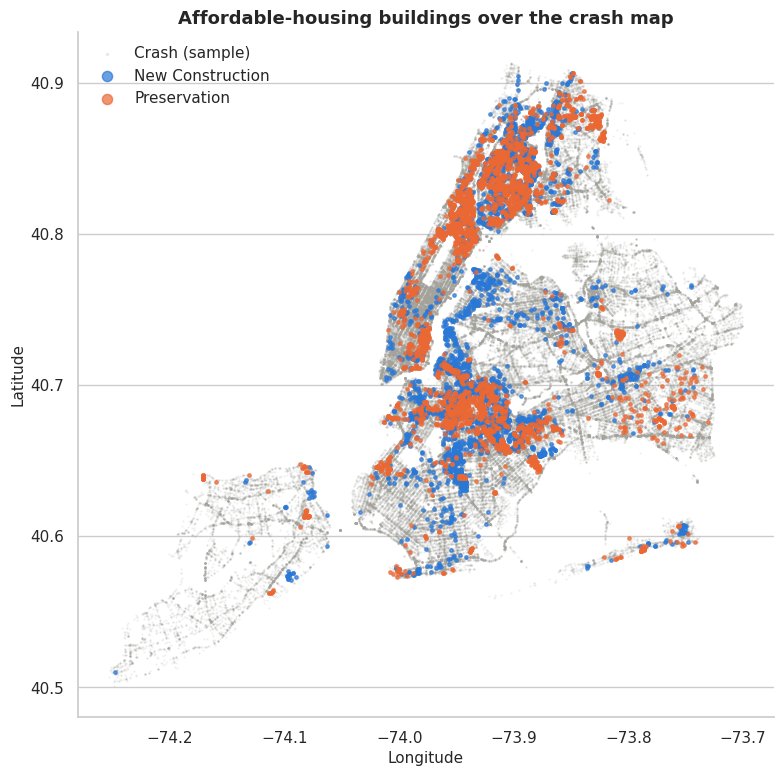

Mappable buildings: 7,593 of 9,551 (79.5%); confidential: 1,949


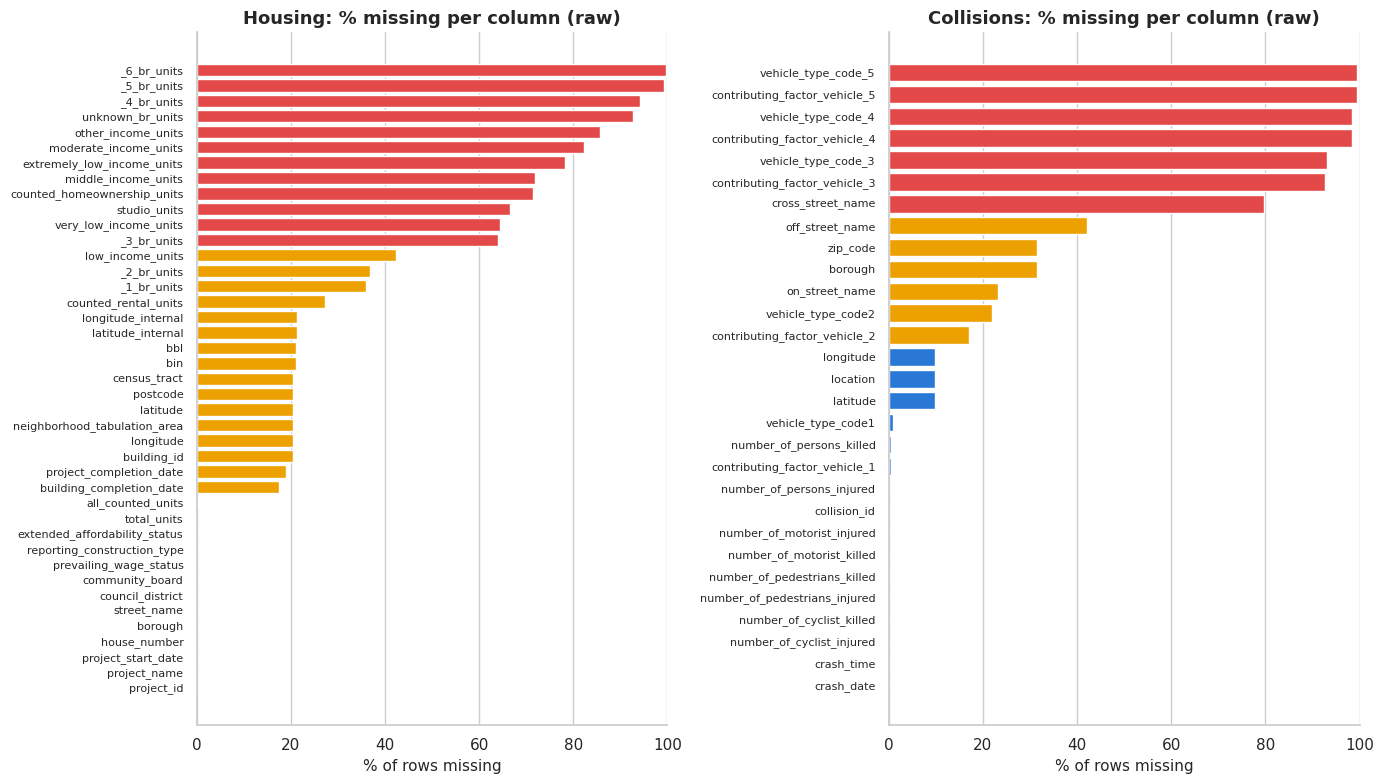

In [19]:
# --- Where the buildings are, then missing values in both datasets ---
# Where are the buildings? Map of mappable buildings by construction type
mappable = housing_eda.dropna(subset=["latitude", "longitude"])
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(sample["longitude"], sample["latitude"], s=0.3, alpha=0.15, color="#a3a29b", label="Crash (sample)")
for color, (ctype, group) in zip(PALETTE[:2], mappable.groupby("reporting_construction_type")):
    ax.scatter(group["longitude"], group["latitude"], s=6, alpha=0.7, color=color, label=ctype)
ax.set_title("Affordable-housing buildings over the crash map")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.legend(frameon=False, markerscale=3, loc="upper left")
plt.tight_layout()
plt.show()

print(f"Mappable buildings: {len(mappable):,} of {len(housing_eda):,} "
      f"({len(mappable) / len(housing_eda):.1%}); confidential: {housing_eda['is_confidential'].sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, df, name in [(axes[0], df_housing_raw, "Housing"), (axes[1], df_collisions_raw, "Collisions")]:
    missing_pct = df.isna().mean().mul(100).sort_values()
    colors = [PALETTE[7] if v > 50 else PALETTE[3] if v > 10 else PALETTE[0] for v in missing_pct.values]
    ax.barh(missing_pct.index, missing_pct.values, color=colors)
    horizontal_bar_grid(ax)
    ax.set_title(f"{name}: % missing per column (raw)")
    ax.set_xlabel("% of rows missing")
    ax.set_xlim(0, 100)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Map and missing values — observations**
* Housing is **clustered** in the South/Central Bronx, Upper Manhattan, and central/eastern Brooklyn (plus south-east
  Queens and the Rockaways), visibly overlapping dense crash areas. **Overlap is not causation** — both follow
  population density, so later analyses compare rates.
* Missing values (blue ≤ 10%, yellow 10 – 50%, red > 50%) have different meanings: empty housing unit columns mean
  **zero**; vehicles 3 – 5 are empty because **most crashes involve one or two vehicles**; the real gaps are crash
  **borough/ZIP (31.6%)** and **coordinates (9.9%)**, and housing **location for ~20% of records**.

## 3.3 First cross-domain look
A deliberately simple borough-level preview, using only crashes with a recorded borough.

In [20]:
# Crash side: only crashes with a recorded borough; names converted from "BROOKLYN" to "Brooklyn" to match housing
crashes_with_borough = collisions_eda.dropna(subset=["borough"]).assign(
    borough=lambda d: d["borough"].str.title(),
    pedestrian_casualties=lambda d: d["number_of_pedestrians_injured"] + d["number_of_pedestrians_killed"])
crashes_by_borough = crashes_with_borough.groupby("borough").agg(
    crashes=("collision_id", "size"), pedestrians_injured_or_killed=("pedestrian_casualties", "sum"))
units_by_borough = housing_eda.groupby("borough").agg(buildings=("project_id", "size"),
                                                      affordable_units=("all_counted_units", "sum")).astype(int)
borough_preview = units_by_borough.join(crashes_by_borough).reindex(BOROUGH_ORDER)
borough_preview["share_of_units_%"] = (borough_preview["affordable_units"]
                                       / borough_preview["affordable_units"].sum() * 100).round(1)
borough_preview["share_of_ped_casualties_%"] = (borough_preview["pedestrians_injured_or_killed"]
                                                / borough_preview["pedestrians_injured_or_killed"].sum() * 100).round(1)
borough_preview

,buildings,affordable_units,crashes,pedestrians_injured_or_killed,share_of_units_%,share_of_ped_casualties_%
borough,,,,,,
Brooklyn,3649,90784,436477,32721,28.300,34.000
Bronx,2630,106661,204809,16209,33.200,16.800
Manhattan,1485,74338,286183,21215,23.200,22.000
Queens,1342,42952,363959,23469,13.400,24.400
Staten Island,445,6211,52827,2613,1.900,2.700


**Observations**
* The shares do **not** line up: the **Bronx** has 33.2% of affordable units but only 16.8% of pedestrian casualties;
  **Queens** has 13.4% of units but 24.4% of pedestrian casualties.
* Borough is far too coarse (and a third of crashes lack one) — the real analysis needs **ZIP × year** and **street
  level around each building**, as planned in 2.5.

### EDA summary → what Section 4 must do

| Finding | Action in Section 4 |
|---|---|
| 31.6% of crashes lack borough/ZIP; 9.9% lack coordinates | Recover borough/ZIP from coordinates; report the rest |
| (0, 0) and out-of-NYC coordinates | Set to missing (invalid) |
| `Unspecified`, blank ZIPs, `----` addresses, million-BINs | Convert hidden missing values to real missing values |
| Excess crashes at exactly 00:00 | Flag the time as uncertain |
| Skewed casualty and unit counts | Domain-rule outlier checks; keep real extremes |
| Empty unit columns | Fill with 0 |
| 1,905 vehicle spellings, swapped street columns, extra spaces | Standardize; rename |
| 1,590 possible duplicate crashes | Investigate and remove true duplicates |
| Partial 2026; COVID break in 2020 | Flag; note in every trend |

---
# 4. Pre-Integration Cleaning

Each problem found in Sections 2 – 3 is fixed here, one step at a time. Three rules apply throughout:

1. **The raw snapshots are never modified** — cleaning works on copies (`collisions`, `housing`).
2. **Nothing is removed silently** — every step records how many values or rows it changed in a *cleaning log*.
3. **Every decision is justified** — why a value is dropped, imputed, flagged or kept, and which alternatives were rejected.

## 4.1 Collisions

### Step C1 — Structural fixes: mislabelled columns and a redundant column

**Swapped street columns.** In the API, the field `off_street_name` holds *cross streets* and `cross_street_name` holds
*off-street addresses* (house number + street). The evidence is threefold: the dataset's own metadata gives the field
`off_street_name` the display name "CROSS STREET NAME" (and vice versa); full addresses are almost all unique while
cross streets repeat; and the example values show it. We rename the two columns so that each name matches its content.

**Redundant `location`.** `location` repeats the latitude and longitude as text. We verify that it carries no extra
information before dropping it.

> **Decision — rename the two swapped columns and drop `location`.**
> *Alternatives considered:* keep the API names and only document the swap; keep `location`.
> *Why:* a name that contradicts its content causes errors in every later step; `location` is verified to be an exact
> copy of latitude/longitude, so it adds nothing.

In [21]:
import gc
import re

# Free the large EDA working copies - Section 4 starts again from the raw snapshots
for name in ["collisions_eda", "crashes_with_borough", "coords", "sample"]:
    globals().pop(name, None)
gc.collect()

cleaning_log = []


def log_step(dataset, step, action, affected, df):
    # Record one cleaning action (how many values/rows it changed) and print it.
    cleaning_log.append({"dataset": dataset, "step": step, "action": action,
                         "values_or_rows_affected": int(affected), "rows_after": len(df)})
    print(f"[{dataset}] {step}: {action} -> {int(affected):,} affected | {len(df):,} rows")


def clean_text(series, case="upper"):
    # Standardize free text: trim, collapse repeated spaces, one letter case; empty strings become missing.
    s = series.str.strip().str.replace(r"\s+", " ", regex=True)
    s = s.str.upper() if case == "upper" else s.str.title()
    return s.replace("", np.nan)

collisions = df_collisions_raw.copy()

# Evidence 1: the dataset's own metadata (display name of each API field); needs internet access
try:
    meta = requests.get(f"https://data.cityofnewyork.us/api/views/{COLLISIONS_ID}.json", timeout=60).json()
    display_names = {col["fieldName"]: col["name"] for col in meta["columns"]}
    for field in ["off_street_name", "cross_street_name"]:
        print(f"API field '{field}' is displayed by NYC Open Data as '{display_names[field]}'")
except Exception as error:
    print(f"Metadata not reachable ({error}); see the evidence below")

# Evidence 2 and 3: distinct values and examples
street_cols = ["on_street_name", "off_street_name", "cross_street_name"]
display(pd.DataFrame({
    "non_missing": collisions[street_cols].notna().sum(),
    "unique_values": collisions[street_cols].nunique(),
    "example": [collisions[c].dropna().iloc[0].strip() for c in street_cols],
}))

# Fix: swap the two names (pandas renames both labels simultaneously)
collisions = collisions.rename(columns={"off_street_name": "cross_street_name",
                                        "cross_street_name": "off_street_name"})
log_step("collisions", "C1", "renamed swapped columns off_street_name <-> cross_street_name", 2, collisions)

# 'location' check: same missing pattern as latitude, and identical coordinates where present
location_coords = collisions["location"].str.extract(r"\((-?[\d.]+), (-?[\d.]+)\)").astype(float)
present = location_coords.notna().all(axis=1)
same_missing = (collisions["location"].isna() == collisions["latitude"].isna()).all()
same_values = (np.isclose(location_coords.loc[present, 0], pd.to_numeric(collisions.loc[present, "latitude"]))
               & np.isclose(location_coords.loc[present, 1], pd.to_numeric(collisions.loc[present, "longitude"]))).mean()
print(f"\n'location' missing exactly where latitude is missing: {same_missing}; "
      f"coordinates identical in {same_values:.2%} of rows")
collisions = collisions.drop(columns="location")
log_step("collisions", "C1", "dropped redundant column 'location'", 1, collisions)

API field 'off_street_name' is displayed by NYC Open Data as 'CROSS STREET NAME'
API field 'cross_street_name' is displayed by NYC Open Data as 'OFF STREET NAME'


,non_missing,unique_values,example
on_street_name,1509156,22972,111 STREET
off_street_name,1138212,24840,ROCKAWAY BOULEVARD
cross_street_name,398634,265710,745 MANHATTAN AVENUE


[collisions] C1: renamed swapped columns off_street_name <-> cross_street_name -> 2 affected | 1,964,900 rows

'location' missing exactly where latitude is missing: True; coordinates identical in 100.00% of rows
[collisions] C1: dropped redundant column 'location' -> 1 affected | 1,964,900 rows


### Step C2 — Standardize formats (dates, times, numbers, ZIP codes, text)

* **Dates and times:** `crash_date` becomes a real date; `crash_time` ("H:MM") is split into `crash_hour` and
  `crash_minute`, and combined into `crash_datetime`.
* **Numbers:** coordinates become decimals, casualty counts and the ID become integers.
* **ZIP codes:** stored as **5-character text** (a ZIP code is a label, not a quantity — as a number, leading zeros
  and formatting could be lost). Values that are blank or not a valid NYC ZIP code (NYC ZIP codes start with
  100 – 104 or 110 – 116) become missing; Step C8 later recovers them from coordinates.
* **Text:** borough names in title case (`Brooklyn`, matching the housing data); street names trimmed, with repeated
  spaces collapsed and upper case.

> **Decision — ZIP codes stay 5-character text; blank and non-NYC ZIP codes become missing (recovered in C8).**
> *Alternatives considered:* store ZIP codes as integers; keep invalid values as they are.
> *Why:* a ZIP code is a label, not a quantity; an invalid ZIP code would create a fake neighbourhood in the integration.

In [22]:
INJURY_COLUMNS = [
    "number_of_persons_injured", "number_of_persons_killed",
    "number_of_pedestrians_injured", "number_of_pedestrians_killed",
    "number_of_cyclist_injured", "number_of_cyclist_killed",
    "number_of_motorist_injured", "number_of_motorist_killed",
]
NYC_ZIP_PATTERN = r"^1(?:0[0-4]|1[0-6])\d{2}$"

# Dates and times
collisions["crash_date"] = pd.to_datetime(collisions["crash_date"], format="%Y-%m-%dT%H:%M:%S.%f")
time_parts = collisions["crash_time"].str.split(":", expand=True).astype(int)
collisions["crash_hour"], collisions["crash_minute"] = time_parts[0], time_parts[1]
collisions["crash_datetime"] = collisions["crash_date"] + pd.to_timedelta(
    collisions["crash_hour"] * 60 + collisions["crash_minute"], unit="min")
log_step("collisions", "C2", "parsed crash_date / crash_time into datetime, hour, minute", len(collisions), collisions)

# Numbers
collisions["collision_id"] = collisions["collision_id"].astype("int64")
collisions[["latitude", "longitude"]] = collisions[["latitude", "longitude"]].astype(float)
collisions[INJURY_COLUMNS] = collisions[INJURY_COLUMNS].apply(pd.to_numeric).astype("Int64")  # totals still have gaps

# ZIP codes: blank or invalid -> missing
zip_text = collisions["zip_code"].str.strip()
blank_zip = zip_text.eq("")
invalid_zip = zip_text.notna() & ~blank_zip & ~zip_text.str.match(NYC_ZIP_PATTERN, na=False)
print("Invalid ZIP values:", zip_text[invalid_zip].value_counts().to_dict())
collisions["zip_code"] = zip_text.mask(blank_zip | invalid_zip)
log_step("collisions", "C2", "blank ZIP codes -> missing", blank_zip.sum(), collisions)
log_step("collisions", "C2", "non-NYC / invalid ZIP codes -> missing", invalid_zip.sum(), collisions)

# Text
collisions["borough"] = clean_text(collisions["borough"], case="title")
before_unique = collisions[["on_street_name", "cross_street_name", "off_street_name"]].nunique()
for column in ["on_street_name", "cross_street_name", "off_street_name"]:
    collisions[column] = clean_text(collisions[column])
after_unique = collisions[["on_street_name", "cross_street_name", "off_street_name"]].nunique()
display(pd.DataFrame({"unique_before": before_unique, "unique_after": after_unique,
                      "variants_merged": before_unique - after_unique}))
log_step("collisions", "C2", "street names trimmed / spaces collapsed / upper case",
         (before_unique - after_unique).sum(), collisions)
print("Boroughs:", collisions["borough"].value_counts(dropna=False).to_dict())

[collisions] C2: parsed crash_date / crash_time into datetime, hour, minute -> 1,964,900 affected | 1,964,900 rows
Invalid ZIP values: {'10803': 1, '12345': 1}
[collisions] C2: blank ZIP codes -> missing -> 20 affected | 1,964,900 rows
[collisions] C2: non-NYC / invalid ZIP codes -> missing -> 2 affected | 1,964,900 rows


,unique_before,unique_after,variants_merged
on_street_name,22972,14317,8655
cross_street_name,24840,15518,9322
off_street_name,265710,234463,31247


[collisions] C2: street names trimmed / spaces collapsed / upper case -> 49,224 affected | 1,964,900 rows
Boroughs: {None: 620645, 'Brooklyn': 436477, 'Queens': 363959, 'Manhattan': 286183, 'Bronx': 204809, 'Staten Island': 52827}


### Step C3 — Hidden missing values and inconsistent categories

**Contributing factors.** `Unspecified` means *no cause was recorded*, so it is converted to missing — otherwise it
would rank as the "leading cause" of crashes. Seven purely numeric codes (`1`, `35`, `80`, …) have no meaning in the
factor list and are also set to missing. Four spelling variants are merged (e.g., `Illnes` → `Illness`).

**Vehicle types.** The 1,905 raw spellings are mapped to **11 interpretable categories** with ordered keyword rules
(the first matching rule wins, so e.g. "SPORT UTILITY" is matched as a car before "UTIL" could match a truck). The
categories are what the analysis and the website filters need; the share left to the fallback category is reported.

**Vehicles 3 – 5.** Their columns are > 92% empty because most crashes involve one or two vehicles — this is
*structurally* missing, not lost data. We keep that information as a count (`vehicles_involved`) and drop the
mostly-empty columns, keeping categories and factors for vehicles 1 and 2.

> **Decision — `Unspecified` and numeric codes → missing; 11 vehicle categories from ordered rules; vehicles 3 – 5 → a count.**
> *Alternatives considered:* keep `Unspecified` as a category; leave the 1,905 raw spellings or map them by hand;
> keep the near-empty columns.
> *Why:* "no cause recorded" is not a cause; raw spellings cannot be filtered or compared; ordered rules are
> reproducible and match ≥ 99.8% of values; the count keeps the information of the dropped columns.

### Step C4 — Duplicates

The 1,590 rows that repeat another crash in **every** field except `collision_id` (same date, minute, location,
streets, vehicles, factors and casualty counts) are double-entered reports: two genuinely different crashes being
identical in all 28 fields is implausible. We keep the record with the **lowest** `collision_id` (the first one
entered) and remove the copies. Detection uses the raw values, so the cleaning above cannot hide or create duplicates.

> **Decision — remove the 1,590 copies, keeping the lowest `collision_id`.**
> *Alternatives considered:* keep all rows; de-duplicate on date + location only.
> *Why:* identical in all 28 fields means the same report entered twice; matching on date + location only would
> wrongly merge distinct crashes at busy intersections.

### Step C5 — Invalid coordinates (outliers by domain rule)

Coordinates outside New York City's bounding box cannot belong to a NYC crash. These are **errors, not real
extremes** (placeholders at (0, 0) plus points such as longitude −201°), so both coordinates are set to missing.
The crash itself is kept — its date, casualties and causes are still valid, and its location may still be known from
the ZIP code.

> **Decision — invalid coordinates → missing; the crash is kept.**
> *Alternatives considered:* delete these crashes; move points to the nearest point inside NYC.
> *Why:* only the location is wrong; deleting would lose valid casualty counts, and moving points would invent locations.

In [23]:
FACTOR_COLUMNS = [f"contributing_factor_vehicle_{i}" for i in range(1, 6)]
VEHICLE_COLUMNS = ["vehicle_type_code1", "vehicle_type_code2", "vehicle_type_code_3",
                   "vehicle_type_code_4", "vehicle_type_code_5"]
FACTOR_SPELLING_FIXES = {
    "Illnes": "Illness",
    "Cell Phone (hand-Held)": "Cell Phone (hand-held)",
    "Drugs (Illegal)": "Drugs (illegal)",
    "Reaction to Other Uninvolved Vehicle": "Reaction to Uninvolved Vehicle",
}

# Number of vehicles involved = how many vehicle slots are filled (type or factor), computed before any change
collisions["vehicles_involved"] = pd.concat(
    [collisions[[t, f]].notna().any(axis=1) for t, f in zip(VEHICLE_COLUMNS, FACTOR_COLUMNS)], axis=1).sum(axis=1)

factor_unique_before = collisions["contributing_factor_vehicle_1"].nunique()
for column in FACTOR_COLUMNS[:2]:
    values = collisions[column].str.strip()
    unspecified = values.eq("Unspecified")
    numeric_code = values.str.fullmatch(r"\d+", na=False)
    collisions[column] = values.mask(unspecified | numeric_code).replace(FACTOR_SPELLING_FIXES)
    log_step("collisions", "C3", f"{column}: 'Unspecified' -> missing", unspecified.sum(), collisions)
    log_step("collisions", "C3", f"{column}: numeric codes -> missing", numeric_code.sum(), collisions)
print(f"Distinct factors (vehicle 1): {factor_unique_before} -> {collisions['contributing_factor_vehicle_1'].nunique()}")

# Vehicle type categories: ordered rules, the FIRST matching pattern wins
VEHICLE_RULES = [
    ("Emergency vehicle", r"AMBU|AMBL|^AMB$|FDNY|FIRE|POLIC|^POLI|NYPD|\bEMS\b|EMERG"),
    ("Bus", r"\bBUS|SCHOO|OMNIBUS|MTA B"),
    ("E-bike / e-scooter", r"^E[- ]?(?:BIKE|BIK|SCOOTER|SCO)|^ELECTRIC|^EBIK"),
    ("Motorcycle / moped", r"MOTORCYC|MOTORBIKE|MOTOR ?SCOOT|MOPED|MOPD|MINIBIKE|MINICYCLE|DIRT ?BIKE"),
    ("Bicycle", r"BIKE|BICY|PEDICAB|^BIK"),
    ("Scooter (non-electric/unspecified)", r"SCOOT"),
    ("Car / SUV", r"SEDAN|PASSENGER|WAGON|SPORT UTILITY|\bSUV|CONVERTIBLE|DOOR|SUBN|SUBURBAN|CARRY ALL|HATCHBACK|"
                  r"COUPE|^CAR\b|JEEP"),
    ("Taxi / for-hire", r"TAXI|\bLIVERY|LIMO|YELLOW CAB|^CAB$|PETIT CAB|FOR HIRE|^FHV"),
    ("Pick-up / van", r"PICK|^PK$|\bVAN\b|MINIVAN|SPRINTER"),
    ("Truck / commercial", r"TRUCK|TRACT|TRAC\b|DUMP|GARBA|REFUSE|FLAT|TANK|MIXER|^BOX|\bCOM\b|COM VEH|COMME|CHASSIS|"
                           r"BEVERAGE|BOOM|STAKE|TOW|WRECK|TRAIL|TRL|SNOW|PLOW|DELV|DELIV|UTIL|ARMORED|REFRIG|REFG|"
                           r"POSTA|USPS|SANIT|FORK|BACKHOE|BULLDOZER|CRANE|LADDER|SWEEPER|CONCRETE|CEMENT|HAUL|SEMI|"
                           r"WHEEL|TRK|OPEN BODY|PALLET|FREIG|HOPPER|BULK|STREE|MOTORIZED HOME|\bRV\b"),
    ("Other / unknown", r"UNKNOWN|^UNK|OTHER|^UN/"),
]


def categorize_vehicle(raw_types):
    # Map raw vehicle-type text to a category; values matching no rule fall back to "Other / unknown".
    text = clean_text(raw_types)
    category = pd.Series(np.nan, index=raw_types.index, dtype="object")
    for label, pattern in VEHICLE_RULES:
        category[category.isna() & text.str.contains(pattern, regex=True, na=False)] = label
    fallback = category.isna() & text.notna()
    category[fallback] = "Other / unknown"
    return category, fallback


for number, raw_column in [(1, "vehicle_type_code1"), (2, "vehicle_type_code2")]:
    category, fallback = categorize_vehicle(collisions[raw_column])
    collisions[f"vehicle_category_{number}"] = category
    print(f"Vehicle {number}: {collisions[raw_column].nunique():,} raw spellings -> "
          f"{category.nunique()} categories; matched by no rule: {fallback.sum():,} "
          f"({fallback.sum() / collisions[raw_column].notna().sum():.2%})")
    log_step("collisions", "C3", f"{raw_column}: mapped to vehicle_category_{number}", category.notna().sum(), collisions)

display(collisions["vehicle_category_1"].value_counts(dropna=False).rename("crashes (vehicle 1)").to_frame())

collisions = collisions.drop(columns=VEHICLE_COLUMNS + FACTOR_COLUMNS[2:])
log_step("collisions", "C3", "dropped raw vehicle-type columns and factors 3-5 (kept as categories / count)",
         len(VEHICLE_COLUMNS) + 3, collisions)

duplicate_fields = [c for c in df_collisions_raw.columns if c != "collision_id"]
raw_sorted = df_collisions_raw.assign(_id=df_collisions_raw["collision_id"].astype("int64")).sort_values("_id")
duplicate_index = raw_sorted.index[raw_sorted.duplicated(subset=duplicate_fields, keep="first")]

example_group = raw_sorted[raw_sorted.duplicated(subset=duplicate_fields, keep=False)].head(2)
display(example_group[["crash_date", "crash_time", "borough", "latitude", "longitude", "on_street_name",
                       "number_of_persons_injured", "vehicle_type_code1", "collision_id"]])

collisions = collisions.drop(index=duplicate_index)
log_step("collisions", "C4", "removed duplicate crash reports (kept lowest collision_id)", len(duplicate_index), collisions)
print("collision_id still unique:", collisions["collision_id"].is_unique)

has_coords = collisions["latitude"].notna()
inside_nyc = (collisions["latitude"].between(NYC_BOUNDS["lat_min"], NYC_BOUNDS["lat_max"])
              & collisions["longitude"].between(NYC_BOUNDS["lon_min"], NYC_BOUNDS["lon_max"]))
at_zero = has_coords & (collisions["latitude"] == 0) & (collisions["longitude"] == 0)
invalid_coords = has_coords & ~inside_nyc

collisions.loc[invalid_coords, ["latitude", "longitude"]] = np.nan
log_step("collisions", "C5", "coordinates at (0, 0) -> missing", at_zero.sum(), collisions)
log_step("collisions", "C5", "other coordinates outside NYC -> missing", (invalid_coords & ~at_zero).sum(), collisions)

[collisions] C3: contributing_factor_vehicle_1: 'Unspecified' -> missing -> 577,910 affected | 1,964,900 rows
[collisions] C3: contributing_factor_vehicle_1: numeric codes -> missing -> 230 affected | 1,964,900 rows
[collisions] C3: contributing_factor_vehicle_2: 'Unspecified' -> missing -> 1,357,103 affected | 1,964,900 rows
[collisions] C3: contributing_factor_vehicle_2: numeric codes -> missing -> 46 affected | 1,964,900 rows
Distinct factors (vehicle 1): 66 -> 54
Vehicle 1: 1,905 raw spellings -> 11 categories; matched by no rule: 2,662 (0.14%)
[collisions] C3: vehicle_type_code1: mapped to vehicle_category_1 -> 1,947,938 affected | 1,964,900 rows
Vehicle 2: 2,132 raw spellings -> 11 categories; matched by no rule: 3,384 (0.22%)
[collisions] C3: vehicle_type_code2: mapped to vehicle_category_2 -> 1,533,290 affected | 1,964,900 rows


,crashes (vehicle 1)
vehicle_category_1,
Car / SUV,1591178
Taxi / for-hire,83875
Truck / commercial,77275
Pick-up / van,76449
Bus,34494
Other / unknown,29609
Bicycle,19386
Motorcycle / moped,17878
NaN,16962


[collisions] C3: dropped raw vehicle-type columns and factors 3-5 (kept as categories / count) -> 8 affected | 1,964,900 rows


,crash_date,crash_time,borough,latitude,longitude,on_street_name,number_of_persons_injured,vehicle_type_code1,collision_id
1446468,2014-02-06T00:00:00.000,11:40,MANHATTAN,40.7086145,-74.0093708,NASSAU STREET,0,PASSENGER VEHICLE,4991
1446469,2014-02-06T00:00:00.000,11:40,MANHATTAN,40.7086145,-74.0093708,NASSAU STREET,0,PASSENGER VEHICLE,4992


[collisions] C4: removed duplicate crash reports (kept lowest collision_id) -> 1,590 affected | 1,963,310 rows
collision_id still unique: True
[collisions] C5: coordinates at (0, 0) -> missing -> 7,589 affected | 1,963,310 rows
[collisions] C5: other coordinates outside NYC -> missing -> 150 affected | 1,963,310 rows


### Step C6 — Casualty counts: consistency, missing totals, and outliers

* **Missing totals.** `number_of_persons_killed` is missing for 8,913 crashes — almost all in 2026, when the
  publisher stopped filling the total — and `number_of_persons_injured` for 18. The pedestrian, cyclist and motorist
  columns are complete, and in 99.99% of complete rows the killed total equals their sum, so missing totals are
  **imputed with the sum of the parts** (a deterministic reconstruction, not a guess).
* **Inconsistent totals.** A total can be *larger* than the sum of parts (other people, e.g. with an unrecorded role),
  but never *smaller*. Totals below their parts are raised to the sum of the parts.
* **Outliers.** The IQR rule is not meaningful for such skewed counts: with Q1 = 0 and Q3 = 1, every crash injuring
  three or more people would be an "outlier" — tens of thousands of real crashes. We apply a domain check instead:
  are the most extreme crashes physically plausible?

> **Decision — reconstruct missing or too-low totals from the road-user parts; keep extreme injury counts.**
> *Alternatives considered:* drop crashes with missing totals (this would delete almost every 2026 crash); remove
> IQR outliers.
> *Why:* the parts are complete and the reconstruction is exact; extreme values are plausible real events (checked below).

**Decision on outliers (see the output below):** 12 of the 17 crashes with 20 or more people injured involve a **bus** — a bus crash can injure dozens of
passengers — and the rest are multi-vehicle crashes or a vehicle striking a crowd. Nothing is physically impossible,
so these extremes are *real events* and are **kept**; removing them would understate harm, e.g. on bus corridors.

### Step C7 — Time quality flags

* **Placeholder time.** Section 3 suggested that `0:00` is often used when the time is unknown. The cell below
  measures it: if `0:00` is far more frequent than any other minute of the midnight hour, those times are unreliable.
  We **flag** them (`time_unknown`) rather than delete the crashes — their date and location are still valid, and only
  hour-of-day analyses should exclude them.
* **Partial year.** The last year in the data is incomplete; it is flagged (`is_partial_year`) so that yearly
  comparisons can exclude it.

> **Decision — flag `0:00` times and the partial year instead of deleting them.**
> *Alternatives considered:* delete the crashes; impute a time.
> *Why:* only hour-of-day and yearly-trend analyses are affected; everything else about these crashes is valid, and an
> imputed time would be invented.

In [24]:
for outcome in ["injured", "killed"]:
    total = f"number_of_persons_{outcome}"
    parts = (collisions[f"number_of_pedestrians_{outcome}"] + collisions[f"number_of_cyclist_{outcome}"]
             + collisions[f"number_of_motorist_{outcome}"])
    missing_total = collisions[total].isna()
    collisions[total] = collisions[total].fillna(parts)
    below_parts = collisions[total] < parts
    collisions.loc[below_parts, total] = parts[below_parts]
    log_step("collisions", "C6", f"{total}: missing -> sum of road-user parts", missing_total.sum(), collisions)
    log_step("collisions", "C6", f"{total}: below sum of parts -> raised to the sum", below_parts.sum(), collisions)
collisions[INJURY_COLUMNS] = collisions[INJURY_COLUMNS].astype("int64")

# Outlier check: IQR on injuries, then a plausibility (domain) check of the extreme crashes
q1, q3 = collisions["number_of_persons_injured"].quantile([0.25, 0.75])
iqr_flagged = collisions["number_of_persons_injured"] > q3 + 1.5 * (q3 - q1)
print(f"IQR rule on persons injured: Q1 = {q1}, Q3 = {q3} -> {iqr_flagged.mean():.1%} of crashes would be 'outliers'")
extreme = collisions[collisions["number_of_persons_injured"] >= 20]
print(f"Crashes with 20+ people injured: {len(extreme)}; vehicles involved:")
print((extreme["vehicle_category_1"].fillna("?") + " + " + extreme["vehicle_category_2"].fillna("-"))
      .value_counts().to_string())

# Derived severity fields used later in the analysis and the website
collisions["pedestrian_casualties"] = (collisions["number_of_pedestrians_injured"]
                                       + collisions["number_of_pedestrians_killed"])
collisions["cyclist_casualties"] = collisions["number_of_cyclist_injured"] + collisions["number_of_cyclist_killed"]
collisions["severity"] = np.select(
    [collisions["number_of_persons_killed"] > 0, collisions["number_of_persons_injured"] > 0],
    ["Fatal", "Injury"], default="Property damage only")
print("\nSeverity:", collisions["severity"].value_counts().to_dict())

midnight_hour = collisions[collisions["crash_hour"] == 0]
per_minute = midnight_hour["crash_minute"].value_counts()
print(f"Crashes at exactly 0:00 : {per_minute.get(0, 0):,}")
print(f"Average per other minute of the midnight hour: {per_minute.drop(0).mean():,.0f} "
      f"-> 0:00 is {per_minute.get(0, 0) / per_minute.drop(0).mean():.0f}x more frequent")

collisions["time_unknown"] = (collisions["crash_hour"] == 0) & (collisions["crash_minute"] == 0)
log_step("collisions", "C7", "flagged crash time 0:00 as unknown (time_unknown)", collisions["time_unknown"].sum(),
         collisions)

collisions["crash_year"] = collisions["crash_date"].dt.year
last_year = collisions["crash_year"].max()
collisions["is_partial_year"] = collisions["crash_year"] == last_year
log_step("collisions", "C7", f"flagged {last_year} as partial year (data end {collisions['crash_date'].max():%Y-%m-%d})",
         collisions["is_partial_year"].sum(), collisions)

[collisions] C6: number_of_persons_injured: missing -> sum of road-user parts -> 18 affected | 1,963,310 rows
[collisions] C6: number_of_persons_injured: below sum of parts -> raised to the sum -> 223 affected | 1,963,310 rows
[collisions] C6: number_of_persons_killed: missing -> sum of road-user parts -> 8,908 affected | 1,963,310 rows
[collisions] C6: number_of_persons_killed: below sum of parts -> raised to the sum -> 6 affected | 1,963,310 rows
IQR rule on persons injured: Q1 = 0.0, Q3 = 1.0 -> 1.9% of crashes would be 'outliers'
Crashes with 20+ people injured: 17; vehicles involved:
Car / SUV + Bus                   4
Bus + Bus                         3
Car / SUV + Car / SUV             2
Bus + -                           2
Car / SUV + -                     2
Truck / commercial + Bus          1
Bus + Truck / commercial          1
Truck / commercial + Car / SUV    1
Bus + Car / SUV                   1

Severity: {'Property damage only': 1462605, 'Injury': 497630, 'Fatal': 3075}
Cr

### Step C8 — Recover missing ZIP codes and boroughs from coordinates (imputation)

About a third of crashes have no ZIP code or borough, but most of them **do have valid coordinates**. Dropping them
would remove a third of all crashes and bias every area-level count downward; leaving them out of ZIP-level analysis
has the same effect.

**Method — nearest neighbours.** Over a million crashes have *both* coordinates and a ZIP code. For a crash without a
ZIP code, we assign the ZIP code of the nearest crashes with known ZIP codes (k-nearest-neighbour classification on
latitude/longitude, with longitude scaled by cos(40.7°) so that distances are in comparable units).

**Validation before use.** We hide the ZIP code of a random 10% of crashes whose ZIP code is known, predict it, and
measure accuracy for several values of *k*; the best *k* is then used. The same is done for the borough.

*Alternative considered:* a spatial join with official ZIP-code boundary polygons. It is conceptually exact but needs
an extra external dataset and geospatial libraries, while nearest-neighbour recovery is validated directly on this
data. Imputed values are **flagged** (`zip_code_imputed`, `borough_imputed`) so they can be excluded in sensitivity checks.

> **Decision — recover missing ZIP codes and boroughs with validated k-nearest neighbours, and flag them.**
> *Alternatives considered:* drop crashes without a ZIP code; leave them out of ZIP-level analysis; a spatial join
> with ZIP polygons.
> *Why:* dropping removes about a third of all crashes and biases every area count; the k-NN recovery is checked
> on hidden known values before use and needs no external data.

In [25]:
from sklearn.neighbors import KNeighborsClassifier


def to_xy(df):
    # Coordinates in comparable units: scale longitude by cos(latitude) at NYC
    return np.c_[df["latitude"], df["longitude"] * np.cos(np.radians(40.7))]


def recover_by_neighbours(df, target, candidate_k=(1, 5, 15), holdout_share=0.10, seed=42):
    # Validate k-NN recovery of `target` from coordinates on a hold-out set, then fill missing values with the best k.
    known = df["latitude"].notna() & df[target].notna()
    to_fill = df["latitude"].notna() & df[target].isna()
    X, y = to_xy(df[known]), df.loc[known, target].to_numpy()
    test = np.random.default_rng(seed).random(len(y)) < holdout_share

    accuracy = {}
    for k in candidate_k:
        model = KNeighborsClassifier(n_neighbors=k).fit(X[~test], y[~test])
        accuracy[k] = (model.predict(X[test]) == y[test]).mean()
    best_k = max(accuracy, key=accuracy.get)
    print(f"{target}: hold-out accuracy by k = " + ", ".join(f"k={k}: {a:.2%}" for k, a in accuracy.items())
          + f" -> using k={best_k}")

    model = KNeighborsClassifier(n_neighbors=best_k).fit(X, y)  # refit on all known rows
    df.loc[to_fill, target] = model.predict(to_xy(df[to_fill]))
    df[f"{target}_imputed"] = to_fill
    return to_fill.sum()


for target in ["zip_code", "borough"]:
    missing_before = collisions[target].isna().sum()
    filled = recover_by_neighbours(collisions, target)
    log_step("collisions", "C8", f"{target}: recovered from coordinates (k-NN)", filled, collisions)
    print(f"   missing {target}: {missing_before:,} -> {collisions[target].isna().sum():,}\n")

unlocatable = collisions["zip_code"].isna() & collisions["latitude"].isna()
print(f"Crashes with neither coordinates nor ZIP code: {unlocatable.sum():,} ({unlocatable.mean():.1%}) - "
      "kept for citywide totals, excluded only from location-based analyses")

# Final check of the cleaned collisions table, then save it
collisions = collisions.reset_index(drop=True)
display(column_profile(collisions)[["missing", "missing_%", "unique_values"]])
print(collisions.dtypes.value_counts().to_string())

COLLISIONS_CLEAN_PATH = os.path.join(PROCESSED_DIR, "collisions_clean.parquet")
collisions.to_parquet(COLLISIONS_CLEAN_PATH, index=False)
print(f"\nSaved {len(collisions):,} cleaned crashes x {collisions.shape[1]} columns -> {COLLISIONS_CLEAN_PATH}")

zip_code: hold-out accuracy by k = k=1: 99.58%, k=5: 99.45%, k=15: 99.04% -> using k=1
[collisions] C8: zip_code: recovered from coordinates (k-NN) -> 463,067 affected | 1,963,310 rows
   missing zip_code: 620,290 -> 157,223

borough: hold-out accuracy by k = k=1: 99.86%, k=5: 99.90%, k=15: 99.89% -> using k=5
[collisions] C8: borough: recovered from coordinates (k-NN) -> 462,790 affected | 1,963,310 rows
   missing borough: 619,982 -> 157,192

Crashes with neither coordinates nor ZIP code: 157,223 (8.0%) - kept for citywide totals, excluded only from location-based analyses


,missing,missing_%,unique_values
crash_date,0,0.000,4545
crash_time,0,0.000,1440
borough,157192,8.000,5
zip_code,157223,8.000,233
latitude,201354,10.300,126664
longitude,201354,10.300,97338
on_street_name,455328,23.200,14317
cross_street_name,825971,42.100,15518
off_street_name,1564934,79.700,234463
number_of_persons_injured,0,0.000,31


int64             14
object            11
bool               4
datetime64[ns]     2
float64            2
int32              1

Saved 1,963,310 cleaned crashes x 34 columns -> /content/drive/MyDrive/nyc-housing-transport/data/processed/collisions_clean.parquet


## 4.2 Housing

### Step H1 — Hidden missing values, formats, and a redundant coordinate pair

* **Placeholders → missing:** the confidential address `----` (house number and street) and "million" BINs
  (`1000000` … `5000000`, meaning *no BIN assigned*).
* **Formats:** dates become real dates; unit counts integers; coordinates decimals; ZIP code (`postcode`) 5-character
  text, as for collisions; council district an integer.
* **`latitude_internal` / `longitude_internal`:** a second coordinate pair (a point inside the lot rather than on the
  street frontage). It is missing more often than the main pair and adds nothing at our spatial scale, so the main
  pair is kept and the internal pair dropped — the cell measures how far apart the two points are to justify this.

> **Decision — placeholders become missing; the internal coordinate pair is dropped.**
> *Alternatives considered:* keep `----` and million-BINs as values; keep both coordinate pairs.
> *Why:* placeholders are not data and would be counted as real addresses/buildings; two coordinate pairs a few
> dozen metres apart would make every spatial step ambiguous.

### Step H2 — Unit counts: empty means zero (imputation with proof)

The unit-breakdown columns are empty in up to 99% of rows. Two facts show that **empty means 0 units** rather than
*unknown*: an explicit `0` never appears in any of these columns, and wherever the counts exist, the income bands, the
bedroom sizes and rental + homeownership **all add up exactly** to `all_counted_units`. The cell checks both facts and
then fills with 0. The 29 buildings whose `all_counted_units` is empty have *no* breakdown at all, so by the same rule
they have 0 counted affordable units.

Dropping these rows instead would delete almost every building; mean/median imputation would invent units that do not
exist and break the exact sums.

> **Decision — empty unit counts → 0.**
> *Alternatives considered:* drop rows with empty counts; mean/median imputation; leave them missing.
> *Why:* proven by the data (no explicit zeros; all breakdowns sum exactly); the alternatives either delete most
> buildings, invent units, or make every sum fail.

### Step H3 — Dates: completion status and order checks

* A missing **completion date** means the building or project *is not finished yet* (data dictionary). It is a
  meaningful state, so it is **not imputed**; instead a `completion_status` column makes it explicit.
* For the before/after analysis each building needs one completion date: the **building** completion date, or — for
  the few buildings without one in an already completed project — the **project** completion date (the project is
  complete only when its last building is, so this is the latest possible date). The source is recorded.
* **Order check:** a few records start *after* they were completed. Because "start" in this dataset is an
  administrative date (financing), small inversions are possible; the dates are kept as published and flagged.

> **Decision — missing completion dates are not imputed; a status column and a flagged fallback date are added.**
> *Alternatives considered:* impute completion dates; drop unfinished projects; "correct" inverted dates.
> *Why:* an unfinished building has no completion date — inventing one would fake a before/after result; inverted
> dates are small and administrative, so changing them would be guesswork.

### Step H4 — Duplicates and domain (outlier) checks

* **Exact duplicates:** none. **Repeated building IDs:** 123 buildings appear in more than one project (122 in two,
  one in three; 247 rows), e.g., an original preservation deal and a later "increase", or a new phase. They are
  *different* projects with their own counted units, so the rows are kept; the building is flagged so that
  building-level spatial analysis counts it once.
* **Domain checks** (instead of IQR, which would flag 1,171 real large developments): coordinates inside NYC, ZIP code
  consistent with the borough, the borough digit of BIN/BBL consistent with the borough.

> **Decision — keep buildings that appear in several projects (flagged); judge outliers by domain checks, not IQR.**
> *Alternatives considered:* drop repeated buildings; remove IQR outliers.
> *Why:* each project has its own counted units, so dropping one would under-count production; IQR would delete real
> large developments.

In [26]:
housing = df_housing_raw.copy()

# Placeholders -> missing
placeholder_address = housing["house_number"].eq("----") | housing["street_name"].eq("----")
housing[["house_number", "street_name"]] = housing[["house_number", "street_name"]].replace("----", np.nan)
log_step("housing", "H1", "address placeholder '----' -> missing (confidential records)",
         placeholder_address.sum(), housing)
million_bin = housing["bin"].isin(["1000000", "2000000", "3000000", "4000000", "5000000"])
housing["bin"] = housing["bin"].mask(million_bin)
log_step("housing", "H1", "placeholder 'million' BIN -> missing", million_bin.sum(), housing)

# Formats
UNIT_COLUMNS = UNIT_INCOME_COLUMNS + UNIT_BEDROOM_COLUMNS + UNIT_OTHER_COLUMNS
for column in HOUSING_DATE_COLUMNS:
    housing[column] = pd.to_datetime(housing[column], format="%Y-%m-%dT%H:%M:%S.%f")
for column in ["latitude", "longitude", "latitude_internal", "longitude_internal"]:
    housing[column] = housing[column].astype(float)
housing[UNIT_COLUMNS] = housing[UNIT_COLUMNS].apply(pd.to_numeric)
housing["council_district"] = housing["council_district"].astype(int)
housing["postcode"] = housing["postcode"].str.strip()
print("Postcodes valid NYC format:", housing["postcode"].dropna().str.match(NYC_ZIP_PATTERN).all())
log_step("housing", "H1", "parsed dates, numbers and text formats", len(housing), housing)

# Internal coordinates: how far from the main coordinates?
both = housing[["latitude", "longitude", "latitude_internal", "longitude_internal"]].dropna()
distance_m = np.hypot((both["latitude"] - both["latitude_internal"]) * 111_000,
                      (both["longitude"] - both["longitude_internal"]) * 111_000 * np.cos(np.radians(40.7)))
print(f"Distance between main and internal coordinates: median {distance_m.median():.0f} m, "
      f"90th percentile {distance_m.quantile(0.9):.0f} m")
housing = housing.drop(columns=["latitude_internal", "longitude_internal"])
log_step("housing", "H1", "dropped redundant internal coordinate pair", 2, housing)

breakdown_columns = UNIT_INCOME_COLUMNS + UNIT_BEDROOM_COLUMNS + ["counted_rental_units", "counted_homeownership_units"]
explicit_zeros = (housing[breakdown_columns + ["all_counted_units"]] == 0).sum().sum()
print(f"Explicit zeros in the unit columns before filling: {explicit_zeros}")

empty_cells = housing[breakdown_columns + ["all_counted_units"]].isna().sum().sum()
housing[breakdown_columns + ["all_counted_units"]] = housing[breakdown_columns + ["all_counted_units"]].fillna(0)
housing[UNIT_COLUMNS] = housing[UNIT_COLUMNS].astype(int)
log_step("housing", "H2", "empty unit-count cells -> 0", empty_cells, housing)

# Consistency checks after filling: every breakdown must add up to the counted (affordable) units
checks = pd.Series({
    "income bands == all_counted_units": (housing[UNIT_INCOME_COLUMNS].sum(axis=1) == housing["all_counted_units"]).mean(),
    "bedroom sizes == all_counted_units": (housing[UNIT_BEDROOM_COLUMNS].sum(axis=1) == housing["all_counted_units"]).mean(),
    "rental + ownership == all_counted_units": (housing["counted_rental_units"] + housing["counted_homeownership_units"]
                                                == housing["all_counted_units"]).mean(),
    "all_counted_units <= total_units": (housing["all_counted_units"] <= housing["total_units"]).mean(),
    "total_units >= 1": (housing["total_units"] >= 1).mean(),
}).map("{:.2%}".format)
display(checks.rename("share of rows passing").to_frame())

housing["completion_status"] = np.where(housing["building_completion_date"].notna()
                                        | housing["project_completion_date"].notna(), "Completed", "In progress")
housing["completion_date"] = housing["building_completion_date"].fillna(housing["project_completion_date"])
housing["completion_date_source"] = np.select(
    [housing["building_completion_date"].notna(), housing["project_completion_date"].notna()],
    ["building", "project"], default="not completed")
log_step("housing", "H3", "building completion date taken from project completion date",
         (housing["completion_date_source"] == "project").sum(), housing)
print(housing["completion_status"].value_counts().to_dict())

housing["dates_inconsistent"] = housing["project_start_date"] > housing["completion_date"]
gap_days = (housing["project_start_date"] - housing["completion_date"]).dt.days[housing["dates_inconsistent"]]
log_step("housing", "H3", "flagged start date after completion date (kept)", housing["dates_inconsistent"].sum(), housing)
print(f"Size of the inversion: median {gap_days.median():.0f} days, max {gap_days.max():.0f} days")

print("Fully duplicated rows:", housing.duplicated().sum())
print("Duplicated (project_id, building_id):", housing.dropna(subset=["building_id"])
      .duplicated(subset=["project_id", "building_id"]).sum())
housing["building_in_multiple_projects"] = (housing["building_id"].notna()
                                            & housing["building_id"].duplicated(keep=False))
log_step("housing", "H4", "flagged buildings that appear in more than one project (kept)",
         housing["building_in_multiple_projects"].sum(), housing)

ZIP_PREFIX_BOROUGH = {"100": "Manhattan", "101": "Manhattan", "102": "Manhattan", "103": "Staten Island",
                      "104": "Bronx", "112": "Brooklyn", "110": "Queens", "111": "Queens", "113": "Queens",
                      "114": "Queens", "116": "Queens"}
BOROUGH_DIGIT = {"1": "Manhattan", "2": "Bronx", "3": "Brooklyn", "4": "Queens", "5": "Staten Island"}
with_zip = housing["postcode"].notna()
domain_checks = pd.Series({
    "coordinates inside NYC": (housing["latitude"].between(NYC_BOUNDS["lat_min"], NYC_BOUNDS["lat_max"])
                               & housing["longitude"].between(NYC_BOUNDS["lon_min"], NYC_BOUNDS["lon_max"]))
                              [housing["latitude"].notna()].mean(),
    "ZIP code matches borough": (housing.loc[with_zip, "postcode"].str[:3].map(ZIP_PREFIX_BOROUGH)
                                 == housing.loc[with_zip, "borough"]).mean(),
    "BIN digit matches borough": (housing["bin"].dropna().str[0].map(BOROUGH_DIGIT)
                                  == housing.loc[housing["bin"].notna(), "borough"]).mean(),
    "BBL digit matches borough": (housing["bbl"].dropna().str[0].map(BOROUGH_DIGIT)
                                  == housing.loc[housing["bbl"].notna(), "borough"]).mean(),
}).map("{:.2%}".format)
display(domain_checks.rename("share of rows passing").to_frame())

zip_mismatch = with_zip & (housing["postcode"].str[:3].map(ZIP_PREFIX_BOROUGH) != housing["borough"])
print("ZIP / borough mismatches:")
print(housing.loc[zip_mismatch, ["project_name", "borough", "postcode"]].to_string())

# Derived fields used in the integration and the website, then save
housing["is_confidential"] = housing["project_name"].eq("CONFIDENTIAL")
housing["is_mappable"] = housing["latitude"].notna()
housing["start_year"] = housing["project_start_date"].dt.year
housing["completion_year"] = housing["completion_date"].dt.year.astype("Int64")
# Deeply affordable = extremely low + very low income (<= 50% of AMI)
housing["deeply_affordable_units"] = housing["extremely_low_income_units"] + housing["very_low_income_units"]

display(column_profile(housing)[["missing", "missing_%", "unique_values"]])

HOUSING_CLEAN_PATH = os.path.join(PROCESSED_DIR, "housing_clean.parquet")
housing.to_parquet(HOUSING_CLEAN_PATH, index=False)
print(f"Saved {len(housing):,} cleaned building records x {housing.shape[1]} columns -> {HOUSING_CLEAN_PATH}")

[housing] H1: address placeholder '----' -> missing (confidential records) -> 1,949 affected | 9,551 rows
[housing] H1: placeholder 'million' BIN -> missing -> 482 affected | 9,551 rows
Postcodes valid NYC format: True
[housing] H1: parsed dates, numbers and text formats -> 9,551 affected | 9,551 rows
Distance between main and internal coordinates: median 31 m, 90th percentile 74 m
[housing] H1: dropped redundant internal coordinate pair -> 2 affected | 9,551 rows
Explicit zeros in the unit columns before filling: 0
[housing] H2: empty unit-count cells -> 0 -> 106,309 affected | 9,551 rows


,share of rows passing
income bands == all_counted_units,100.00%
bedroom sizes == all_counted_units,100.00%
rental + ownership == all_counted_units,100.00%
all_counted_units <= total_units,100.00%
total_units >= 1,100.00%


[housing] H3: building completion date taken from project completion date -> 13 affected | 9,551 rows
{'Completed': 7898, 'In progress': 1653}
[housing] H3: flagged start date after completion date (kept) -> 21 affected | 9,551 rows
Size of the inversion: median 6 days, max 357 days
Fully duplicated rows: 0
Duplicated (project_id, building_id): 0
[housing] H4: flagged buildings that appear in more than one project (kept) -> 247 affected | 9,551 rows


,share of rows passing
coordinates inside NYC,100.00%
ZIP code matches borough,99.93%
BIN digit matches borough,100.00%
BBL digit matches borough,100.00%


ZIP / borough mismatches:
               project_name    borough postcode
652   56 MARBLE HILL AVENUE  Manhattan    10463
883                   DANBY  Manhattan    10463
1647  88 MARBLE HILL AVENUE  Manhattan    10463
1648  88 MARBLE HILL AVENUE  Manhattan    10463
9502   Promenade Apartments  Manhattan    10463


,missing,missing_%,unique_values
project_id,0,0.000,5928
project_name,0,0.000,3979
project_start_date,0,0.000,2346
project_completion_date,1819,19.000,2066
building_id,1949,20.400,7478
house_number,1949,20.400,3153
street_name,1949,20.400,1566
borough,0,0.000,5
postcode,1958,20.500,158
bbl,2021,21.200,6423


Saved 9,551 cleaned building records x 49 columns -> /content/drive/MyDrive/nyc-housing-transport/data/processed/housing_clean.parquet


**Result:** all domain checks pass except 5 ZIP codes. All 5 are in **Marble Hill** — a neighbourhood that legally
belongs to the borough of Manhattan but lies on the Bronx mainland and uses the Bronx ZIP code 10463. The records are
therefore **correct** and kept unchanged. The 1,171 large buildings flagged by IQR in Section 3 pass every domain
check, confirming they are real developments rather than errors.

## 4.3 Validating the cleaning

The chart compares the share of missing values **before and after** cleaning for the columns that matter for the
integration, and the log lists every action with the number of values or rows it affected.

### Cleaning summary

| Dataset | Problem | Decision | Why |
|---|---|---|---|
| Collisions | Swapped street columns | Renamed | Metadata, distinct counts and examples agree |
| Collisions | `location` duplicates lat/lon | Dropped | Identical values and identical missing pattern |
| Collisions | Text dates/times/numbers, blank & invalid ZIPs | Converted; invalid → missing | Correct types; ZIP kept as text label |
| Collisions | `Unspecified`, numeric factor codes, spelling variants | → missing / merged | Not real causes; same meaning |
| Collisions | 1,905 vehicle spellings | 11 categories (ordered rules) | Interpretable filters; ≥ 99.8% matched by a rule |
| Collisions | Vehicles 3 – 5 mostly empty | Kept as `vehicles_involved` count, columns dropped | Structurally missing |
| Collisions | 1,590 double-entered reports | Removed (kept lowest ID) | Identical in all 28 fields |
| Collisions | (0, 0) and out-of-NYC coordinates | → missing, crash kept | Invalid location, valid crash |
| Collisions | Missing / inconsistent casualty totals | Sum of parts | Deterministic reconstruction |
| Collisions | Extreme injury counts | Kept | Plausible (bus crashes); IQR unsuitable (Q1 = 0, Q3 = 1) |
| Collisions | `0:00` placeholder time; partial last year | Flagged | Keep crash, exclude only where it matters |
| Collisions | Missing ZIP / borough | k-NN recovery, validated, flagged | Avoids dropping a third of crashes |
| Housing | `----` addresses, million-BINs | → missing | Placeholders |
| Housing | Empty unit counts | → 0 | No explicit zeros; all breakdowns sum exactly |
| Housing | Missing completion date | Kept as status "In progress" | Meaningful, not an error |
| Housing | Internal coordinates | Dropped | Redundant at this scale |
| Housing | Start after completion; repeated building IDs | Flagged, kept | Administrative dates; distinct projects |
| Housing | Large buildings (IQR) | Kept | Real developments; domain checks pass |

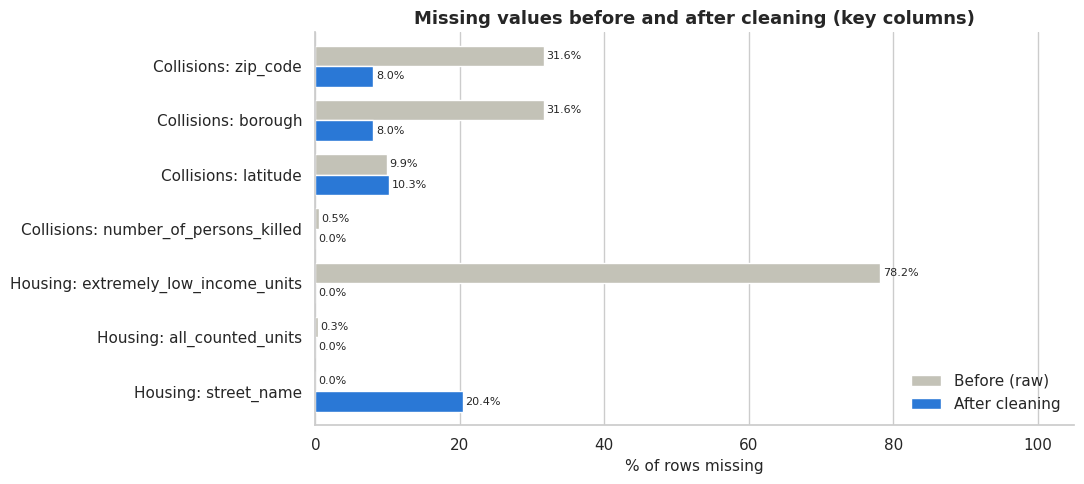

,dataset,step,action,values_or_rows_affected,rows_after
0,collisions,C1,renamed swapped columns off_street_name <-> cr...,2,1964900
1,collisions,C1,dropped redundant column 'location',1,1964900
2,collisions,C2,"parsed crash_date / crash_time into datetime, ...",1964900,1964900
3,collisions,C2,blank ZIP codes -> missing,20,1964900
4,collisions,C2,non-NYC / invalid ZIP codes -> missing,2,1964900
5,collisions,C2,street names trimmed / spaces collapsed / uppe...,49224,1964900
6,collisions,C3,contributing_factor_vehicle_1: 'Unspecified' -...,577910,1964900
7,collisions,C3,contributing_factor_vehicle_1: numeric codes -...,230,1964900
8,collisions,C3,contributing_factor_vehicle_2: 'Unspecified' -...,1357103,1964900
9,collisions,C3,contributing_factor_vehicle_2: numeric codes -...,46,1964900


In [27]:
def missing_share(df, columns):
    return df[columns].isna().mean().mul(100)


before_after = pd.DataFrame({
    "before": pd.concat([missing_share(df_collisions_raw, ["zip_code", "borough", "latitude", "number_of_persons_killed"])
                         .rename(lambda c: f"Collisions: {c}"),
                         missing_share(df_housing_raw, ["extremely_low_income_units",
                                       "all_counted_units", "street_name"]).rename(lambda c: f"Housing: {c}")]),
    "after": pd.concat([missing_share(collisions, ["zip_code", "borough", "latitude", "number_of_persons_killed"])
                        .rename(lambda c: f"Collisions: {c}"),
                        missing_share(housing, ["extremely_low_income_units", "all_counted_units", "street_name"])
                        .rename(lambda c: f"Housing: {c}")]),
})
# Note: "before" counts only *visible* gaps. Hidden ones (e.g., '----' streets, (0, 0) coordinates) look complete in the
# raw data and become visible as missing after cleaning - so some bars grow on purpose.

ax = before_after.plot(kind="barh", figsize=(11, 5), color=["#c3c2b7", PALETTE[0]], width=0.75)
horizontal_bar_grid(ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_title("Missing values before and after cleaning (key columns)")
ax.set_xlabel("% of rows missing")
ax.set_xlim(0, 105)
ax.invert_yaxis()
ax.legend(["Before (raw)", "After cleaning"], frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df

---
# 5. Integration

The datasets share no key and describe different things (≈9.5 thousand buildings vs ≈2 million crashes), so — as
planned in Section 2.5 — they are brought to **common units of analysis** instead of being matched record by record.

| Output table | One row = | Built from | Used for |
|---|---|---|---|
| `zip_year` | one ZIP code in one year | crashes and completed housing, each aggregated to ZIP × year | neighbourhood comparisons and trends |
| `buildings` | one affordable-housing building | each building + every crash within 250 m of it | street-level exposure, before/after completion |
| `collisions` (enriched) | one crash | distance from each crash to the nearest affordable building | comparing crashes near vs far from affordable housing |

> **Decision — analysis period: the full years 2014 – 2025.**
> *Alternatives considered:* include 2026; annualize 2026.
> *Why:* 2026 is partial for both datasets (crashes end 11 June, completions are still being recorded); including it
> would make the last year look like a collapse in both crashes and housing. Annualizing assumes even seasonality,
> which the crash data do not have.

> **Decision — housing measured at completion (`completion_year`), not at start.**
> *Alternatives considered:* project start year.
> *Why:* the research question is about the streets **residents live on**; residents arrive when a building is
> completed. Units *started* are also kept per ZIP-year as a secondary measure of construction activity.

### 5.1 ZIP code × year

Both datasets are aggregated to one row per ZIP code and year, then joined on a **complete grid** of all ZIP codes ×
all years, so that ZIP-years with crashes but no housing (or the reverse) are kept rather than silently dropped.

In [28]:
# Free memory: the raw snapshots are no longer needed (the cleaned tables are saved in data/processed)
for name in ["df_collisions_raw", "raw_sorted"]:
    globals().pop(name, None)
gc.collect()

FULL_YEARS = list(range(ANALYSIS_START_YEAR, int(collisions["crash_year"].max())))  # 2014 ... last full year
print(f"Analysis years: {FULL_YEARS[0]} - {FULL_YEARS[-1]} ({len(FULL_YEARS)} full years)")

# ---------- 5.1 Collisions -> ZIP x year ----------
crashes_full = collisions[collisions["crash_year"].isin(FULL_YEARS)].copy()
crashes_full["injury_or_fatal"] = crashes_full["severity"].ne("Property damage only")
crashes_full["hurts_pedestrian"] = crashes_full["pedestrian_casualties"] > 0

crash_zip_year = (crashes_full.dropna(subset=["zip_code"])
                  .groupby(["zip_code", "crash_year"])
                  .agg(crashes=("collision_id", "size"),
                       injury_or_fatal_crashes=("injury_or_fatal", "sum"),
                       persons_injured=("number_of_persons_injured", "sum"),
                       persons_killed=("number_of_persons_killed", "sum"),
                       pedestrian_casualties=("pedestrian_casualties", "sum"),
                       pedestrians_killed=("number_of_pedestrians_killed", "sum"),
                       cyclist_casualties=("cyclist_casualties", "sum"),
                       crashes_hurting_pedestrians=("hurts_pedestrian", "sum"))
                  .reset_index()
                  .rename(columns={"crash_year": "year"}))
crash_zip_borough = (crashes_full.dropna(subset=["zip_code", "borough"])
                     .groupby("zip_code")["borough"].agg(lambda s: s.value_counts().index[0])
                     .rename("borough_from_crashes"))

# ---------- 5.1 Housing -> ZIP x year (completed, and started) ----------
housing_zip = housing.dropna(subset=["postcode"])
completed = (housing_zip[housing_zip["completion_year"].isin(FULL_YEARS)]
             .assign(nc_units=lambda d: d["all_counted_units"].where(d["reporting_construction_type"] == "New Construction", 0),
                     family_units=lambda d: d[["_3_br_units", "_4_br_units", "_5_br_units", "_6_br_units"]].sum(axis=1))
             .groupby(["postcode", "completion_year"])
             .agg(buildings_completed=("project_id", "size"),
                  affordable_units_completed=("all_counted_units", "sum"),
                  deeply_affordable_units_completed=("deeply_affordable_units", "sum"),
                  new_construction_units_completed=("nc_units", "sum"),
                  family_size_units_completed=("family_units", "sum"))
             .reset_index()
             .rename(columns={"postcode": "zip_code", "completion_year": "year"}))
started = (housing_zip[housing_zip["start_year"].isin(FULL_YEARS)]
           .groupby(["postcode", "start_year"])
           .agg(affordable_units_started=("all_counted_units", "sum"))
           .reset_index()
           .rename(columns={"postcode": "zip_code", "start_year": "year"}))
housing_zip_borough = housing_zip.groupby("postcode")["borough"].agg(lambda s: s.value_counts().index[0]) \
                                 .rename("borough_from_housing")

# ---------- 5.1 Join on a complete ZIP x year grid ----------
# A complete grid keeps ZIP-years with crashes but no housing (and vice versa) instead of silently dropping them.
all_zips = sorted(set(crash_zip_year["zip_code"]) | set(completed["zip_code"]) | set(started["zip_code"]))
grid = pd.MultiIndex.from_product([all_zips, FULL_YEARS], names=["zip_code", "year"]).to_frame(index=False)
zip_year_joined = (grid
                   .merge(crash_zip_year, on=["zip_code", "year"], how="left", validate="one_to_one")
                   .merge(completed, on=["zip_code", "year"], how="left", validate="one_to_one")
                   .merge(started, on=["zip_code", "year"], how="left", validate="one_to_one")
                   .merge(crash_zip_borough, left_on="zip_code", right_index=True, how="left")
                   .merge(housing_zip_borough, left_on="zip_code", right_index=True, how="left"))

print(f"Grid: {len(all_zips)} ZIP codes x {len(FULL_YEARS)} years = {len(zip_year_joined):,} rows")
print(f"ZIP-years with no crash record    : {zip_year_joined['crashes'].isna().sum():,}")
print(f"ZIP-years with no completed housing: {zip_year_joined['buildings_completed'].isna().sum():,}")
zip_year_joined.head()

Analysis years: 2014 - 2025 (12 full years)
Grid: 233 ZIP codes x 12 years = 2,796 rows
ZIP-years with no crash record    : 282
ZIP-years with no completed housing: 1,880


,zip_code,year,crashes,injury_or_fatal_crashes,persons_injured,persons_killed,pedestrian_casualties,pedestrians_killed,cyclist_casualties,crashes_hurting_pedestrians,buildings_completed,affordable_units_completed,deeply_affordable_units_completed,new_construction_units_completed,family_size_units_completed,affordable_units_started,borough_from_crashes,borough_from_housing
0,10000,2014,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,Manhattan,NaN
1,10000,2015,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,Manhattan,NaN
2,10000,2016,104.000,51.000,57.000,0.000,6.000,0.000,37.000,6.000,NaN,NaN,NaN,NaN,NaN,NaN,Manhattan,NaN
3,10000,2017,85.000,19.000,21.000,0.000,1.000,0.000,13.000,1.000,NaN,NaN,NaN,NaN,NaN,NaN,Manhattan,NaN
4,10000,2018,69.000,16.000,18.000,0.000,1.000,0.000,10.000,1.000,NaN,NaN,NaN,NaN,NaN,NaN,Manhattan,NaN


### 5.2 Street level: crashes around each affordable building

> **Decision — one row per building, 250 m radius, great-circle distance.**
> *Alternatives considered:* radius of 150 m or 500 m; one row per (project, building) record.
> *Why:* 250 m is about two to three NYC blocks — the streets a resident walks every day (≈ 3-minute walk). 150 m
> misses the nearest avenue in many places; 500 m merges different neighbourhoods. Distances are computed with the
> haversine (great-circle) formula on a BallTree index, which is exact for this purpose and fast for 1.8 M crashes.
> Buildings that appear in several projects (Section 4, H4) are counted **once**, with their units summed and their
> **first** completion date, so their surrounding crashes are not double-counted.

> **Decision — before/after windows of 24 months, compared with the citywide change.**
> *Alternatives considered:* 12-month windows; a raw before/after difference.
> *Why:* 12 months is too few crashes for a single building. A raw difference would be dominated by the citywide
> trend (crashes halved in 2020), so each building's change is divided by the **citywide change over the same two
> windows**: a ratio above 1 means crashes near the building rose *more* (or fell less) than in the city as a whole.
> Only buildings whose two windows lie entirely inside the crash data (2014-01-01 to 2026-06-11) get a value.

### 5.3 Crash level: distance to the nearest affordable building

The same cell also measures, for every located crash, the distance to the nearest affordable building. This lets
Section 8 compare crashes *near* (≤ 250 m) and *far from* affordable housing.

In [29]:
from sklearn.neighbors import BallTree

EARTH_RADIUS_M = 6_371_000
BUFFER_M = 250
WINDOW_DAYS = 730  # 24 months

# One row per mappable building: units summed over projects, first completion, attributes of its first project
mappable = housing[housing["is_mappable"]].sort_values(["building_id", "project_start_date"])
buildings = (mappable
             .assign(family_size_units=lambda d: d[["_3_br_units", "_4_br_units", "_5_br_units", "_6_br_units"]].sum(axis=1))
             .groupby("building_id")
             .agg(latitude=("latitude", "first"), longitude=("longitude", "first"),
                  borough=("borough", "first"), zip_code=("postcode", "first"),
                  construction_type=("reporting_construction_type", "first"),
                  projects=("project_id", "nunique"),
                  total_units=("total_units", "max"),
                  affordable_units=("all_counted_units", "sum"),
                  extremely_low_income_units=("extremely_low_income_units", "sum"),
                  very_low_income_units=("very_low_income_units", "sum"),
                  deeply_affordable_units=("deeply_affordable_units", "sum"),
                  family_size_units=("family_size_units", "sum"),
                  first_completion_date=("completion_date", "min"))
             .reset_index())
print(f"Buildings with coordinates: {len(mappable):,} records -> {len(buildings):,} unique buildings")

# Spatial index of all crashes with valid coordinates (all years, so that 2026 can serve as an 'after' window)
crash_points = (collisions.loc[collisions["latitude"].notna(),
                               ["collision_id", "latitude", "longitude", "crash_date", "crash_year",
                                "pedestrian_casualties", "cyclist_casualties", "number_of_persons_injured",
                                "number_of_persons_killed"]]
                .reset_index(drop=True))
crash_tree = BallTree(np.radians(crash_points[["latitude", "longitude"]].to_numpy()), metric="haversine")
neighbours = crash_tree.query_radius(np.radians(buildings[["latitude", "longitude"]].to_numpy()),
                                     r=BUFFER_M / EARTH_RADIUS_M)
print(f"Crash-building pairs within {BUFFER_M} m: {sum(len(n) for n in neighbours):,}")

# Per-crash arrays used for the counts
crash_day = crash_points["crash_date"].to_numpy().astype("datetime64[D]").astype(np.int64)
crash_in_full_years = crash_points["crash_year"].isin(FULL_YEARS).to_numpy()
ped = crash_points["pedestrian_casualties"].to_numpy()
cyc = crash_points["cyclist_casualties"].to_numpy()
injured = crash_points["number_of_persons_injured"].to_numpy()
killed = crash_points["number_of_persons_killed"].to_numpy()

# Citywide daily crash counts -> fast window totals for the comparison
first_day, last_day = crash_day.min(), crash_day.max()
city_daily = np.bincount(crash_day - first_day, minlength=last_day - first_day + 1)
city_cumulative = np.concatenate([[0], np.cumsum(city_daily)])
city_window = lambda start, end: city_cumulative[end - first_day] - city_cumulative[start - first_day]  # [start, end)

completion_day = buildings["first_completion_date"].to_numpy().astype("datetime64[D]").astype(np.int64)
completion_known = buildings["first_completion_date"].notna().to_numpy()
rows = []
for i, idx in enumerate(neighbours):
    in_years = idx[crash_in_full_years[idx]]  # exposure is measured over the full analysis years only
    record = {
        "crashes_per_year": len(in_years) / len(FULL_YEARS),
        "pedestrian_casualties_per_year": ped[in_years].sum() / len(FULL_YEARS),
        "cyclist_casualties_per_year": cyc[in_years].sum() / len(FULL_YEARS),
        "persons_injured_per_year": injured[in_years].sum() / len(FULL_YEARS),
        "persons_killed": int(killed[in_years].sum()),
        "crashes_before": np.nan, "crashes_after": np.nan,
        "ped_casualties_before": np.nan, "ped_casualties_after": np.nan, "city_change_ratio": np.nan,
    }
    if completion_known[i]:
        c = completion_day[i]
        if c - WINDOW_DAYS >= first_day and c + WINDOW_DAYS <= last_day:  # both windows fully observed
            days = crash_day[idx]
            before = (days >= c - WINDOW_DAYS) & (days < c)
            after = (days > c) & (days <= c + WINDOW_DAYS)
            record.update(crashes_before=before.sum(), crashes_after=after.sum(),
                          ped_casualties_before=ped[idx][before].sum(), ped_casualties_after=ped[idx][after].sum(),
                          city_change_ratio=city_window(c + 1, c + WINDOW_DAYS + 1) / city_window(c - WINDOW_DAYS, c))
    rows.append(record)

buildings_joined = pd.concat([buildings, pd.DataFrame(rows)], axis=1)
print(f"Buildings with a complete before/after window: {buildings_joined['crashes_before'].notna().sum():,}")

# ---------- 5.3 Crash level: distance to the nearest affordable building ----------
building_tree = BallTree(np.radians(buildings[["latitude", "longitude"]].to_numpy()), metric="haversine")
distance, _ = building_tree.query(np.radians(crash_points[["latitude", "longitude"]].to_numpy()), k=1)
crash_points["dist_to_affordable_m"] = distance[:, 0] * EARTH_RADIUS_M
collisions = collisions.merge(crash_points[["collision_id", "dist_to_affordable_m"]], on="collision_id",
                              how="left", validate="one_to_one")
print(f"Crashes within {BUFFER_M} m of an affordable building: "
      f"{(collisions['dist_to_affordable_m'] <= BUFFER_M).mean():.1%} of all crashes")
buildings_joined.head()

Buildings with coordinates: 7,593 records -> 7,470 unique buildings
Crash-building pairs within 250 m: 6,746,230
Buildings with a complete before/after window: 4,419
Crashes within 250 m of an affordable building: 51.1% of all crashes


,building_id,latitude,longitude,borough,zip_code,construction_type,projects,total_units,affordable_units,extremely_low_income_units,very_low_income_units,deeply_affordable_units,family_size_units,first_completion_date,crashes_per_year,pedestrian_casualties_per_year,cyclist_casualties_per_year,persons_injured_per_year,persons_killed,crashes_before,crashes_after,ped_casualties_before,ped_casualties_after,city_change_ratio
0,1000025,40.869,-73.924,Manhattan,10034,New Construction,1,26,8,0,0,0,0,2025-11-25,60.167,6.083,1.667,18.500,0,NaN,NaN,NaN,NaN,NaN
1,1000042,40.675,-73.876,Brooklyn,11208,New Construction,1,66,65,0,57,57,0,NaT,55.000,4.917,2.167,30.417,1,NaN,NaN,NaN,NaN,NaN
2,1000088,40.706,-73.792,Queens,11433,New Construction,1,387,387,20,39,59,24,2021-10-14,113.583,13.667,2.250,41.667,2,172.000,120.000,26.000,19.000,0.827
3,1000124,40.727,-73.864,Queens,11374,New Construction,1,78,19,0,0,0,0,2026-05-19,47.833,5.417,1.250,11.417,1,NaN,NaN,NaN,NaN,NaN
4,1000134,40.608,-73.752,Queens,11691,New Construction,1,117,117,71,0,71,0,2023-09-26,38.250,3.417,0.500,12.167,2,50.000,89.000,6.000,11.000,0.904


---
# 6. Post-Integration Cleaning

Joining created new problems that did not exist in either source. Each is resolved below.

> **Decision — join-induced missing values in `zip_year` become 0, but only where 0 is true.**
> *Alternatives considered:* drop incomplete ZIP-years; impute averages.
> *Why:* a ZIP-year missing from the housing aggregate means *no building was completed there that year* — a true
> zero. A ZIP-year missing from the crash aggregate in a ZIP that has crashes in other years means *no crash was
> recorded* — also a true zero. Dropping these rows would remove exactly the "no housing" comparison group; averages
> would invent activity.

> **Decision — remove non-residential ZIP codes: fewer than 120 crashes in 12 years (< 10 per year), and `10000`.**
> *Alternatives considered:* keep all ZIP codes; a population threshold.
> *Why:* NYC has single-building and PO-box ZIP codes (e.g., 10118, the Empire State Building) that are not
> neighbourhoods; their rates are meaningless (one crash changes them by 100%). `10000` is not a postal ZIP code at
> all: the crash geocoder uses it for **Central Park** drives (West Drive, the transverse roads), where nobody lives.
> Population by ZIP is not in either dataset. The housing lost by this rule is counted below.

> **Decision — rates per crash are left missing where a ZIP-year has 0 crashes.**
> *Alternatives considered:* set the rate to 0; drop the ZIP-year.
> *Why:* 0 pedestrian casualties out of 0 crashes is undefined, not 0%. The few such ZIP-years stay in the table
> (their counts are valid) and are simply excluded from rate-based questions.

> **Decision — one borough per ZIP code, taken from the crash records.**
> *Alternatives considered:* the borough from the housing records.
> *Why:* the join produced two borough columns that can disagree. The crash-based borough is the most common
> borough of all crashes in that ZIP code (geographic), and it exists for every ZIP code, whereas the housing-based
> borough exists only where housing was built. Disagreements are listed so they can be checked.

In [30]:
zip_year = zip_year_joined.copy()

# (1) Join-induced missing values -> true zeros
crash_cols = ["crashes", "injury_or_fatal_crashes", "persons_injured", "persons_killed", "pedestrian_casualties",
              "pedestrians_killed", "cyclist_casualties", "crashes_hurting_pedestrians"]
housing_cols = ["buildings_completed", "affordable_units_completed", "deeply_affordable_units_completed",
                "new_construction_units_completed", "family_size_units_completed", "affordable_units_started"]
for cols, label in [(crash_cols, "crash"), (housing_cols, "housing")]:
    filled = zip_year[cols].isna().sum().sum()
    zip_year[cols] = zip_year[cols].fillna(0)
    log_step("zip_year", "P1", f"join-induced missing {label} values -> 0", filled, zip_year)

# (2) Non-residential ZIP codes
crashes_per_zip = zip_year.groupby("zip_code")["crashes"].sum()
non_residential = crashes_per_zip.index[(crashes_per_zip < 120) | (crashes_per_zip.index == "10000")]
lost = completed[completed["zip_code"].isin(non_residential)]
print(f"Non-residential ZIP codes removed: {len(non_residential)} "
      f"(housing lost: {lost['buildings_completed'].sum()} buildings, {lost['affordable_units_completed'].sum():,} units)")
zip_year = zip_year[~zip_year["zip_code"].isin(non_residential)]
log_step("zip_year", "P2", "removed non-residential ZIP codes (< 120 crashes in 12 years; 10000 = Central Park)",
         len(non_residential) * len(FULL_YEARS), zip_year)

# (3) Redundant / conflicting borough columns -> one 'borough'
one_per_zip = zip_year.drop_duplicates("zip_code")
conflict = one_per_zip[one_per_zip["borough_from_housing"].notna()
                       & (one_per_zip["borough_from_housing"] != one_per_zip["borough_from_crashes"])]
print("ZIP codes where the two borough sources disagree:")
print(conflict[["zip_code", "borough_from_crashes", "borough_from_housing"]].to_string(index=False))
zip_year = zip_year.rename(columns={"borough_from_crashes": "borough"}).drop(columns="borough_from_housing")
log_step("zip_year", "P3", "two borough columns -> one (crash-based)", len(conflict), zip_year)

# (4) Data types: float counts created by the NaN-filling -> integers; ZIP as text; year as integer
zip_year[crash_cols + housing_cols] = zip_year[crash_cols + housing_cols].astype(int)
zip_year["year"] = zip_year["year"].astype(int)
zip_year["zip_code"] = zip_year["zip_code"].astype(str)
log_step("zip_year", "P4", "float counts (from NaN-filling) -> int", len(crash_cols + housing_cols), zip_year)

# (5) Derived rates. A rate per crash is undefined when a ZIP-year has 0 crashes -> left missing (not 0, not infinite)
has_crashes = zip_year["crashes"] > 0
zip_year["ped_casualties_per_100_crashes"] = (100 * zip_year["pedestrian_casualties"] / zip_year["crashes"]).where(has_crashes)
zip_year["injury_crash_share"] = (zip_year["injury_or_fatal_crashes"] / zip_year["crashes"]).where(has_crashes)
print("ZIP-years with 0 crashes (rates undefined, kept as missing):")
print(zip_year.loc[~has_crashes, ["zip_code", "year", "borough"]].to_string(index=False))
log_step("zip_year", "P5", "rates undefined where crashes = 0 -> missing", (~has_crashes).sum(), zip_year)
zip_year = zip_year.reset_index(drop=True)
print(f"\nzip_year: {len(zip_year):,} rows = {zip_year['zip_code'].nunique()} ZIP codes x {len(FULL_YEARS)} years")
zip_year.head()

[zip_year] P1: join-induced missing crash values -> 0 -> 2,256 affected | 2,796 rows
[zip_year] P1: join-induced missing housing values -> 0 -> 11,121 affected | 2,796 rows
Non-residential ZIP codes removed: 48 (housing lost: 2 buildings, 416 units)
[zip_year] P2: removed non-residential ZIP codes (< 120 crashes in 12 years; 10000 = Central Park) -> 576 affected | 2,220 rows
ZIP codes where the two borough sources disagree:
Empty DataFrame
Columns: [zip_code, borough_from_crashes, borough_from_housing]
Index: []
[zip_year] P3: two borough columns -> one (crash-based) -> 0 affected | 2,220 rows
[zip_year] P4: float counts (from NaN-filling) -> int -> 14 affected | 2,220 rows
ZIP-years with 0 crashes (rates undefined, kept as missing):
zip_code  year       borough
   10168  2014     Manhattan
   10172  2014     Manhattan
   10172  2015     Manhattan
   10303  2015 Staten Island
[zip_year] P5: rates undefined where crashes = 0 -> missing -> 4 affected | 2,220 rows

zip_year: 2,220 rows = 

,zip_code,year,crashes,injury_or_fatal_crashes,persons_injured,persons_killed,pedestrian_casualties,pedestrians_killed,cyclist_casualties,crashes_hurting_pedestrians,buildings_completed,affordable_units_completed,deeply_affordable_units_completed,new_construction_units_completed,family_size_units_completed,affordable_units_started,borough,ped_casualties_per_100_crashes,injury_crash_share
0,10001,2014,2069,211,248,1,104,1,42,96,0,0,0,0,0,194,Manhattan,5.027,0.102
1,10001,2015,2125,232,256,2,109,1,42,108,0,0,0,0,0,188,Manhattan,5.129,0.109
2,10001,2016,2097,252,280,1,113,1,49,109,1,174,151,0,0,174,Manhattan,5.389,0.120
3,10001,2017,2047,242,258,4,100,1,48,97,7,1460,552,0,96,1460,Manhattan,4.885,0.118
4,10001,2018,1921,213,233,1,85,1,43,83,2,194,6,194,2,52,Manhattan,4.425,0.111


> **Decision — buildings: keep missing before/after values, flag them, and remove redundant columns.**
> *Alternatives considered:* fill missing before/after counts with 0; drop buildings without a full window.
> *Why:* a missing before/after value means the window was **not observed** (completion too early or too late, or not
> completed) — it is not zero crashes, so filling with 0 would fake a result. Dropping the buildings would remove
> them from the exposure analysis, which does not need the windows. A flag (`has_before_after`) selects the right
> subset for each question. A relative change is undefined when there were no crashes before; such buildings are
> flagged rather than given an infinite value.

In [31]:
buildings_clean = buildings_joined.copy()

# (1) Flags instead of fake values
buildings_clean["has_before_after"] = buildings_clean["crashes_before"].notna()
buildings_clean["relative_change"] = ((buildings_clean["crashes_after"] / buildings_clean["crashes_before"])
                                      / buildings_clean["city_change_ratio"])
undefined = buildings_clean["has_before_after"] & (buildings_clean["crashes_before"] == 0)
buildings_clean.loc[undefined, "relative_change"] = np.nan
log_step("buildings", "P5", "before/after not observed -> kept missing + flag has_before_after",
         (~buildings_clean["has_before_after"]).sum(), buildings_clean)
log_step("buildings", "P5", "relative change undefined (0 crashes before) -> missing", undefined.sum(), buildings_clean)

# (2) Type mismatches: counts that went through NaN are floats -> nullable integers
for column in ["crashes_before", "crashes_after", "ped_casualties_before", "ped_casualties_after"]:
    buildings_clean[column] = buildings_clean[column].astype("Int64")
buildings_clean["building_id"] = buildings_clean["building_id"].astype(str)
log_step("buildings", "P6", "before/after counts float -> Int64; building_id -> text", 5, buildings_clean)

# (3) Derived descriptors used in the research questions
buildings_clean["deep_affordability_share"] = np.where(
    buildings_clean["affordable_units"] > 0,
    buildings_clean["deeply_affordable_units"] / buildings_clean["affordable_units"], np.nan)
buildings_clean["completion_year"] = buildings_clean["first_completion_date"].dt.year.astype("Int64")

# (4) Redundant column check: no column may be an exact copy of another
duplicated_columns = buildings_clean.T.duplicated()
print("Exact duplicate columns in buildings:", list(buildings_clean.columns[duplicated_columns]))
duplicated_columns = zip_year.T.duplicated()
print("Exact duplicate columns in zip_year :", list(zip_year.columns[duplicated_columns]))

# Save the integrated tables (used by Section 8 and the website)
zip_year.to_parquet(os.path.join(PROCESSED_DIR, "zip_year_panel.parquet"), index=False)
buildings_clean.to_parquet(os.path.join(PROCESSED_DIR, "buildings_exposure.parquet"), index=False)
print(f"Saved zip_year ({len(zip_year):,} rows) and buildings ({len(buildings_clean):,} rows) to {PROCESSED_DIR}")

[buildings] P5: before/after not observed -> kept missing + flag has_before_after -> 3,051 affected | 7,470 rows
[buildings] P5: relative change undefined (0 crashes before) -> missing -> 22 affected | 7,470 rows
[buildings] P6: before/after counts float -> Int64; building_id -> text -> 5 affected | 7,470 rows
Exact duplicate columns in buildings: []
Exact duplicate columns in zip_year : []
Saved zip_year (2,220 rows) and buildings (7,470 rows) to /content/drive/MyDrive/nyc-housing-transport/data/processed


---
# 7. Validating the Integrated Data

Integration is only trustworthy if nothing was lost or double-counted. The checks below reconcile the integrated
tables with the cleaned sources and test their keys and value ranges; every check must print `True`.

,passed
"zip_year key (zip_code, year) is unique",True
every ZIP has all 12 years,True
crash totals reconcile with the cleaned crashes,True
unit totals reconcile with the cleaned housing,True
no missing values except undefined rates,True
rates missing exactly where crashes = 0,True
counts are non-negative,True
pedestrian casualties <= injured + killed,True
buildings key (building_id) is unique,True
before/after counts present only for completed buildings,True


Crashes in the panel: 1,768,213 of 1,926,900 full-year crashes (91.8%); the rest have no recoverable ZIP code or are in the excluded non-residential ZIP codes


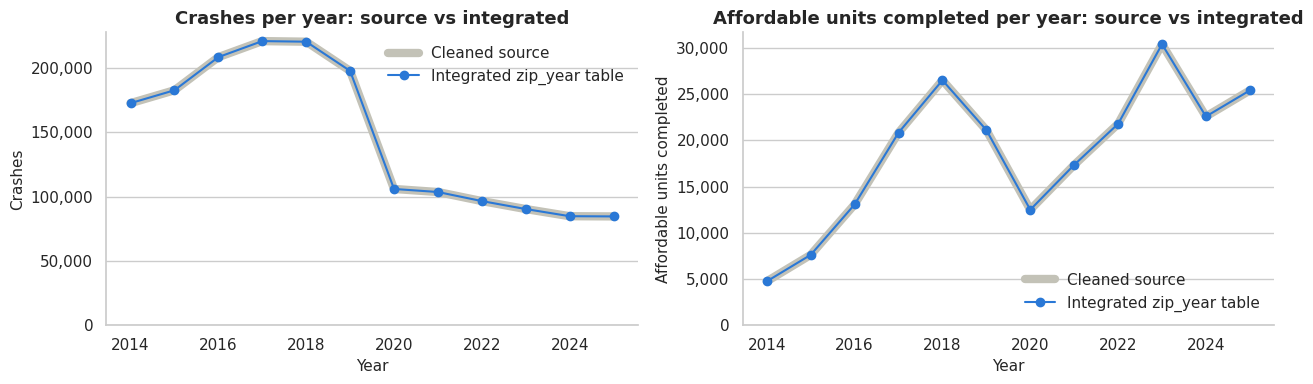

In [32]:
in_universe_zip = set(zip_year["zip_code"])
source_crashes = crashes_full["zip_code"].isin(in_universe_zip).sum()
source_units = housing_zip.loc[housing_zip["completion_year"].isin(FULL_YEARS)
                               & housing_zip["postcode"].isin(in_universe_zip), "all_counted_units"].sum()

checks = {
    "zip_year key (zip_code, year) is unique": not zip_year.duplicated(["zip_code", "year"]).any(),
    "every ZIP has all 12 years": zip_year.groupby("zip_code").size().eq(len(FULL_YEARS)).all(),
    "crash totals reconcile with the cleaned crashes": zip_year["crashes"].sum() == source_crashes,
    "unit totals reconcile with the cleaned housing": zip_year["affordable_units_completed"].sum() == source_units,
    "no missing values except undefined rates": not zip_year.drop(
        columns=["ped_casualties_per_100_crashes", "injury_crash_share"]).isna().any().any(),
    "rates missing exactly where crashes = 0": zip_year["ped_casualties_per_100_crashes"].isna().eq(
        zip_year["crashes"].eq(0)).all(),
    "counts are non-negative": (zip_year[crash_cols + housing_cols] >= 0).all().all(),
    "pedestrian casualties <= injured + killed": (zip_year["pedestrian_casualties"]
                                                  <= zip_year["persons_injured"] + zip_year["persons_killed"]).all(),
    "buildings key (building_id) is unique": buildings_clean["building_id"].is_unique,
    "before/after counts present only for completed buildings": buildings_clean.loc[
        buildings_clean["has_before_after"], "first_completion_date"].notna().all(),
    "before/after counts are non-negative": (buildings_clean.loc[buildings_clean["has_before_after"],
                                             ["crashes_before", "crashes_after"]] >= 0).all().all(),
    "building coordinates inside NYC": buildings_clean["latitude"].between(NYC_BOUNDS["lat_min"], NYC_BOUNDS["lat_max"]).all(),
    "crash rows unchanged by the distance merge": len(collisions) == collisions["collision_id"].nunique(),
}
display(pd.Series(checks, name="passed").to_frame())
print(f"Crashes in the panel: {zip_year['crashes'].sum():,} of {len(crashes_full):,} full-year crashes "
      f"({zip_year['crashes'].sum() / len(crashes_full):.1%}); the rest have no recoverable ZIP code "
      "or are in the excluded non-residential ZIP codes")

# Visual check: citywide yearly totals from the integrated panel vs directly from the cleaned sources
panel_by_year = zip_year.groupby("year")[["crashes", "affordable_units_completed"]].sum()
source_by_year = pd.DataFrame({
    "crashes": crashes_full[crashes_full["zip_code"].isin(in_universe_zip)].groupby("crash_year").size(),
    "affordable_units_completed": housing_zip[housing_zip["postcode"].isin(in_universe_zip)
                                              & housing_zip["completion_year"].isin(FULL_YEARS)]
                                  .groupby("completion_year")["all_counted_units"].sum(),
})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, title in [(axes[0], "crashes", "Crashes per year"),
                          (axes[1], "affordable_units_completed", "Affordable units completed per year")]:
    ax.plot(source_by_year.index, source_by_year[column], color="#c3c2b7", linewidth=6, label="Cleaned source")
    ax.plot(panel_by_year.index, panel_by_year[column], color=PALETTE[0], marker="o", linewidth=1.5,
            label="Integrated zip_year table")
    ax.set_title(f"{title}: source vs integrated")
    ax.set_xlabel("Year")
    ax.set_ylabel(title.split(" per")[0])
    ax.set_ylim(0)
    thousands(ax)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

---
# 8. Research Questions & Visualizations

Twelve questions — two per team member — each look at one angle of the main question, at one of the three
integrated levels (ZIP × year, building + 250 m, or crash near/far). Every question has **one chart** that directly
answers it, a statistical check where a pattern is claimed, and an honest reading of what the result does **not** show.

| # | Member | Question (short) | Level | Chart |
|---|---|---|---|---|
| RQ1 | Ahmed Saadallah | More affordable housing ↔ more dangerous streets for pedestrians? | ZIP | scatter |
| RQ2 | Ahmed Saadallah | Are *deeply* affordable homes more exposed than other affordable homes? | building | box plot |
| RQ3 | Ismail Ahmed Mohamed | Do crashes rise around a building after it opens, beyond the city trend? | building | histogram |
| RQ4 | Ismail Ahmed Mohamed | New construction vs preservation: who lives on busier streets? | building | grouped bar |
| RQ5 | Ziad Elshayeb | When are pedestrians hurt near affordable housing vs elsewhere? | crash | diverging heatmap |
| RQ6 | Ziad Elshayeb | Which recorded crash causes differ near affordable housing? | crash | diverging bar |
| RQ7 | Renad Osama | Has the pedestrian-safety gap of high-production ZIPs changed since 2014? | ZIP × year | line chart |
| RQ8 | Renad Osama | Did cyclist casualties grow faster where more affordable housing was built? | ZIP | scatter |
| RQ9 | Yassin Amr | Which vehicle types are over-represented in crashes near affordable housing? | crash | grouped bar |
| RQ10 | Yassin Amr | Where do heavy affordable production and pedestrian danger overlap? | ZIP | bubble map |
| RQ11 | Yassin Elazab | Within the same ZIP code, are crashes near affordable housing more harmful to pedestrians? | crash within ZIP | box + strip plot |
| RQ12 | Yassin Elazab | Does a year of heavy housing completion predict next year's crash change? | ZIP × year | scatter |

**Measures used throughout.** *Pedestrian casualties* = pedestrians injured + killed. *Pedestrian casualties per 100
crashes* measures how often crashes on an area's streets hurt someone on foot; it is used instead of a per-resident
rate because population is not in either dataset (see Section 9, limitations). Statistical tests are non-parametric
(Spearman, Mann-Whitney, Wilcoxon, sign test) because every count in this project is strongly skewed (Section 3).

In [33]:
from scipy import stats

# Crash-level table for the near/far questions: full years, valid coordinates
crashes_located = collisions[collisions["crash_year"].isin(FULL_YEARS)
                             & collisions["dist_to_affordable_m"].notna()].copy()
crashes_located["near_affordable"] = crashes_located["dist_to_affordable_m"] <= BUFFER_M
crashes_located["hurts_pedestrian"] = crashes_located["pedestrian_casualties"] > 0
NEAR_LABELS = {True: f"Within {BUFFER_M} m of affordable housing", False: f"Farther than {BUFFER_M} m"}

# ZIP-level totals over the 12 full years
zip_totals = (zip_year.groupby(["zip_code", "borough"], as_index=False)
              [["crashes", "pedestrian_casualties", "cyclist_casualties", "affordable_units_completed",
                "deeply_affordable_units_completed"]].sum())
zip_totals["ped_casualties_per_100_crashes"] = 100 * zip_totals["pedestrian_casualties"] / zip_totals["crashes"]

print(f"Crashes with a location in {FULL_YEARS[0]}-{FULL_YEARS[-1]}: {len(crashes_located):,} "
      f"({crashes_located['near_affordable'].mean():.1%} within {BUFFER_M} m of an affordable building)")
print(f"ZIP codes: {len(zip_totals)}; buildings: {len(buildings_clean):,}")

Crashes with a location in 2014-2025: 1,726,693 (57.0% within 250 m of an affordable building)
ZIP codes: 185; buildings: 7,470


## RQ1 — Ahmed Saadallah
### Do ZIP codes that received more affordable housing have streets that are more dangerous for pedestrians?

**Why it matters:** if new affordable homes are concentrated where crashes most often hurt people on foot, the
households with the fewest alternatives to walking carry the most risk.
**Method:** for each ZIP code, affordable units completed in 2014 – 2025 vs pedestrian casualties per 100 crashes over
the same years; Spearman rank correlation (robust to the skew in unit counts).

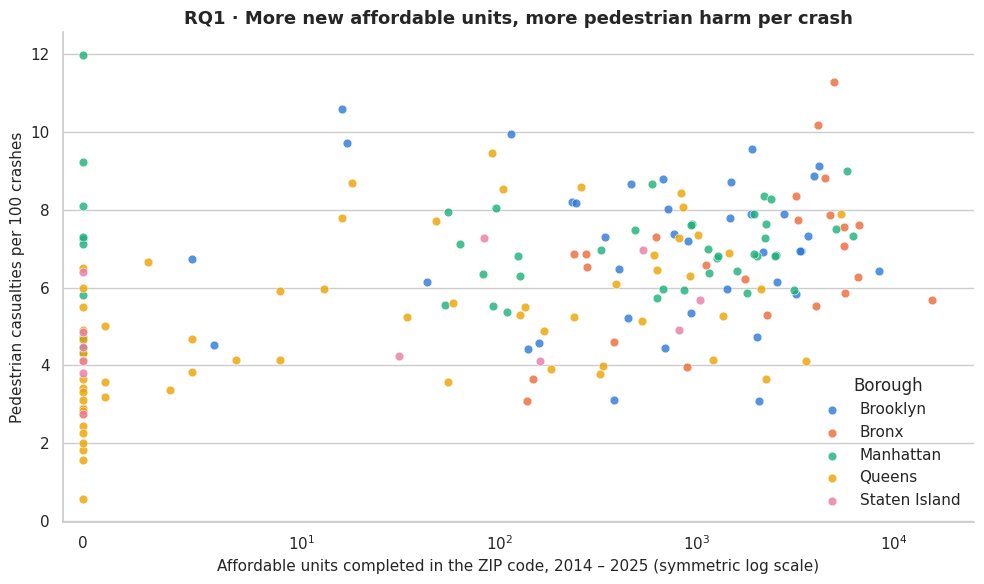

Spearman rho = 0.45, p = 1.8e-10, n = 185 ZIP codes
production_quartile
Q1 (least)   4.330
Q2           6.050
Q3           6.670
Q4 (most)    7.170


In [34]:
fig, ax = plt.subplots(figsize=(10, 6))
for borough in BOROUGH_ORDER:
    part = zip_totals[zip_totals["borough"] == borough]
    ax.scatter(part["affordable_units_completed"], part["ped_casualties_per_100_crashes"], s=40, alpha=0.8,
               color=BOROUGH_COLORS[borough], label=borough, edgecolor="white", linewidth=0.5)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(left=-0.9)  # small margin so points at 0 are fully visible
ax.set_xlabel("Affordable units completed in the ZIP code, 2014 – 2025 (symmetric log scale)")
ax.set_ylabel("Pedestrian casualties per 100 crashes")
ax.set_title("RQ1 · More new affordable units, more pedestrian harm per crash")
ax.legend(title="Borough", frameon=False)
plt.tight_layout()
plt.show()

rho, p_value = stats.spearmanr(zip_totals["affordable_units_completed"], zip_totals["ped_casualties_per_100_crashes"])
print(f"Spearman rho = {rho:.2f}, p = {p_value:.1e}, n = {len(zip_totals)} ZIP codes")
zip_totals["production_quartile"] = pd.qcut(zip_totals["affordable_units_completed"].rank(method="first"), 4,
                                            labels=["Q1 (least)", "Q2", "Q3", "Q4 (most)"])
print(zip_totals.groupby("production_quartile", observed=True)["ped_casualties_per_100_crashes"].median()
      .round(2).rename("median pedestrian casualties per 100 crashes").to_string())

**Answer.** Yes — clearly. The more affordable units a ZIP code received, the more often its crashes hurt pedestrians
(Spearman ρ ≈ 0.45, p < 0.001). In the quarter of ZIP codes with the most new affordable housing, about 7.2 of every
100 crashes hurt a pedestrian, against 4.3 in the quarter with the least.

**What this does *not* show:** that housing makes streets dangerous. Affordable housing is built in dense,
walkable neighbourhoods where more people are on foot, so crashes there are more likely to involve pedestrians. The
finding is about *who is exposed*, not about cause.

## RQ2 — Ahmed Saadallah
### Are deeply affordable homes (mostly for households earning ≤ 50% of AMI) surrounded by more pedestrian casualties than other affordable homes?

**Why it matters:** the poorest households are the least likely to own a car. If their buildings sit on the most
dangerous blocks *within* the affordable stock, street-safety money should follow them.
**Method:** buildings grouped by the share of their affordable units that are extremely-low or very-low income
(none, under half, half or more); pedestrian casualties per year within 250 m; Mann-Whitney test of "≥ 50%" vs "none".

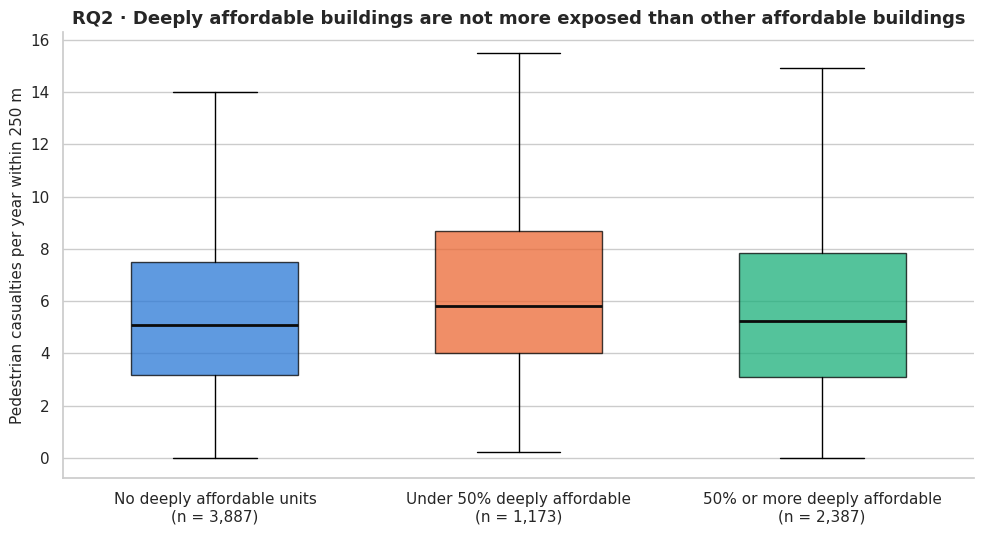

             count  median  mean
deep_group                      
None          3887   5.080 5.650
Under 50%     1173   5.830 6.620
50% or more   2387   5.250 5.810
Mann-Whitney '50% or more' vs 'None': p = 0.094


In [35]:
buildings_clean["deep_group"] = pd.cut(buildings_clean["deep_affordability_share"], [-0.01, 0, 0.4999, 1],
                                       labels=["None", "Under 50%", "50% or more"])
groups = [g["pedestrian_casualties_per_year"].to_numpy()
          for _, g in buildings_clean.dropna(subset=["deep_group"]).groupby("deep_group", observed=True)]

fig, ax = plt.subplots(figsize=(10, 5.5))
box = ax.boxplot(groups, showfliers=False, patch_artist=True, widths=0.55,
                 medianprops={"color": "#0b0b0b", "linewidth": 2})
for patch, color in zip(box["boxes"], PALETTE[:3]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax.set_xticks([1, 2, 3], [f"{label}\n(n = {len(g):,})" for label, g in
                          zip(["No deeply affordable units", "Under 50% deeply affordable", "50% or more deeply affordable"],
                              groups)])
ax.set_ylabel(f"Pedestrian casualties per year within {BUFFER_M} m")
ax.set_title("RQ2 · Deeply affordable buildings are not more exposed than other affordable buildings")
plt.tight_layout()
plt.show()

print(buildings_clean.groupby("deep_group", observed=True)["pedestrian_casualties_per_year"]
      .agg(["count", "median", "mean"]).round(2).to_string())
u_stat, p_value = stats.mannwhitneyu(groups[2], groups[0], alternative="two-sided")
print(f"Mann-Whitney '50% or more' vs 'None': p = {p_value:.3f}")

**Answer.** No meaningful difference. Buildings where at least half of the units are deeply affordable have about the
same pedestrian exposure (median ≈ 5.3 casualties per year within 250 m) as buildings with no deeply affordable units
(≈ 5.1); the difference is not statistically significant (p ≈ 0.09). Mixed buildings sit slightly higher.

**Reading it correctly:** within the affordable stock, *which income band* a building serves does not change its
street exposure much — the big differences are *between neighbourhoods* (RQ1, RQ10), not between building types in
the same places. A null result here is informative: targeting should be by location, not by income band alone.

## RQ3 — Ismail Ahmed Mohamed
### After an affordable building is completed, do crashes on the surrounding streets rise more than in the city as a whole?

**Why it matters:** new residents bring new trips (deliveries, pick-ups, children walking to school). If crashes rise
around new buildings, safety improvements should arrive *with* the building, not years later.
**Method:** for every building with complete 24-month windows (Section 5.2), the change in crashes within 250 m
divided by the citywide change in the same windows (**relative change**; 1 = same as the city). New construction is
compared with preservation: preserved buildings were already occupied, so they act as a natural comparison group.
A sign test checks whether more than half of the buildings rose faster than the city.

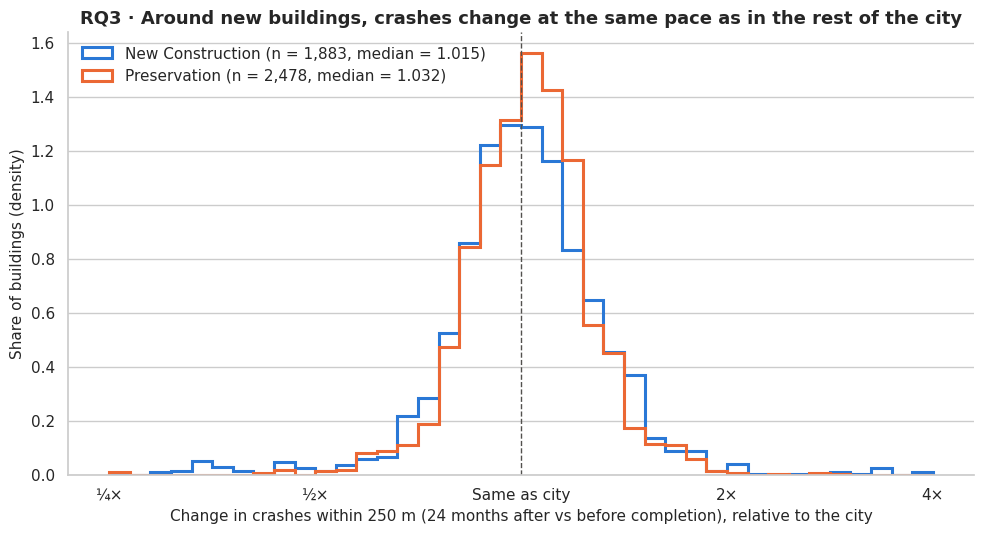

New Construction: median relative change 1.015; 52.0% rose faster than the city; sign test p = 0.0798
Preservation    : median relative change 1.032; 56.7% rose faster than the city; sign test p = 3.62e-11
(Excluded: 58 buildings with 0 crashes before or after, where a ratio is undefined or 0)


In [36]:
before_after = buildings_clean[buildings_clean["has_before_after"] & buildings_clean["relative_change"].gt(0)].copy()
before_after["log2_relative_change"] = np.log2(before_after["relative_change"])

fig, ax = plt.subplots(figsize=(10, 5.5))
bins = np.linspace(-2, 2, 41)
for color, (ctype, group) in zip(PALETTE[:2], before_after.groupby("construction_type")):
    ax.hist(group["log2_relative_change"].clip(-2, 2), bins=bins, histtype="step", linewidth=2.2, color=color,
            density=True, label=f"{ctype} (n = {len(group):,}, median = {group['relative_change'].median():.3f})")
ax.axvline(0, color="#52514e", linestyle="--", linewidth=1)
ax.set_xticks([-2, -1, 0, 1, 2], ["¼×", "½×", "Same as city", "2×", "4×"])
ax.set_xlabel(f"Change in crashes within {BUFFER_M} m (24 months after vs before completion), relative to the city")
ax.set_ylabel("Share of buildings (density)")
ax.set_title("RQ3 · Around new buildings, crashes change at the same pace as in the rest of the city")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

for ctype, group in before_after.groupby("construction_type"):
    rose = (group["relative_change"] > 1).sum()
    test = stats.binomtest(rose, len(group), 0.5)
    print(f"{ctype:<16}: median relative change {group['relative_change'].median():.3f}; "
          f"{rose / len(group):.1%} rose faster than the city; sign test p = {test.pvalue:.3g}")
print(f"(Excluded: {(buildings_clean['has_before_after'] & ~buildings_clean['relative_change'].gt(0)).sum()} buildings "
      "with 0 crashes before or after, where a ratio is undefined or 0)")

**Answer.** No detectable "new building effect". Around **new construction**, crashes changed almost exactly like the
citywide trend (median relative change ≈ 1.02; 52% of buildings above the city, 48% below; sign test p ≈ 0.08, not
significant).
Around **preserved** buildings — where no new residents arrived — crashes rose very slightly faster than the city
(median ≈ 1.03, significant only because n is large), which is the opposite of what a new-resident effect would
produce.

**Limits:** 24 months may be too short for travel patterns to adjust; 250 m mixes the building's own street with
nearby arterials; completion dates of large projects may precede full occupancy. The result rules out a large,
immediate jump — not small or slow effects.

## RQ4 — Ismail Ahmed Mohamed
### Does new construction place residents on busier, more crash-prone streets than preservation, borough by borough?

**Why it matters:** new buildings go where land is available — often next to highways, rail yards and arterials.
Preservation keeps existing residents where they already are. If new construction systematically sits on worse
streets, siting decisions (not just traffic policy) shape residents' exposure.
**Method:** median crashes per year within 250 m, by borough and construction type; Mann-Whitney test per borough.

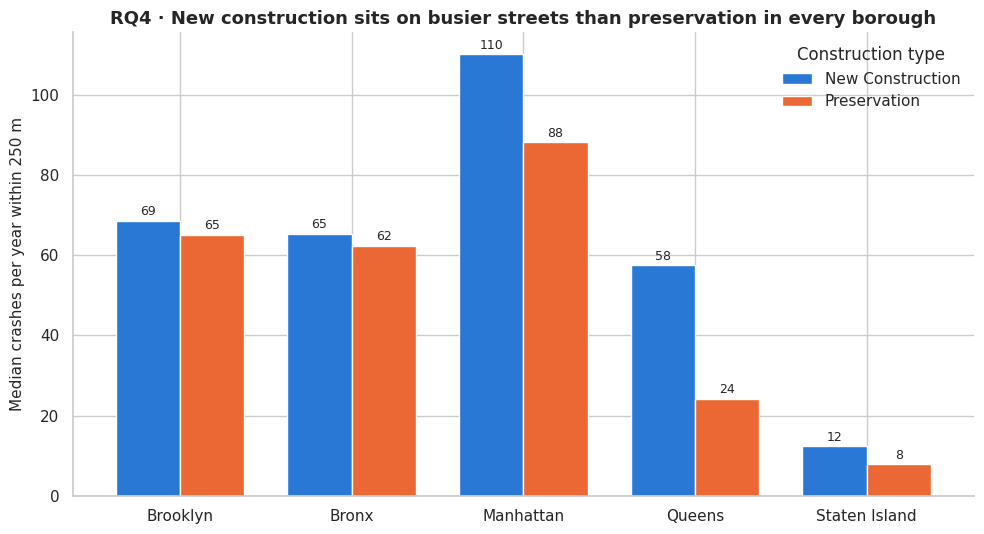

,borough,new_construction_n,preservation_n,ratio_of_medians,mann_whitney_p
0,Brooklyn,1762,1265,1.056,0.074
1,Bronx,1000,1164,1.048,0.017
2,Manhattan,282,1096,1.249,0.000
3,Queens,462,313,2.379,0.000
4,Staten Island,35,91,1.575,0.001


In [37]:
exposure_by_type = (buildings_clean.groupby(["borough", "construction_type"])["crashes_per_year"]
                    .median().unstack().reindex(BOROUGH_ORDER))
ax = exposure_by_type.plot(kind="bar", figsize=(10, 5.5), color=PALETTE[:2], width=0.75, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=9, padding=2)
ax.set_xlabel("")
ax.set_ylabel(f"Median crashes per year within {BUFFER_M} m")
ax.set_title("RQ4 · New construction sits on busier streets than preservation in every borough")
ax.legend(title="Construction type", frameon=False)
plt.tight_layout()
plt.show()

rows = []
for borough in BOROUGH_ORDER:
    part = buildings_clean[buildings_clean["borough"] == borough]
    nc = part.loc[part["construction_type"] == "New Construction", "crashes_per_year"]
    pr = part.loc[part["construction_type"] == "Preservation", "crashes_per_year"]
    rows.append({"borough": borough, "new_construction_n": len(nc), "preservation_n": len(pr),
                 "ratio_of_medians": nc.median() / pr.median(),
                 "mann_whitney_p": stats.mannwhitneyu(nc, pr).pvalue})
pd.DataFrame(rows).round(4)

**Answer.** Yes, in every borough. New-construction buildings have more crashes on their surrounding streets than
preserved buildings in the same borough — modestly in the Bronx and Brooklyn (≈ 5% more), more in Manhattan
(≈ 25%) and Staten Island (≈ 58%), and **more than twice as much in Queens** (median 58 vs 24 crashes per year). The
differences are statistically significant in every borough except Brooklyn (p ≈ 0.07).

**Interpretation:** new affordable buildings tend to be sited on busier corridors — consistent with where large
sites are available (e.g., along major roads in Queens). It is a siting pattern, not evidence that the buildings
cause the crashes.

## RQ5 — Ziad Elshayeb
### When during the week are pedestrians hurt near affordable housing, compared with the rest of the city?

**Why it matters:** the timing tells *what kind* of safety measure fits — school-hour crossing guards, night-time
lighting and speed control, or rush-hour signal changes.
**Method:** crashes that hurt at least one pedestrian (time known, i.e. `time_unknown` excluded), split near / far.
For each hour × weekday cell, the share of that group's pedestrian crashes falling in the cell; the chart shows the
**difference in percentage points** (near minus far). Red = relatively more common near affordable housing.

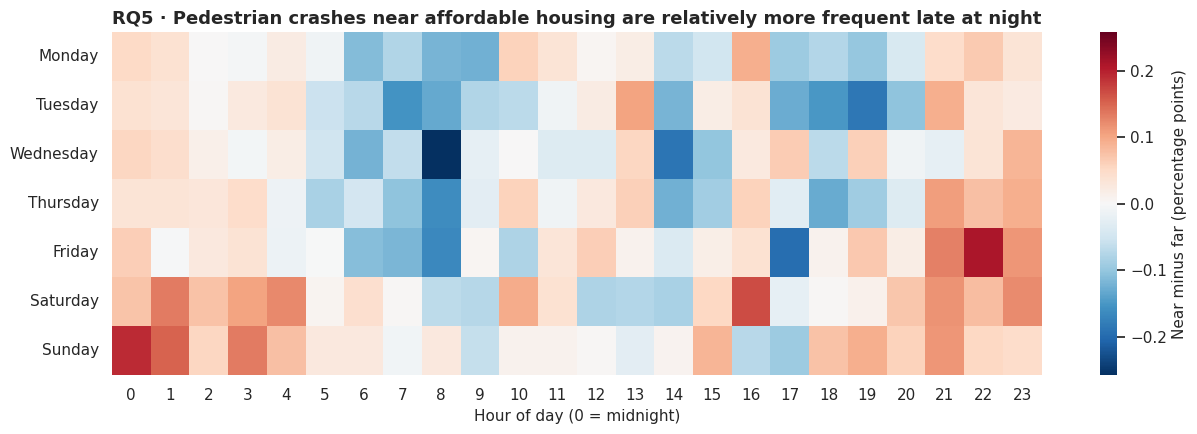

Pedestrian crashes analysed: near = 68,260, far = 35,661
Share between 00:00 and 03:59 - near: 5.1%, far: 3.7%
Share on weekday mornings 07:00-09:59 - near: 11.4%, far: 13.0%


In [38]:
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ped_crashes = crashes_located[crashes_located["hurts_pedestrian"] & ~crashes_located["time_unknown"]].assign(
    weekday=lambda d: d["crash_date"].dt.day_name())


def hour_weekday_share(df):
    # Percentage of a group's crashes in each weekday x hour cell (all cells sum to 100)
    return pd.crosstab(df["weekday"], df["crash_hour"], normalize="all").reindex(WEEKDAY_ORDER) * 100


share_near = hour_weekday_share(ped_crashes[ped_crashes["near_affordable"]])
share_far = hour_weekday_share(ped_crashes[~ped_crashes["near_affordable"]])
difference = share_near - share_far

fig, ax = plt.subplots(figsize=(13, 4.5))
limit = np.abs(difference.to_numpy()).max()
sns.heatmap(difference, cmap="RdBu_r", center=0, vmin=-limit, vmax=limit, ax=ax,
            cbar_kws={"label": "Near minus far (percentage points)"})
ax.set_title("RQ5 · Pedestrian crashes near affordable housing are relatively more frequent late at night")
ax.set_xlabel("Hour of day (0 = midnight)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

night = [0, 1, 2, 3]
print(f"Pedestrian crashes analysed: near = {ped_crashes['near_affordable'].sum():,}, "
      f"far = {(~ped_crashes['near_affordable']).sum():,}")
print(f"Share between 00:00 and 03:59 - near: {share_near[night].sum().sum():.1f}%, far: {share_far[night].sum().sum():.1f}%")
weekday_rush = share_near.loc[WEEKDAY_ORDER[:5], [7, 8, 9]].sum().sum(), share_far.loc[WEEKDAY_ORDER[:5], [7, 8, 9]].sum().sum()
print(f"Share on weekday mornings 07:00-09:59 - near: {weekday_rush[0]:.1f}%, far: {weekday_rush[1]:.1f}%")

**Answer.** Near affordable housing, a larger share of pedestrian crashes happens **late at night** (00:00 – 03:59:
about 5.1% vs 3.7% elsewhere — roughly 40% more, relatively), especially on weekend nights, while the **weekday
morning commute** is relatively *less* prominent than in the rest of the city (where office districts dominate).

**Use:** around affordable housing, night-time measures (lighting, speed enforcement, daylighting of crossings)
matter relatively more than in commuter districts. Shares compare *patterns*, not risk levels.

## RQ6 — Ziad Elshayeb
### Which recorded crash causes are over- or under-represented in pedestrian crashes near affordable housing?

**Why it matters:** causes point to fixes — "failure to yield" calls for turn calming and leading pedestrian
intervals; "pedestrian error/confusion" can signal confusing crossings (or how blame is recorded).
**Method:** crashes that hurt a pedestrian and have a recorded cause for vehicle 1 (`Unspecified` was set to missing
in Section 4); share of each of the 10 most common causes near vs far; chart = difference in percentage points.

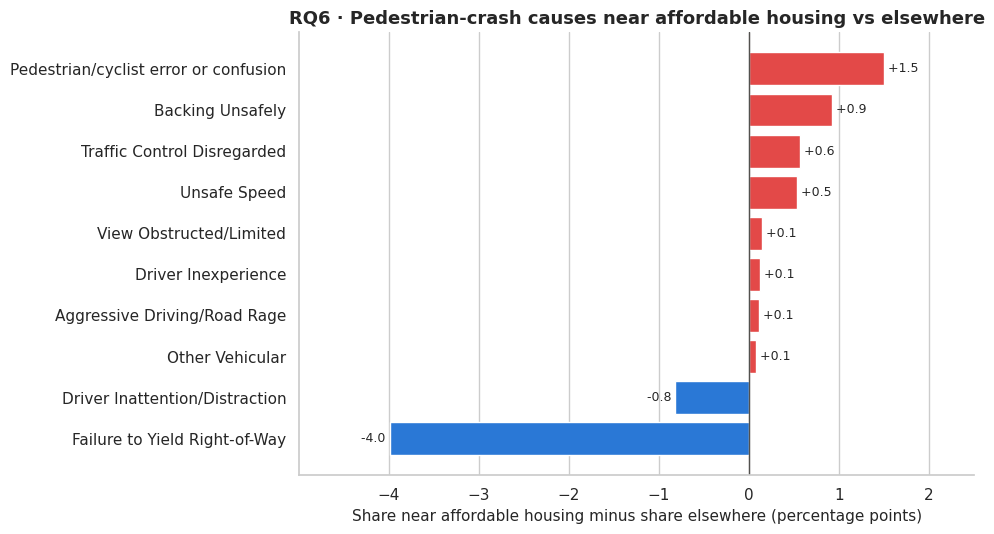

Pedestrian crashes with a recorded cause: 67,680
near_affordable                                        Farther than 250 m  Within 250 m of affordable housing
contributing_factor_vehicle_1                                                                                
Driver Inattention/Distraction                                     35.000                              34.200
Failure to Yield Right-of-Way                                      35.400                              31.400
Backing Unsafely                                                    5.800                               6.700
Pedestrian/Bicyclist/Other Pedestrian Error/Confusion               3.900                               5.400
View Obstructed/Limited                                             2.300                               2.400
Traffic Control Disregarded                                         1.900                               2.400
Unsafe Speed                                                        1.8

In [39]:
with_cause = ped_crashes.dropna(subset=["contributing_factor_vehicle_1"])
top_causes = with_cause["contributing_factor_vehicle_1"].value_counts().head(10).index
cause_share = (with_cause.groupby("near_affordable")["contributing_factor_vehicle_1"]
               .value_counts(normalize=True).unstack(0).mul(100).reindex(top_causes))
cause_diff = (cause_share[True] - cause_share[False]).sort_values()
short_names = {"Pedestrian/Bicyclist/Other Pedestrian Error/Confusion": "Pedestrian/cyclist error or confusion"}

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh([short_names.get(c, c) for c in cause_diff.index], cause_diff.values, color=[PALETTE[0] if v < 0 else PALETTE[7] for v in cause_diff.values])
ax.axvline(0, color="#52514e", linewidth=1)
horizontal_bar_grid(ax)
for y, value in enumerate(cause_diff.values):
    ax.text(value, y, f" {value:+.1f} " if value >= 0 else f"{value:+.1f} ", va="center",
            ha="left" if value >= 0 else "right", fontsize=9)
ax.set_xlim(cause_diff.min() - 1, cause_diff.max() + 1)
ax.set_xlabel("Share near affordable housing minus share elsewhere (percentage points)")
ax.set_title("RQ6 · Pedestrian-crash causes near affordable housing vs elsewhere")
plt.tight_layout()
plt.show()

print(f"Pedestrian crashes with a recorded cause: {len(with_cause):,}")
print(cause_share.rename(columns=NEAR_LABELS).round(1).to_string())

**Answer.** Near affordable housing, pedestrian crashes are **less often** recorded as *drivers failing to yield*
(≈ −4.0 percentage points) and **more often** as *pedestrian error/confusion* (≈ +1.5) or *backing unsafely* (≈ +0.9).

**Careful reading:** contributing factors are the reporting officer's judgement. A higher share of "pedestrian error"
may reflect riskier crossings (e.g., long distances between signals on wide arterials) — or differences in how fault
is assigned. It flags where crossing design deserves review; it does not establish who is at fault.

## RQ7 — Renad Osama
### Has the pedestrian-safety gap between the ZIP codes with the most new affordable housing and the rest changed from 2014 to 2025?

**Why it matters:** if the gap is closing, citywide programmes (e.g., Vision Zero) are reaching these neighbourhoods;
if it is widening, they are being left behind.
**Method:** ZIP codes in the top 25% by affordable units completed (2014 – 2025) vs all other ZIP codes; pooled
pedestrian casualties per 100 crashes per year.

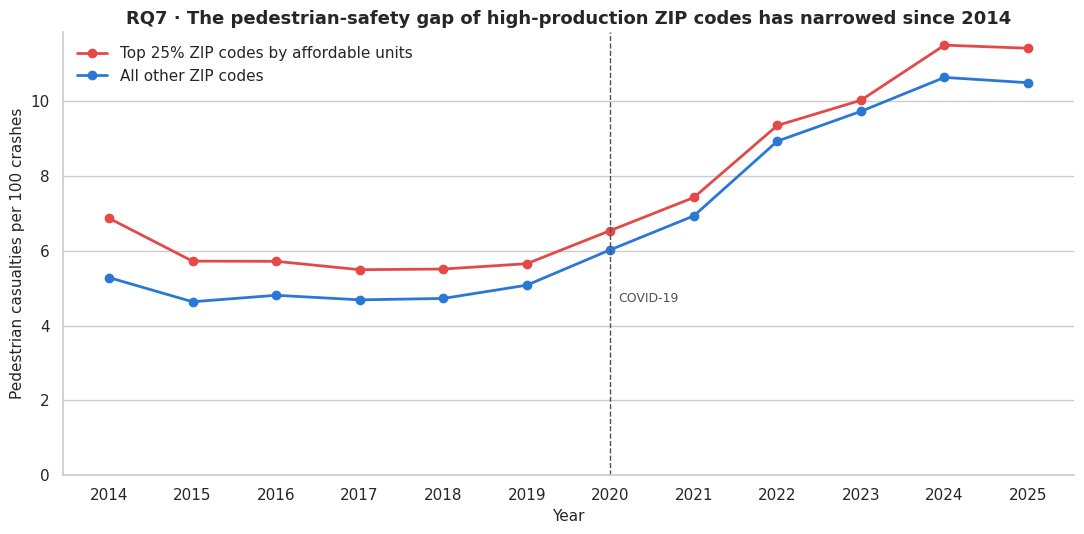

Top-25% threshold: 1,763 affordable units; 47 ZIP codes
group  All other ZIP codes  Top 25% ZIP codes by affordable units  gap (percentage points)
year                                                                                      
2014                 5.290                                  6.880                    1.590
2015                 4.640                                  5.730                    1.090
2016                 4.820                                  5.720                    0.910
2017                 4.690                                  5.500                    0.810
2018                 4.730                                  5.520                    0.790
2019                 5.090                                  5.660                    0.570
2020                 6.030                                  6.550                    0.510
2021                 6.940                                  7.430                    0.490
2022                 8.940        

In [40]:
top_threshold = zip_totals["affordable_units_completed"].quantile(0.75)
top_zips = set(zip_totals.loc[zip_totals["affordable_units_completed"] >= top_threshold, "zip_code"])
gap = (zip_year.assign(group=np.where(zip_year["zip_code"].isin(top_zips), "Top 25% ZIP codes by affordable units",
                                      "All other ZIP codes"))
       .groupby(["year", "group"])[["pedestrian_casualties", "crashes"]].sum())
gap["rate"] = 100 * gap["pedestrian_casualties"] / gap["crashes"]
gap_wide = gap["rate"].unstack()

fig, ax = plt.subplots(figsize=(11, 5.5))
for color, column in zip([PALETTE[7], PALETTE[0]], gap_wide.columns[::-1]):
    ax.plot(gap_wide.index, gap_wide[column], marker="o", linewidth=2, color=color, label=column)
ax.axvline(2020, color="#52514e", linestyle="--", linewidth=1)
ax.annotate("COVID-19", xy=(2020.1, gap_wide.min().min()), fontsize=9, color="#52514e")
ax.set_xticks(FULL_YEARS)
ax.set_xlabel("Year")
ax.set_ylabel("Pedestrian casualties per 100 crashes")
ax.set_ylim(0)
ax.set_title("RQ7 · The pedestrian-safety gap of high-production ZIP codes has narrowed since 2014")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

gap_wide["gap (percentage points)"] = gap_wide.iloc[:, 1] - gap_wide.iloc[:, 0]
print(f"Top-25% threshold: {top_threshold:,.0f} affordable units; {len(top_zips)} ZIP codes")
print(gap_wide.round(2).to_string())

**Answer.** The gap has **narrowed**. In 2014, crashes in the high-production ZIP codes hurt pedestrians noticeably
more often than elsewhere (≈ 6.9 vs 5.3 per 100 crashes, a gap of ≈ 1.6 points); from 2015 on the gap is smaller,
mostly under one point. Meanwhile the rate **roughly doubled everywhere** (to ≈ 10 – 11 per 100 by 2024 – 2025).

**Caution:** the doubling is largely because *reported* crashes fell sharply after 2020 while pedestrian casualties
did not fall as much — more crashes than before involve injury, possibly because fewer minor crashes are reported.
The narrowing gap is a relative pattern; both groups worsened on this measure.

## RQ8 — Renad Osama
### Did cyclist casualties grow faster in ZIP codes that received more affordable housing?

**Why it matters:** cycling and e-bike use grew fast in 2014 – 2025, especially for delivery work, which employs
many lower-income New Yorkers. If cyclist harm grew fastest where affordable housing is concentrated, protected bike
lanes there are an equity issue.
**Method:** per ZIP code, cyclist casualties in 2023 – 2025 divided by those in 2014 – 2016 (ZIP codes with at least
10 cyclist casualties in the first period, to avoid unstable ratios) vs affordable units completed; Spearman test.

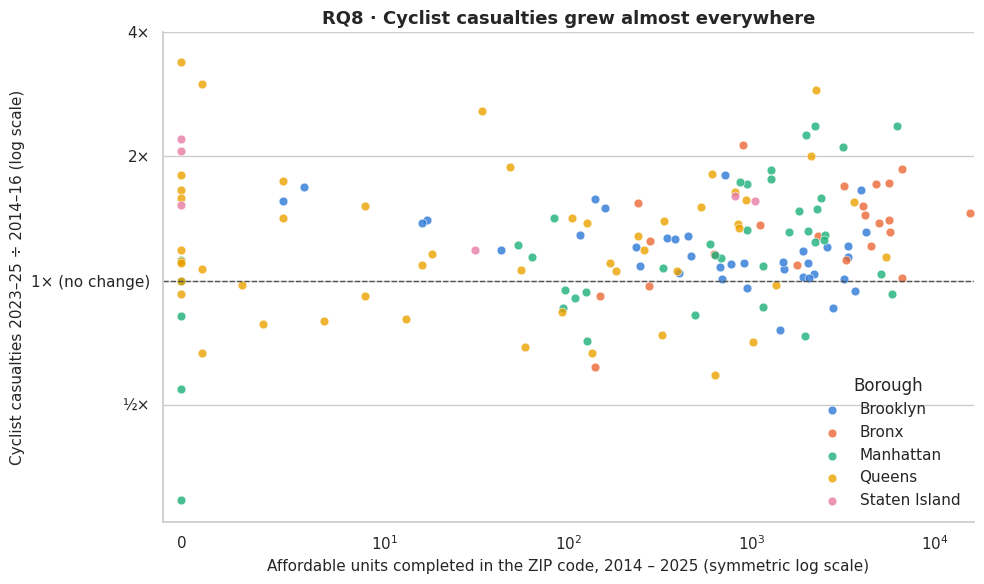

ZIP codes analysed: 156; median growth ratio 1.21; share of ZIP codes where it grew: 78%
Spearman rho = 0.16, p = 0.046


In [41]:
early = zip_year[zip_year["year"].between(2014, 2016)].groupby("zip_code")["cyclist_casualties"].sum()
late = zip_year[zip_year["year"].between(2023, 2025)].groupby("zip_code")["cyclist_casualties"].sum()
cyclist_growth = zip_totals.set_index("zip_code")[["borough", "affordable_units_completed"]].assign(
    early=early, late=late)
cyclist_growth = cyclist_growth[cyclist_growth["early"] >= 10]
cyclist_growth["growth_ratio"] = cyclist_growth["late"] / cyclist_growth["early"]

fig, ax = plt.subplots(figsize=(10, 6))
for borough in BOROUGH_ORDER:
    part = cyclist_growth[cyclist_growth["borough"] == borough]
    ax.scatter(part["affordable_units_completed"], part["growth_ratio"], s=40, alpha=0.8,
               color=BOROUGH_COLORS[borough], label=borough, edgecolor="white", linewidth=0.5)
ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
ax.set_xscale("symlog", linthresh=10)
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 2, 4], ["½×", "1× (no change)", "2×", "4×"])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(left=-0.9)  # small margin so points at 0 are fully visible
ax.set_xlabel("Affordable units completed in the ZIP code, 2014 – 2025 (symmetric log scale)")
ax.set_ylabel("Cyclist casualties 2023–25 ÷ 2014–16 (log scale)")
ax.set_title("RQ8 · Cyclist casualties grew almost everywhere")
ax.legend(title="Borough", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

rho, p_value = stats.spearmanr(cyclist_growth["affordable_units_completed"], cyclist_growth["growth_ratio"])
print(f"ZIP codes analysed: {len(cyclist_growth)}; median growth ratio {cyclist_growth['growth_ratio'].median():.2f}; "
      f"share of ZIP codes where it grew: {(cyclist_growth['growth_ratio'] > 1).mean():.0%}")
print(f"Spearman rho = {rho:.2f}, p = {p_value:.3f}")

**Answer.** Cyclist casualties **grew in most ZIP codes** (median ≈ 1.2× between 2014 – 16 and 2023 – 25), and the
growth is only **weakly** related to affordable housing production (Spearman ρ ≈ 0.16, p ≈ 0.05 — borderline).

**Reading it correctly:** the rise in cyclist harm is a citywide phenomenon (more cycling and e-bikes everywhere);
neighbourhoods with heavy affordable production are at most slightly more affected. This does not support targeting
bike-safety investment by housing production alone.

## RQ9 — Yassin Amr
### Which vehicle types are over-represented in crashes near affordable housing?

**Why it matters:** heavy vehicles (buses, trucks) cause more severe injuries; bicycles and e-bikes signal people
travelling without a car. The vehicle mix near residents' homes shows which modes to design for.
**Method:** share of crashes involving each vehicle category (as vehicle 1 or 2, Section 4 categories), near vs far.

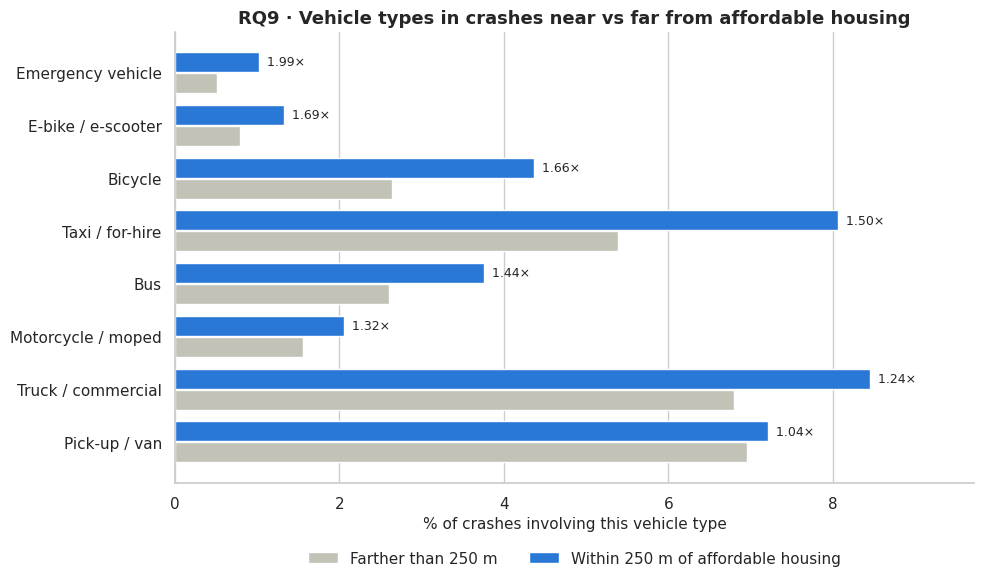

                    Farther than 250 m  Within 250 m of affordable housing  ratio near / far
Pick-up / van                    6.950                               7.210             1.040
Truck / commercial               6.790                               8.450             1.240
Motorcycle / moped               1.560                               2.060             1.320
Bus                              2.600                               3.750             1.440
Taxi / for-hire                  5.380                               8.060             1.500
Bicycle                          2.630                               4.370             1.660
E-bike / e-scooter               0.790                               1.330             1.690
Emergency vehicle                0.520                               1.030             1.990


In [42]:
categories = ["Bus", "Truck / commercial", "Taxi / for-hire", "Bicycle", "E-bike / e-scooter",
              "Motorcycle / moped", "Emergency vehicle", "Pick-up / van"]
mix = pd.DataFrame({
    near: [((group["vehicle_category_1"] == cat) | (group["vehicle_category_2"] == cat)).mean() * 100
           for cat in categories]
    for near, group in crashes_located.groupby("near_affordable")}, index=categories).rename(columns=NEAR_LABELS)
mix["ratio near / far"] = mix.iloc[:, 1] / mix.iloc[:, 0]
mix = mix.sort_values("ratio near / far")

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(mix))
ax.barh(y - 0.2, mix[NEAR_LABELS[False]], height=0.38, color="#c3c2b7", label=NEAR_LABELS[False])
ax.barh(y + 0.2, mix[NEAR_LABELS[True]], height=0.38, color=PALETTE[0], label=NEAR_LABELS[True])
for yi, (value, ratio) in enumerate(zip(mix[NEAR_LABELS[True]], mix["ratio near / far"])):
    ax.text(value, yi + 0.2, f"  {ratio:.2f}×", va="center", fontsize=9)
ax.set_yticks(y, mix.index)
horizontal_bar_grid(ax)
ax.set_xlim(0, mix[NEAR_LABELS[True]].max() * 1.15)
ax.set_xlabel("% of crashes involving this vehicle type")
ax.set_title("RQ9 · Vehicle types in crashes near vs far from affordable housing")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

print(mix.round(2).to_string())

**Answer.** Near affordable housing, crashes are clearly more likely to involve **emergency vehicles (≈ 2.0×),
e-bikes/e-scooters (≈ 1.7×), bicycles (≈ 1.7×), taxis/for-hire vehicles (≈ 1.5×) and buses (≈ 1.4×)**, while
pick-ups and vans are about equally common.

**Reading it correctly:** these are the vehicles of dense, transit-rich, car-light neighbourhoods — exactly where
affordable housing is built. It shows residents share their streets with heavy buses and fast e-bikes, which supports
bus-stop and bike-lane safety design around affordable housing, but it is not a causal effect of the buildings.

## RQ10 — Yassin Amr
### Where do heavy affordable-housing production and high pedestrian danger overlap?

**Why it matters:** a short, concrete list of neighbourhoods where both conditions hold is directly actionable for
NYC DOT and HPD.
**Method:** each ZIP code is placed at the median location of its crashes; bubble size = affordable units completed
(2014 – 2025), colour = pedestrian casualties per 100 crashes. **Hotspots** = top 25% on both measures (black outline).

> **Decision — ZIP code positions from crash locations, not boundary files.** *Alternatives considered:* ZIP-code
> (ZCTA) polygons for a choropleth. *Why:* the polygons are an extra external dataset; the median crash location of a
> ZIP code is a robust centre point computed from our own data, and enough for a bubble map.

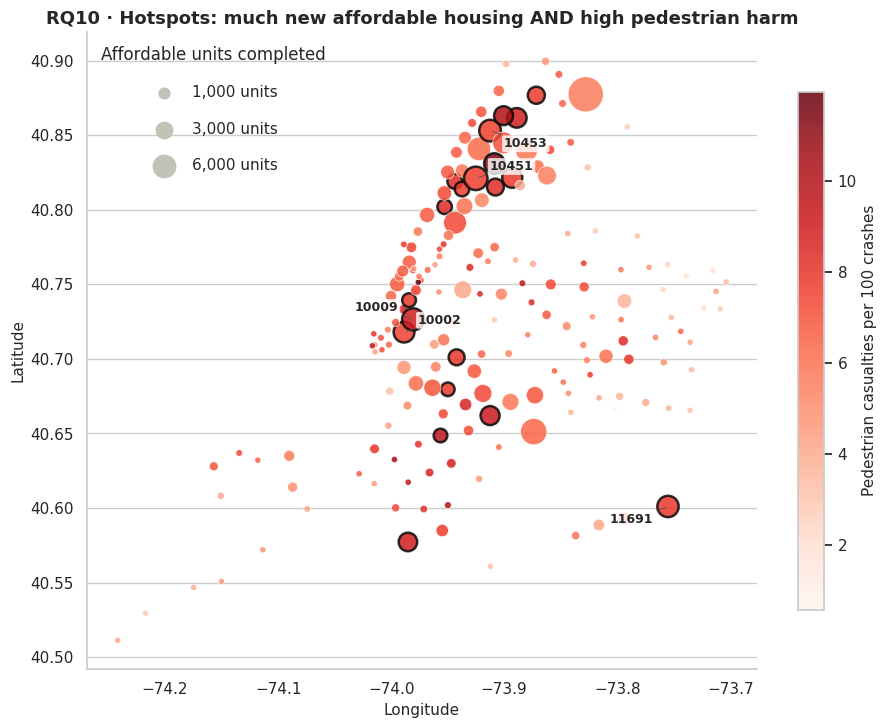

Hotspot thresholds: >= 1,763 units and >= 7.47 pedestrian casualties per 100 crashes
20 hotspot ZIP codes: {'Bronx': 8, 'Manhattan': 6, 'Brooklyn': 5, 'Queens': 1}


,zip_code,borough,affordable_units_completed,ped_casualties_per_100_crashes
59,10451,Bronx,6631,7.610
7,10009,Manhattan,5812,8.990
61,10453,Bronx,5587,7.550
180,11691,Queens,5397,7.880
1,10002,Manhattan,5103,7.490
64,10456,Bronx,4967,11.270
67,10459,Bronx,4748,7.870
66,10458,Bronx,4475,8.810
105,11212,Brooklyn,4188,9.110
76,10468,Bronx,4143,10.180


In [43]:
zip_centres = (collisions.dropna(subset=["zip_code", "latitude"]).groupby("zip_code")[["latitude", "longitude"]]
               .median())
zip_map = zip_totals.merge(zip_centres, left_on="zip_code", right_index=True, how="left")
units_q3 = zip_map["affordable_units_completed"].quantile(0.75)
rate_q3 = zip_map["ped_casualties_per_100_crashes"].quantile(0.75)
zip_map["hotspot"] = (zip_map["affordable_units_completed"] >= units_q3) & (zip_map["ped_casualties_per_100_crashes"] >= rate_q3)

fig, ax = plt.subplots(figsize=(9.5, 9))
points = ax.scatter(zip_map["longitude"], zip_map["latitude"], s=20 + zip_map["affordable_units_completed"] / 25,
                    c=zip_map["ped_casualties_per_100_crashes"], cmap="Reds", alpha=0.85,
                    edgecolor=np.where(zip_map["hotspot"], "#0b0b0b", "white"),
                    linewidth=np.where(zip_map["hotspot"], 1.8, 0.5))
label_offsets = [(10, 6), (-42, 6), (10, -12), (-42, -12), (10, 6)]
for offset, (_, row) in zip(label_offsets, zip_map[zip_map["hotspot"]].nlargest(5, "affordable_units_completed").iterrows()):
    ax.annotate(row["zip_code"], (row["longitude"], row["latitude"]), xytext=offset, textcoords="offset points",
                fontsize=9, fontweight="bold", arrowprops={"arrowstyle": "-", "color": "#52514e", "linewidth": 0.6},
                bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.8})
plt.colorbar(points, ax=ax, shrink=0.6, label="Pedestrian casualties per 100 crashes")
for size in [1000, 3000, 6000]:
    ax.scatter([], [], s=20 + size / 25, color="#c3c2b7", label=f"{size:,} units")
ax.legend(title="Affordable units completed", frameon=False, loc="upper left", labelspacing=1.4)
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("RQ10 · Hotspots: much new affordable housing AND high pedestrian harm")
plt.tight_layout()
plt.show()

print(f"Hotspot thresholds: >= {units_q3:,.0f} units and >= {rate_q3:.2f} pedestrian casualties per 100 crashes")
hotspots = zip_map[zip_map["hotspot"]].sort_values("affordable_units_completed", ascending=False)
print(f"{len(hotspots)} hotspot ZIP codes:", hotspots["borough"].value_counts().to_dict())
hotspots[["zip_code", "borough", "affordable_units_completed", "ped_casualties_per_100_crashes"]].round(2)

**Answer.** **20 ZIP codes** are hotspots — top quarter for both new affordable units and pedestrian harm per crash.
Eight are in the **Bronx** (from the South Bronx — 10451, 10455, 10456, 10459 — north to 10467 and 10468), six in
**Manhattan** (Harlem — 10026, 10030, 10037 — and the Lower East Side / East Village — 10002, 10009 — plus 10010),
five in **Brooklyn** (e.g., Brownsville 11212, Coney Island 11224) and one in **Queens** (the Rockaways, 11691).

**Use:** this list is a concrete shortlist where HPD's housing pipeline and NYC DOT's Vision Zero priorities overlap.
"Hotspot" uses a per-crash rate; it identifies where crashes are most harmful to pedestrians, not where most residents
are hurt per capita.

## RQ11 — Yassin Elazab
### Within the same ZIP code, are crashes near affordable buildings more likely to hurt a pedestrian than crashes farther away?

**Why it matters:** RQ1 compares *different* neighbourhoods, which differ in many ways. Comparing near vs far
**inside the same ZIP code** holds the neighbourhood constant and asks whether the blocks around affordable housing
are specifically worse.
**Method:** for each ZIP code with at least 200 crashes on each side, the share of crashes that hurt a pedestrian near
(≤ 250 m) minus far; Wilcoxon signed-rank test across ZIP codes (H₀: median difference = 0).

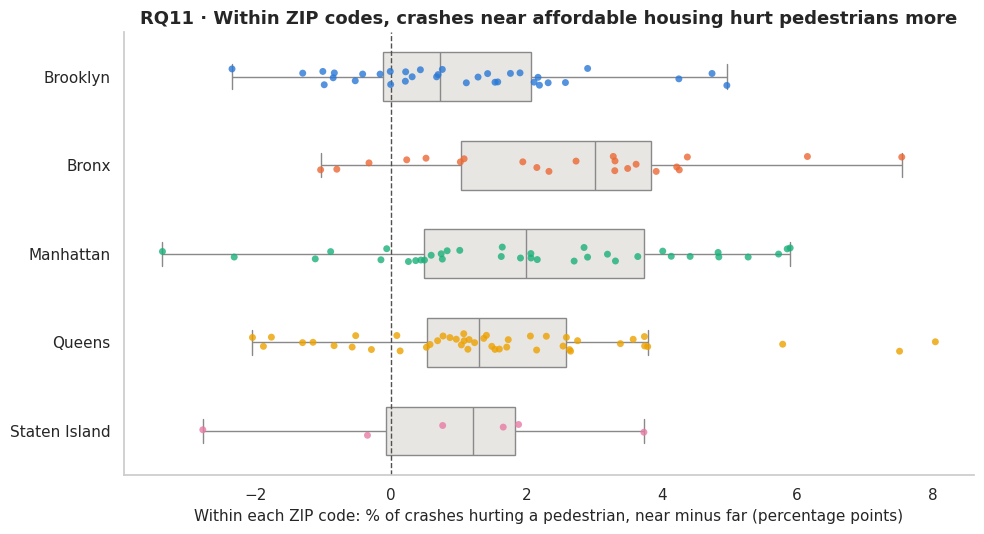

ZIP codes compared: 144; median difference +1.51 pp; positive in 78% of ZIP codes; Wilcoxon p = 1.4e-14


In [44]:
within = (crashes_located.dropna(subset=["zip_code"])
          .groupby(["zip_code", "near_affordable"])["hurts_pedestrian"].agg(["size", "mean"]).unstack())
within = within[(within[("size", True)] >= 200) & (within[("size", False)] >= 200)]
within_diff = pd.DataFrame({"difference_pp": (within[("mean", True)] - within[("mean", False)]) * 100}) \
    .join(zip_totals.set_index("zip_code")["borough"])

fig, ax = plt.subplots(figsize=(10, 5.5))
order = [b for b in BOROUGH_ORDER if b in set(within_diff["borough"])]
sns.boxplot(data=within_diff, x="difference_pp", y="borough", order=order, ax=ax, showfliers=False,
            color="#e8e7e2", width=0.55)
sns.stripplot(data=within_diff, x="difference_pp", y="borough", order=order, ax=ax, hue="borough",
              palette=BOROUGH_COLORS, size=5, alpha=0.8, legend=False)
ax.axvline(0, color="#52514e", linestyle="--", linewidth=1)
ax.set_xlabel("Within each ZIP code: % of crashes hurting a pedestrian, near minus far (percentage points)")
ax.set_ylabel("")
ax.set_title("RQ11 · Within ZIP codes, crashes near affordable housing hurt pedestrians more")
plt.tight_layout()
plt.show()

test = stats.wilcoxon(within_diff["difference_pp"])
print(f"ZIP codes compared: {len(within_diff)}; median difference {within_diff['difference_pp'].median():+.2f} pp; "
      f"positive in {(within_diff['difference_pp'] > 0).mean():.0%} of ZIP codes; Wilcoxon p = {test.pvalue:.1e}")

**Answer.** **Yes — the strongest result of the project.** Even inside the same ZIP code, crashes within 250 m of an
affordable building hurt a pedestrian more often than crashes farther away: the median difference is **+1.5
percentage points**, positive in **≈ 78%** of the 144 ZIP codes compared (Wilcoxon p < 0.001), in every borough.

**Reading it correctly:** affordable housing sits on the more pedestrian-heavy blocks of its own neighbourhood
(transit stops, shopping streets, schools). The blocks around affordable buildings — not just the neighbourhoods —
deserve pedestrian-safety priority. It remains an association, not proof that the buildings cause harm.

## RQ12 — Yassin Elazab
### Does a year of heavy affordable-housing completion in a ZIP code predict a change in its crashes the following year?

**Why it matters:** if completions predicted next year's crash growth, DOT could use HPD's pipeline as an **early
warning** and act before crashes rise.
**Method:** for every ZIP-year (ZIP codes with ≥ 50 crashes that year), crash growth from year *t* to *t + 1* divided
by citywide growth in the same years (1 = same as the city), vs affordable units completed in year *t*; Spearman test.

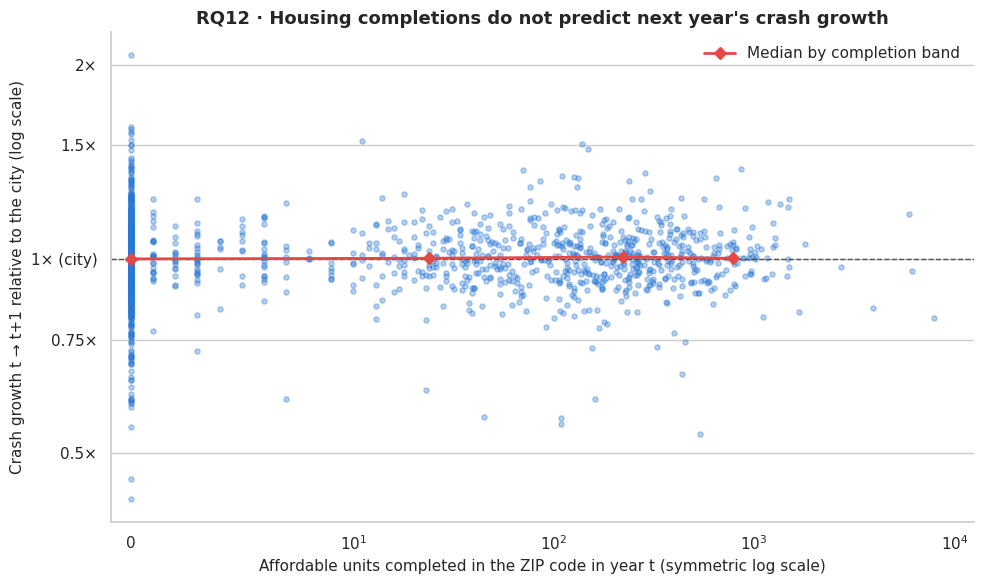

ZIP-years: 1,918; Spearman rho = 0.021, p = 0.36
                      x     y     n
completion_band                    
0                 0.000 1.001  1116
1–100            24.000 1.003   370
101–500         221.500 1.008   330
> 500           783.500 1.003   102


In [45]:
panel = zip_year.sort_values(["zip_code", "year"]).copy()
panel["crashes_next_year"] = panel.groupby("zip_code")["crashes"].shift(-1)
city_growth = panel.groupby("year")["crashes"].sum()
city_growth = city_growth.shift(-1) / city_growth
panel["relative_growth"] = (panel["crashes_next_year"] / panel["crashes"]) / panel["year"].map(city_growth)
panel = panel.dropna(subset=["relative_growth"])
panel = panel[panel["crashes"] >= 50]

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(panel["affordable_units_completed"], panel["relative_growth"], s=14, alpha=0.35, color=PALETTE[0])
ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
bins = [-1, 0, 100, 500, panel["affordable_units_completed"].max()]
labels = ["0", "1–100", "101–500", "> 500"]
panel["completion_band"] = pd.cut(panel["affordable_units_completed"], bins, labels=labels)
medians = panel.groupby("completion_band", observed=True).agg(x=("affordable_units_completed", "median"),
                                                               y=("relative_growth", "median"), n=("relative_growth", "size"))
ax.plot(medians["x"], medians["y"], color=PALETTE[7], marker="D", linewidth=2, label="Median by completion band")
ax.set_xscale("symlog", linthresh=10)
ax.set_yscale("log")
ax.set_yticks([0.5, 0.75, 1, 1.5, 2], ["0.5×", "0.75×", "1× (city)", "1.5×", "2×"])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(left=-0.9)  # small margin so points at 0 are fully visible
ax.set_xlabel("Affordable units completed in the ZIP code in year t (symmetric log scale)")
ax.set_ylabel("Crash growth t → t+1 relative to the city (log scale)")
ax.set_title("RQ12 · Housing completions do not predict next year's crash growth")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

rho, p_value = stats.spearmanr(panel["affordable_units_completed"], panel["relative_growth"])
print(f"ZIP-years: {len(panel):,}; Spearman rho = {rho:.3f}, p = {p_value:.2f}")
print(medians.round(3).to_string())

**Answer.** **No.** Next year's crash growth is essentially unrelated to how many affordable units a ZIP code completed
(Spearman ρ ≈ 0.02, p ≈ 0.36); the median ZIP-year grows like the city whether it completed 0, a hundred, or more than
500 units.

**What this means:** together with RQ3, the data give no sign that new affordable housing *raises* crash levels.
The problem the project finds (RQ1, RQ10, RQ11) is **where** the housing is — on streets that were already
hazardous for pedestrians — not what it does to them. A pipeline-based early warning would not work; a
location-based safety review would.

---
# 9. The Data Story

### The question
*Are New York's newest affordable homes being built on the city's most dangerous streets — and does safety change
once residents move in?* Households in deeply affordable units are the least likely to own a car; if their streets are
the most dangerous for people on foot, they carry the risk with the fewest alternatives.

### The data
* **HPD Affordable Housing Production by Building** — 9,551 building records (2014 – 2026), of which 7,470 unique
  buildings could be mapped (1,949 records are confidential, mostly single-unit homes, without an address).
* **NYPD Motor Vehicle Collisions – Crashes** — 1,964,900 crashes since 2014; 1,963,310 after removing double-entered
  reports.
* **Connected** in three ways: ZIP code × year (12 full years, 185 residential ZIP codes), a 250 m buffer around every
  building (with 24-month before/after windows), and each crash's distance to the nearest affordable building.
* **Cleaned / assumed / left out:** swapped columns renamed; hidden missing values (`Unspecified`, `----`, million-BINs,
  (0, 0) coordinates, `0:00` times) exposed; 463 k missing ZIP codes recovered from coordinates with a validated
  nearest-neighbour model (99.6% hold-out accuracy); empty unit counts proven to mean 0; 8% of crashes that have
  neither coordinates nor a ZIP code, 48 non-residential ZIP codes, and the partial year 2026 left out of the
  integrated analysis.

### The discovery
1. **Affordable housing is concentrated where crashes hurt pedestrians most.** ZIP codes with more new affordable
   units have crashes that injure or kill pedestrians far more often (7.2 vs 4.3 per 100 crashes between the top and
   bottom quarters; ρ ≈ 0.45) — RQ1. **20 hotspot ZIP codes** combine both, mostly in the Bronx, Harlem / the Lower
   East Side and central Brooklyn — RQ10.
2. **The blocks around affordable buildings are worse than the rest of their own neighbourhood.** Within the same
   ZIP code, crashes within 250 m of an affordable building hurt a pedestrian more often in 78% of ZIP codes
   (+1.5 percentage points, p < 0.001) — RQ11. Those streets carry more buses, taxis, bicycles and e-bikes (RQ9) and
   relatively more late-night pedestrian crashes (RQ5).
3. **New construction is sited on busier streets than preservation** — the median is higher in every borough and the
   difference is significant in four of five; streets around new buildings in Queens are more than twice as busy (RQ4).

### What surprised us
* **Housing does not appear to *make* streets more dangerous.** Crashes around newly completed buildings change at
  the same pace as the citywide trend (RQ3), and a year of heavy completions does not predict next year's crash growth
  (RQ12). The problem is *where* homes are built, not what they do to the street.
* **The poorest households are not singled out within the affordable stock** — deeply affordable buildings are about as
  exposed as other affordable buildings (RQ2). The gap is between neighbourhoods, not between income bands.
* The pedestrian-safety **gap** of high-production ZIP codes has **narrowed** since 2014 (RQ7), but pedestrian harm per
  crash **doubled citywide** as reported crashes fell after 2020.

### The limits — what this data cannot tell us
* **Correlation, not causation.** Dense, transit-rich, walkable neighbourhoods have both more affordable housing and
  more pedestrian crashes; our measures show *co-location*, not that one causes the other.
* **No population or traffic volume.** Rates are per crash, not per resident or per vehicle-mile, because neither
  dataset contains population or exposure; a busier street naturally has more crashes.
* **Reporting changes over time.** Police reporting of minor crashes fell after 2020, inflating injury shares in later
  years; contributing factors reflect officers' judgement.
* **Location quality.** 8% of crashes could not be located; recovered ZIP codes are ≈ 99.6% (not 100%) accurate;
  confidential homeownership records (20%) cannot be mapped.
* **Timing.** Completion dates may precede full occupancy, and 24 months may be too short to see slow changes.

### The impact — who can use this, and what should they do differently
* **NYC DOT / Vision Zero:** add the 20 hotspot ZIP codes, and the 250 m blocks around affordable buildings, to
  pedestrian-safety prioritisation — with emphasis on night-time measures (lighting, speed control), bus-stop safety
  and protected space for bikes and e-bikes.
* **HPD and developers:** include a street-safety review in site selection and project approval — especially for new
  construction on arterial sites (RQ4) — and coordinate with DOT so improvements arrive **with** the residents.
* **Housing and safety advocates:** use the hotspot list and building-level exposure to argue for safety investment
  where low-income New Yorkers live — the data show the need is about location, so funding should follow location.

---
# 10. Member Contributions

| Member | Research questions & visualizations | Data cleaning | Integration | Website components | Other |
|---|---|---|---|---|---|
| **Ahmed Saadallah** (16008325) | RQ1 (scatter), RQ2 (box plot) | Housing hidden missing values & formats (H1) | Integration design (Section 2.5) | Search mode (free-text query → filters); deployment | Dataset selection & overview (Section 2), project coordination |
| **Ismail Ahmed Mohamed** (16002979) | RQ3 (histogram), RQ4 (grouped bar) | Casualty consistency & outliers (C6) | 250 m spatial join, before/after windows (5.2) | "Generate Report" button and report callbacks | Statistical tests |
| **Ziad Elshayeb** (16002080) | RQ5 (diverging heatmap), RQ6 (diverging bar) | Collisions structure, formats & categories (C1 – C3) | Crash-level distance to nearest building (5.3) | Time-pattern charts (heatmap) | Collisions EDA (3.1) |
| **Renad Osama** (16001737) | RQ7 (line chart), RQ8 (scatter) | Housing unit counts & dates (H2 – H3) | ZIP × year aggregation (5.1) | Trend charts and story section | Data story (Section 9) |
| **Yassin Amr** (16005309) | RQ9 (grouped bar), RQ10 (bubble map) | Duplicates, coordinates, time flags (C4, C5, C7) | ZIP/borough recovery with k-NN (C8) | Interactive map | Visual style (palette, chart conventions) |
| **Yassin Elazab** (16006124) | RQ11 (box + strip plot), RQ12 (scatter) | Housing duplicates & domain checks (H4) | Post-integration cleaning & validation (Sections 6 – 7) | Dropdown filters and page layout | Housing EDA (3.2), README |

---
# 11. Prompts Used & Dataset Links

### Dataset links
* Affordable Housing Production by Building (`hg8x-zxpr`):
  https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr
* Motor Vehicle Collisions – Crashes (`h9gi-nx95`):
  https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95
* API endpoints used: `https://data.cityofnewyork.us/resource/hg8x-zxpr.csv`,
  `https://data.cityofnewyork.us/resource/h9gi-nx95.csv` (snapshot downloaded on 2026-10-14).

### Prompts used
An AI assistant (Claude, by Anthropic) was used for planning, code drafting, verification and writing. Every result
in this notebook was produced by the code shown and checked against the data; numbers in the text were verified
against the cell outputs. The prompts, in order:

| # | Step | Prompt | Used for |
|---|---|---|---|
| 1 | Planning | "I wanna start doing this project. First lets decide the plan and after agreeing on it lets start execution step by step and don't move on to the next step until I confirm the previous. The most important thing is the accuracy …" (with the project description and data catalog attached) | Reading the requirements; project plan |
| 2 | Planning | "what is the main idea of the project ?" | Summary of the project goal |
| 3 | Dataset selection | "what are the available options on datasets and why did you pick those" | Comparison of all catalog datasets; choice of H2 + T4 |
| 4 | Dataset selection | "can you get all marks from these ?" | Check of the pair against every grading criterion |
| 5 | Setup | "confirm the dataset and keep the dash+render for now …" | Repository structure, notebook header and setup (Section 1) |
| 6 | Setup review | "what did that mean till now ?" | Explanation of the setup cells |
| 7 | Loading | "next" / "I wanna continue one by one … tell me whether it contains code or text … and explain every cell" | Section 2: download helpers, filter justification, snapshot |
| 8 | Overview | (raw data files attached) | Profiling the snapshot; Sections 2.3 – 2.5 |
| 9 | EDA | "go to it and make your explanation more summarized" / "can we make a little compact cells ?" | Section 3 |
| 10 | EDA correction | "where is cell 11 and 12 ?" | Correction: affordable units = `all_counted_units` (data dictionary) |
| 11 | Cleaning | "done" (confirming Section 3) | Section 4 |
| 12 | Full notebook | "now lets change the plan I need you to make the full notebook for me … highlight each decision you take and what did we have replacements … make sure that we will get 100% of the grades …" | Sections 5 – 12, decision callouts, final review |

---
# 12. Decision Register

Every analytical decision in the notebook, with the alternatives that were considered (each is explained in place,
marked **Decision —**).

| Section | Decision | Alternatives considered | Why |
|---|---|---|---|
| 2.1 | Load via the SODA API, page by page, with a row-count check | Bulk CSV export | Consistent names, server-side filtering, verifiable completeness |
| 2.1 | Keep every raw column as text; convert in Section 4 | Let pandas infer types | No silent damage (ZIP codes as floats, bad dates as NaN) |
| 2.1 | Cache the raw snapshot as Parquet (on Google Drive) | Re-download every run | Same snapshot for the whole team; fast re-runs |
| 2.2 | Filter crashes to 2014+ (keep all of them) | Random sample; full history | Matches housing period; no sampling bias; fits in memory |
| 3 | Explore on typed working copies | Change the raw data during EDA | Raw stays untouched; conversions documented once |
| 4 C1 | Rename the swapped street columns; drop `location` | Keep API names; keep `location` | Metadata + counts + examples agree; `location` is identical to lat/lon |
| 4 C2 | ZIP code as 5-character text; invalid ZIPs → missing | Numeric ZIP | A ZIP is a label; invalid values are recovered later |
| 4 C3 | `Unspecified`/numeric factor codes → missing; 11 vehicle categories | Keep as categories; manual mapping of 1,905 values | Not real causes; ordered rules cover ≥ 99.8% |
| 4 C4 | Drop 1,590 duplicate reports, keep lowest ID | Keep all | Identical in all 28 fields |
| 4 C5 | Invalid coordinates → missing, crash kept | Drop the crash | Location invalid, crash valid |
| 4 C6 | Missing/low totals ← sum of parts; keep extreme injury counts | Drop rows; IQR outlier removal | Deterministic reconstruction; IQR flags real crashes; extremes are bus crashes |
| 4 C7 | Flag `0:00` times and the partial year | Delete them | Only some analyses are affected |
| 4 C8 | Recover ZIP/borough by k-NN on coordinates (validated, flagged) | Drop; ZIP polygons | Keeps 463 k crashes; 99.6% hold-out accuracy; no external data |
| 4 H1 | Placeholders → missing; drop internal coordinates | Keep | Placeholders are not values; internal pair is 31 m away and redundant |
| 4 H2 | Empty unit counts → 0 | Drop; mean imputation | No explicit zeros + all sums match exactly |
| 4 H3 | Missing completion = "In progress"; flag date inversions | Impute dates; drop | Meaningful absence; administrative dates |
| 4 H4 | Keep buildings in several projects (flagged); domain checks instead of IQR | Drop repeats; IQR | Different projects; large buildings are real |
| 5 | Full years 2014 – 2025 only | Include / annualize 2026 | Partial year would look like a collapse |
| 5 | Housing measured at completion | Start year | Residents arrive at completion |
| 5.2 | 250 m buffer, one row per building, haversine BallTree | 150 m / 500 m; per project record | Walking scale; no double counting; exact distances |
| 5.2 | 24-month windows relative to the citywide change | 12 months; raw difference | Enough crashes; removes the COVID trend |
| 6 | Join-induced gaps → 0 only where 0 is true | Drop; impute | No-housing ZIP-years are the comparison group |
| 6 | Remove non-residential ZIP codes (< 120 crashes / 12 y, and 10000) | Keep all; population threshold | Building / park ZIP codes are not neighbourhoods; no population data |
| 6 | Rates missing when crashes = 0 | 0 or drop | 0 / 0 is undefined |
| 6 | One borough per ZIP (crash-based) | Housing-based borough | Exists for every ZIP; geographic majority |
| 6 | Before/after kept missing + flag when not observed | Fill with 0; drop buildings | Not observed ≠ zero crashes |
| 8 | Non-parametric tests; per-crash rates | t-tests; per-capita rates | Skewed counts; no population data |
| 8 RQ10 | ZIP positions from median crash location | ZIP polygons | No external data needed |